# Phase 1 reward-aligned experimental design

**SO reward (both policies):** `reward = DL_norm_post` (no improvement shaping). **MO reward (both policies):** `0.50*r_DL + 0.15*r_RSRP + 0.15*r_RSRQ + 0.10*r_RSSI + 0.08*r_CQI + 0.02*r_SNR`. There are **no proactive forecast bonuses or volume-preservation bonuses/penalties**. The Fused policy sees the ensemble forecast as an additional state input; Reactive does not. Both use the same six actions, action effects, training configuration, trace, normalization, and evaluation starts. Simulated normalized DL can exceed 1; KPI and discretization bounds remain as originally defined. The 20-segment results are within one RL training trace, not a held-out RL generalization experiment.

# Ensemble-Fused Proactive Adaptive AI Systems
Single Objective (SO) Fused vs Multi-Objective (MO) Fused 5G DL throughput Optimization Agents

PhD Title: Adaptive AI Systems For Forecasting and Improving Communication Outcomes

# Imports and Configuration

Imports for the pipeline (pandas/numpy, scikit-learn, LightGBM, PyTorch) plus global constants: horizon, lags, train fraction, covariates.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import time
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb

# Deep Learning
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Time Series
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima

# set seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Device configuration
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

# CONFIGURATION - Matching Paper's Settings (No Min Trace Length)

DATA_FOLDER = '5G-production-dataset'
HORIZON = 10
TRAIN_FRAC = 0.80
N_LAGS = 5

COVARIATES = ['RSRP', 'RSRQ', 'SNR', 'CQI', 'RSSI', 'Speed']
TARGET = 'DL_Mbps'

print("="*70)
print("CONFIGURATION SUMMARY")
print("="*70)
print(f"Data folder: {DATA_FOLDER}")
print(f"Prediction horizon: {HORIZON} steps")
print(f"Train fraction: {TRAIN_FRAC}")
print(f"Number of lags: {N_LAGS}")
print(f"Covariates: {COVARIATES}")

Device: cpu
CONFIGURATION SUMMARY
Data folder: 5G-production-dataset
Prediction horizon: 10 steps
Train fraction: 0.8
Number of lags: 5
Covariates: ['RSRP', 'RSRQ', 'SNR', 'CQI', 'RSSI', 'Speed']


# Load Original 83 Traces

Walks the dataset folder and loads all 83 raw per-trace CSVs before any filtering, same as the baseline notebook.


In [2]:
print("="*70)
print("LOADING 5G PRODUCTION DATASET (83 Traces)")
print("="*70)

traces = []
trace_ids = []
trace_metadata = []

for root, dirs, files in os.walk(DATA_FOLDER):
    if root == DATA_FOLDER:
        continue
    
    csv_files = sorted([f for f in files if f.endswith('.csv')])
    if not csv_files:
        continue
    
    rel_path = os.path.relpath(root, DATA_FOLDER)
    folder_parts = rel_path.split(os.sep)
    
    app_type = folder_parts[0] if len(folder_parts) > 0 else 'unknown'
    mobility = folder_parts[1] if len(folder_parts) > 1 else 'unknown'
    content = folder_parts[2] if len(folder_parts) > 2 else 'unknown'
    
    for filename in csv_files:
        filepath = os.path.join(root, filename)
        try:
            df = pd.read_csv(filepath)
            if df.empty:
                continue
            
            trace_id = f"{app_type}_{mobility}_{content}_{filename.replace('.csv', '')}"
            traces.append(df)
            trace_ids.append(trace_id)
            trace_metadata.append({
                'app': app_type,
                'mobility': mobility,
                'content': content,
                'filename': filename,
                'n_rows': len(df)
            })
            print(f"  ✅ {trace_id} ({len(df)} rows)")
        except Exception as e:
            print(f"  ❌ Error: {filename} - {e}")

print(f"\nTotal 5G traces loaded: {len(traces)}")

LOADING 5G PRODUCTION DATASET (83 Traces)
  ✅ Amazon_Prime_Static_animated-Ninjago_B_2020.01.06_09.55.13 (3739 rows)
  ✅ Amazon_Prime_Static_animated-Ninjago_B_2020.01.06_11.08.12 (1614 rows)
  ✅ Amazon_Prime_Static_animated-Ninjago_B_2020.01.06_11.40.29 (6581 rows)
  ✅ Amazon_Prime_Static_Season3-TheExpanse_B_2019.12.19_15.00.47 (2293 rows)
  ✅ Amazon_Prime_Static_Season3-TheExpanse_B_2019.12.23_10.30.35 (6992 rows)
  ✅ Amazon_Prime_Static_Season3-TheExpanse_B_2020.01.03_08.59.40 (6143 rows)
  ✅ Amazon_Prime_Static_Season3-TheExpanse_B_2020.01.03_10.54.39 (5295 rows)
  ✅ Amazon_Prime_Static_Season3-TheExpanse_B_2020.01.05_14.55.57 (2284 rows)
  ✅ Amazon_Prime_Driving_animated-AdventureTime_B_2019.11.28_07.27.57 (1898 rows)
  ✅ Amazon_Prime_Driving_animated-AdventureTime_B_2019.11.28_10.14.25 (1320 rows)
  ✅ Amazon_Prime_Driving_animated-AdventureTime_B_2019.11.28_12.05.29 (963 rows)
  ✅ Amazon_Prime_Driving_animated-AdventureTime_B_2019.11.28_14.53.29 (4683 rows)
  ✅ Amazon_Prime_Driv

# Preprocess Traces (Paper's Methodology)

Timestamp parsing, duplicate removal, missing-value handling, and Kbps→Mbps conversion. No row-level filtering is applied — zero-throughput rows are kept as real observations, not dropped.


In [3]:

import re

def parse_timestamp(ts_str):
    """Parse timestamp in format %Y.%m.%d_%H.%M.%S"""
    try:
        return pd.to_datetime(ts_str, format='%Y.%m.%d_%H.%M.%S', errors='coerce')
    except:
        return pd.NaT

def preprocess_trace_with_reporting(df, trace_id, stats):
    """
    Preprocess a trace with detailed statistics tracking.
    """
    
    stats['traces_loaded'] += 1
    
    # 1. Copy and handle timestamps
    df_clean = df.copy()
    
    if 'Timestamp' in df_clean.columns:
        # parse timestamps
        df_clean['Timestamp'] = df_clean['Timestamp'].apply(parse_timestamp)
        
        # count before dedup
        rows_before = len(df_clean)
        df_clean = df_clean.dropna(subset=['Timestamp'])
        df_clean = df_clean.sort_values('Timestamp')
        
        # remove duplicates (keep first)
        before_dedup = len(df_clean)
        df_clean = df_clean.drop_duplicates(subset=['Timestamp'], keep='first')
        after_dedup = len(df_clean)
        stats['duplicate_rows_removed'] += (before_dedup - after_dedup)
        stats['rows_after_dedup'] += after_dedup
        stats['rows_before_dedup'] += before_dedup
    
    # 2. Convert to Mbps
    if 'DL_bitrate' in df_clean.columns:
        df_clean['DL_Mbps'] = df_clean['DL_bitrate'] / 1000
    elif 'DL_Mbps' in df_clean.columns:
        pass
    else:
        return None
    
    # 3. Handle missing values (paper's approach)
    numeric_cols = ['DL_Mbps'] + COVARIATES
    missing_filled = 0
    
    for col in numeric_cols:
        if col in df_clean.columns:
            # convert to numeric (handling placeholders like '-')
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
            
            # count missing
            missing_count = df_clean[col].isnull().sum()
            
            if missing_count > 0:
                # Linear interpolation for internal gaps
                df_clean[col] = df_clean[col].interpolate(method='linear', limit_direction='both')
                # Forward fill for edge cases
                df_clean[col] = df_clean[col].ffill()
                # Backward fill
                df_clean[col] = df_clean[col].bfill()
                # Zero imputation for entirely missing sequences
                df_clean[col] = df_clean[col].fillna(0)
                
                missing_filled += missing_count
    
    stats['missing_values_filled'] += missing_filled
    before_filter = len(df_clean)
    after_filter = len(df_clean)
    stats['rows_before_filter'] += before_filter
    stats['rows_after_filter'] += after_filter
    stats['zero_dl_rows'] = stats.get('zero_dl_rows', 0) + int((df_clean['DL_Mbps'] == 0).sum())

    if after_filter == 0:
        stats['traces_dropped'].append(trace_id)
        return None
    
    # 5. Store trace for later normalization
    stats['traces_kept'] += 1
    
    return df_clean

print("="*70)
print("PREPROCESSING 5G TRACES WITH REPORTING")
print("="*70)

# Initialize statistics
stats = {
    'traces_loaded': 0,
    'traces_kept': 0,
    'traces_dropped': [],
    'rows_before_dedup': 0,
    'rows_after_dedup': 0,
    'duplicate_rows_removed': 0,
    'missing_values_filled': 0,
    'rows_before_filter': 0,
    'rows_after_filter': 0,
    'zero_dl_rows': 0,
    'scalers': {},
}

processed_traces = []
processed_trace_ids = []
processed_metadata = []

for df, tid, meta in zip(traces, trace_ids, trace_metadata):
    df_proc = preprocess_trace_with_reporting(df, tid, stats)
    if df_proc is not None and len(df_proc) > 0:
        processed_traces.append(df_proc)
        processed_trace_ids.append(tid)
        processed_metadata.append(meta)

print(f"\nTraces loaded: {stats['traces_loaded']}")
print(f"Traces kept: {stats['traces_kept']}")
print(f"Traces dropped: {len(stats['traces_dropped'])}")
if stats['traces_dropped']:
    print(f"  Dropped trace IDs: {stats['traces_dropped']}")

print("\n" + "="*70)
print("PREPROCESSING SUMMARY REPORT")
print("="*70)

print("\n1. LOADING")
print(f"   Traces loaded from disk:              {stats['traces_loaded']}")

print("\n2. TIMESTAMP PARSING & DUPLICATE REMOVAL")
print(f"   Format: %Y.%m.%d_%H.%M.%S, sorted chronologically per trace")
print(f"   Duplicate-timestamp rows removed (kept first): {stats['duplicate_rows_removed']:,}")
print(f"   Rows before dedup: {stats['rows_before_dedup']:,}")
print(f"   Rows after dedup:  {stats['rows_after_dedup']:,}")

print("\n3. MISSING VALUE HANDLING")
print(f"   Placeholder '-' strings (RSRQ/SNR/CQI/RSSI) -> NaN, cast numeric")
print(f"   Fill order: linear interpolation -> forward-fill -> back-fill -> zero-fill (whole-column-missing only)")
print(f"   Missing values filled: {stats['missing_values_filled']:,}")

print("\n4. TARGET CONVERSION")
print(f"   DL_Mbps = DL_bitrate / 1000  (kbps -> Mbps)")

print("\n5. NO ROW-LEVEL FILTERING")
print(f"   All rows retained, including DL_Mbps == 0 (treated as real observations, not missing data)")
print(f"   Zero-throughput rows retained: {stats['zero_dl_rows']:,} ({(stats['zero_dl_rows']/max(stats['rows_after_filter'],1)*100):.2f}% of all rows)")
print(f"   Traces dropped (0 rows remaining after cleaning): {len(stats['traces_dropped'])}")
for tid in stats['traces_dropped']:
    print(f"     - {tid}")
print(f"   Traces remaining: {stats['traces_kept']}")
print(f"   Rows before: {stats['rows_before_filter']:,}")
print(f"   Rows after:  {stats['rows_after_filter']:,} ({(stats['rows_after_filter']/stats['rows_before_filter']*100):.1f}% kept)")

print("\n6. NORMALIZATION")
print(f"   Method: per-trace min-max, fit on the full filtered trace")
print(f"   Columns normalized: {COVARIATES + ['DL_Mbps']}")
print(f"   Scalers stored per trace_id for inverse-transform")

print("\n7. WHAT WAS NOT APPLIED")
print("   No Isolation Forest / outlier removal")
print("   No NetworkMode == '5G' filtering (removed -- see note in step 4/5 above)")
print("   No DL_Mbps > 0 filtering (removed -- see note in step 4/5 above)")
print("   No MIN_TRACE-style minimum-length filtering (beyond traces empty after cleaning)")
print("   No trace segmentation on time gaps")
print("   No Darts library — plain pandas/numpy throughout")

print("\n" + "="*70)
print(f"FINAL: {stats['traces_kept']} traces ready for Track A/B/C model training")
print("="*70)

# track length statistics after all filtering
lengths = [len(df) for df in processed_traces]
print("\nTrace length statistics (remaining traces):")
print(f"  Min: {min(lengths)} rows")
print(f"  Max: {max(lengths)} rows")
print(f"  Mean: {np.mean(lengths):.1f} rows")
print(f"  Median: {np.median(lengths):.0f} rows")

# identify traces with < 75 rows (thin, watch for walk-forward viability)
thin_traces = [(tid, len(df)) for tid, df in zip(processed_trace_ids, processed_traces) if len(df) < 75]
if thin_traces:
    print(f"\n⚠️ Traces with < 75 rows remaining (thin, watch for walk-forward viability): {len(thin_traces)}")
    for tid, length in thin_traces:
        print(f"     - {tid}: {length} rows")

PREPROCESSING 5G TRACES WITH REPORTING

Traces loaded: 83
Traces kept: 83
Traces dropped: 0

PREPROCESSING SUMMARY REPORT

1. LOADING
   Traces loaded from disk:              83

2. TIMESTAMP PARSING & DUPLICATE REMOVAL
   Format: %Y.%m.%d_%H.%M.%S, sorted chronologically per trace
   Duplicate-timestamp rows removed (kept first): 7,968
   Rows before dedup: 188,711
   Rows after dedup:  180,743

3. MISSING VALUE HANDLING
   Placeholder '-' strings (RSRQ/SNR/CQI/RSSI) -> NaN, cast numeric
   Fill order: linear interpolation -> forward-fill -> back-fill -> zero-fill (whole-column-missing only)
   Missing values filled: 87,313

4. TARGET CONVERSION
   DL_Mbps = DL_bitrate / 1000  (kbps -> Mbps)

5. NO ROW-LEVEL FILTERING
   All rows retained, including DL_Mbps == 0 (treated as real observations, not missing data)
   Zero-throughput rows retained: 80,310 (44.43% of all rows)
   Traces dropped (0 rows remaining after cleaning): 0
   Traces remaining: 83
   Rows before: 180,743
   Rows afte

# Number Traces and Summary

Assigns each processed trace a number and prints summary breakdowns by application type and mobility.


In [4]:

numbered_traces = []

print("\n" + "="*70)
print("NUMBERED TRACES")
print("="*70)

for i, (tid, df, meta) in enumerate(zip(processed_trace_ids, processed_traces, processed_metadata), 1):
    numbered_traces.append({
        'num': i,
        'id': tid,
        'app': meta['app'],
        'mobility': meta['mobility'],
        'content': meta['content'],
        'n_rows': len(df),
        'dataframe': df
    })
    
    # print summary every 10 traces
    if i % 10 == 0 or i <= 5 or i > len(processed_traces) - 5:
        print(f"Trace {i:3d}: {tid:55s} - {len(df):5d} rows")

print(f"\nTotal numbered traces: {len(numbered_traces)}")

# Dataset summary
print("\n" + "="*70)
print("DATASET SUMMARY")
print("="*70)

# By application
app_summary = {}
for trace in numbered_traces:
    app = trace['app']
    if app not in app_summary:
        app_summary[app] = {'count': 0, 'rows': []}
    app_summary[app]['count'] += 1
    app_summary[app]['rows'].append(trace['n_rows'])

print("\nBy Application Type:")
for app, data in app_summary.items():
    print(f"  {app:20s}: {data['count']:3d} traces, "
          f"total {sum(data['rows']):6d} rows, "
          f"avg {np.mean(data['rows']):.0f} rows")

# By mobility
mobility_summary = {}
for trace in numbered_traces:
    mobility = trace['mobility']
    if mobility not in mobility_summary:
        mobility_summary[mobility] = {'count': 0, 'rows': []}
    mobility_summary[mobility]['count'] += 1
    mobility_summary[mobility]['rows'].append(trace['n_rows'])

print("\nBy Mobility Type:")
for mobility, data in mobility_summary.items():
    print(f"  {mobility:20s}: {data['count']:3d} traces, "
          f"total {sum(data['rows']):6d} rows")

# Overall
all_rows = [trace['n_rows'] for trace in numbered_traces]
print(f"\nOverall Statistics:")
print(f"  Total traces: {len(numbered_traces)}")
print(f"  Total rows: {sum(all_rows):,}")
print(f"  Min length: {min(all_rows)}")
print(f"  Max length: {max(all_rows)}")
print(f"  Mean length: {np.mean(all_rows):.1f}")
print(f"  Median length: {np.median(all_rows):.0f}")


NUMBERED TRACES
Trace   1: Amazon_Prime_Static_animated-Ninjago_B_2020.01.06_09.55.13 -  3739 rows
Trace   2: Amazon_Prime_Static_animated-Ninjago_B_2020.01.06_11.08.12 -  1611 rows
Trace   3: Amazon_Prime_Static_animated-Ninjago_B_2020.01.06_11.40.29 -  6575 rows
Trace   4: Amazon_Prime_Static_Season3-TheExpanse_B_2019.12.19_15.00.47 -  2292 rows
Trace   5: Amazon_Prime_Static_Season3-TheExpanse_B_2019.12.23_10.30.35 -  6989 rows
Trace  10: Amazon_Prime_Driving_animated-AdventureTime_B_2019.11.28_10.14.25 -  1215 rows
Trace  20: Amazon_Prime_Driving_Season3-TheExpanse_B_2019.12.02_12.41.17 -  1093 rows
Trace  30: Netflix_Static_Season3-StrangerThings_B_2019.11.26_13.50.48 -  2657 rows
Trace  40: Netflix_Driving_Season3-StrangerThings_B_2019.11.23_12.27.34 -  1128 rows
Trace  50: Netflix_Driving_Season3-StrangerThings_B_2019.11.26_13.20.42 -   558 rows
Trace  60: Netflix_Driving_animated-RickandMorty_B_2019.11.21_15.38.35 -  1757 rows
Trace  70: Download_Driving_unknown_B_2019.12.16_1

# Feature Engineering for All Tracks

Builds the multi-step target `Y[i] = yn[i:i+HORIZON]`, a genuine 10-step-ahead forecasting to score predictions across all origins and horizon steps.


### Normalisation and causal history

Each trace is split chronologically first (first 80% of windows = development). `prepare_trace_data` fits the DL and covariate min/max on `y[:dev_end]` only. Holdout values are scaled with those development constants and are not clipped, so they can fall outside [0, 1]; forecasts keep a lower bound of 0 but no upper bound.

Track C and the naive baselines build their history from the observed value at each origin, so history ends at origin-1. The RL environments do not clip DL at 1.0, so holdout values above the development maximum are preserved. Inner-CV folds share the development-portion normalisation, which never touches the holdout.


5G DL THROUGHPUT EDA — Per-Trace Structure
Total rows: 180,743
Valid traces: 83
DL range: 0.00 - 532.90 Mbps
DL mean: 10.95 Mbps
DL median: 0.00 Mbps


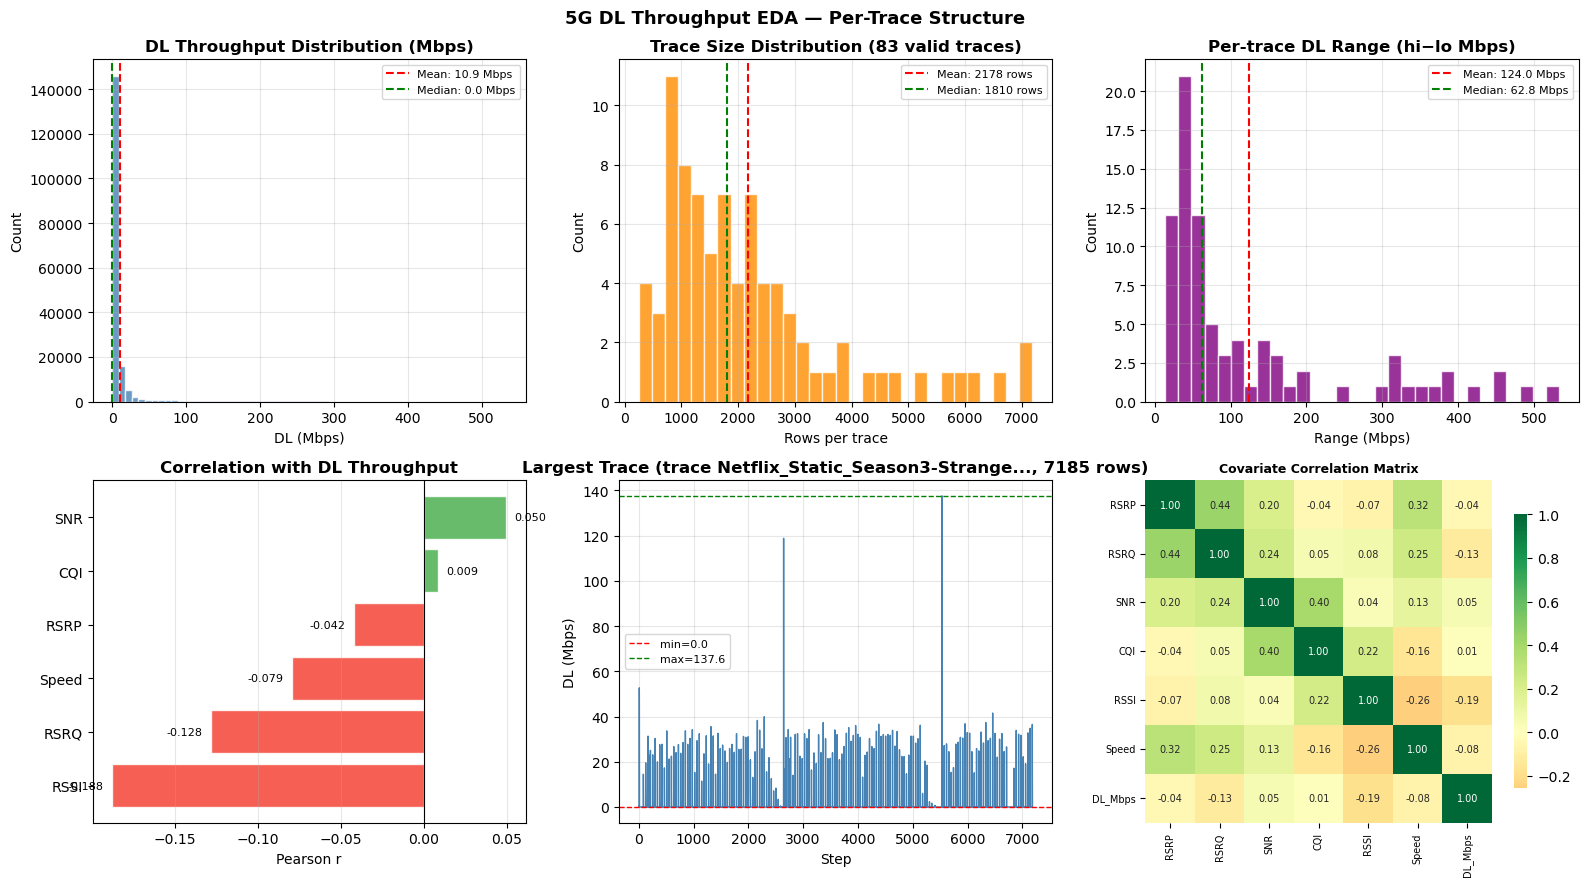


SUMMARY STATISTICS

Trace Statistics:
  • Total traces: 83
  • Total rows: 180,743
  • Min trace size: 249 rows
  • Max trace size: 7,185 rows
  • Mean trace size: 2178 rows
  • Median trace size: 1810 rows

DL Statistics:
  • Mean DL: 10.95 Mbps
  • Median DL: 0.00 Mbps
  • Std DL: 37.15 Mbps
  • Min DL: 0.00 Mbps
  • Max DL: 532.90 Mbps

Feature Correlations with DL:

  •     RSSI:   -0.188
  •     RSRQ:   -0.128
  •    Speed:   -0.079
  •     RSRP:   -0.042
  •      CQI:    0.009
  •      SNR:    0.050

Most predictive covariate: RSSI (-0.188)
Least predictive covariate: CQI (0.009)


In [5]:
print("\n" + "="*70)
print("5G DL THROUGHPUT EDA — Per-Trace Structure")
print("="*70)

# Build a DataFrame with all traces and their metadata
all_data = []
for i, df in enumerate(processed_traces):
    tid = processed_trace_ids[i]
    df_copy = df.copy()
    df_copy['trace_id'] = tid
    df_copy['trace_num'] = i + 1
    all_data.append(df_copy)

df_valid = pd.concat(all_data, ignore_index=True)

print(f"Total rows: {len(df_valid):,}")
print(f"Valid traces: {df_valid['trace_id'].nunique()}")
print(f"DL range: {df_valid['DL_Mbps'].min():.2f} - {df_valid['DL_Mbps'].max():.2f} Mbps")
print(f"DL mean: {df_valid['DL_Mbps'].mean():.2f} Mbps")
print(f"DL median: {df_valid['DL_Mbps'].median():.2f} Mbps")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('5G DL Throughput EDA — Per-Trace Structure',
             fontsize=13, fontweight='bold')

# 1. DL distribution
axes[0,0].hist(df_valid['DL_Mbps'], bins=60, color='steelblue', alpha=0.8, edgecolor='white')
axes[0,0].set_title('DL Throughput Distribution (Mbps)', fontweight='bold')
axes[0,0].set_xlabel('DL (Mbps)'); axes[0,0].set_ylabel('Count')
axes[0,0].axvline(df_valid['DL_Mbps'].mean(), color='red', ls='--', lw=1.5, 
                  label=f'Mean: {df_valid["DL_Mbps"].mean():.1f} Mbps')
axes[0,0].axvline(df_valid['DL_Mbps'].median(), color='green', ls='--', lw=1.5,
                  label=f'Median: {df_valid["DL_Mbps"].median():.1f} Mbps')
axes[0,0].legend(fontsize=8)
axes[0,0].grid(alpha=0.3)

# 2. Trace size distribution
tsizes = df_valid.groupby('trace_id').size()
axes[0,1].hist(tsizes, bins=30, color='darkorange', alpha=0.8, edgecolor='white')
axes[0,1].set_title(f'Trace Size Distribution ({len(tsizes)} valid traces)',
                    fontweight='bold')
axes[0,1].set_xlabel('Rows per trace'); axes[0,1].set_ylabel('Count')
axes[0,1].axvline(tsizes.mean(), color='red', ls='--', lw=1.5,
                  label=f'Mean: {tsizes.mean():.0f} rows')
axes[0,1].axvline(tsizes.median(), color='green', ls='--', lw=1.5,
                  label=f'Median: {tsizes.median():.0f} rows')
axes[0,1].legend(fontsize=8)
axes[0,1].grid(alpha=0.3)

# 3. Per-trace DL range (what gets normalised)
ranges = df_valid.groupby('trace_id')['DL_Mbps'].apply(lambda x: x.max()-x.min())
axes[0,2].hist(ranges, bins=30, color='purple', alpha=0.8, edgecolor='white')
axes[0,2].set_title('Per-trace DL Range (hi−lo Mbps)', fontweight='bold')
axes[0,2].set_xlabel('Range (Mbps)'); axes[0,2].set_ylabel('Count')
axes[0,2].axvline(ranges.mean(), color='red', ls='--', lw=1.5,
                  label=f'Mean: {ranges.mean():.1f} Mbps')
axes[0,2].axvline(ranges.median(), color='green', ls='--', lw=1.5,
                  label=f'Median: {ranges.median():.1f} Mbps')
axes[0,2].legend(fontsize=8)
axes[0,2].grid(alpha=0.3)

# 4. Correlations with DL
corrs = df_valid[COVARIATES + ['DL_Mbps']].corr()['DL_Mbps'].drop('DL_Mbps').sort_values()
bar_col = ['#F44336' if v < 0 else '#4CAF50' for v in corrs.values]
axes[1,0].barh(corrs.index, corrs.values, color=bar_col, alpha=0.85, edgecolor='white')
axes[1,0].axvline(0, color='black', lw=0.8)
axes[1,0].set_title('Correlation with DL Throughput', fontweight='bold')
axes[1,0].set_xlabel('Pearson r')
axes[1,0].grid(alpha=0.3, axis='x')
for i, (v, n) in enumerate(zip(corrs.values, corrs.index)):
    axes[1,0].text(v + (0.005 if v >= 0 else -0.005), i, f'{v:.3f}',
                   va='center', ha='left' if v >= 0 else 'right', fontsize=8)

# 5. Sample trace (largest valid trace)
sample_tid = tsizes.nlargest(1).index[0]
strace = df_valid[df_valid['trace_id'] == sample_tid]
lo, hi = strace['DL_Mbps'].min(), strace['DL_Mbps'].max()
axes[1,1].plot(range(len(strace)), strace['DL_Mbps'].values, color='steelblue', lw=1)
axes[1,1].axhline(lo, color='red', ls='--', lw=1, label=f'min={lo:.1f}')
axes[1,1].axhline(hi, color='green', ls='--', lw=1, label=f'max={hi:.1f}')
axes[1,1].set_title(f'Largest Trace (trace {sample_tid[:30]}..., {len(strace)} rows)',
                    fontweight='bold')
axes[1,1].set_xlabel('Step'); axes[1,1].set_ylabel('DL (Mbps)')
axes[1,1].legend(fontsize=8)
axes[1,1].grid(alpha=0.3)

# 6. Covariate correlation matrix
sns.heatmap(df_valid[COVARIATES + ['DL_Mbps']].corr(), annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, ax=axes[1,2], annot_kws={'size':7},
            cbar_kws={'shrink':0.8})
axes[1,2].set_title('Covariate Correlation Matrix', fontweight='bold', fontsize=9)
axes[1,2].tick_params(labelsize=7)

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)

print(f"""
Trace Statistics:
  • Total traces: {len(tsizes)}
  • Total rows: {len(df_valid):,}
  • Min trace size: {tsizes.min():,} rows
  • Max trace size: {tsizes.max():,} rows
  • Mean trace size: {tsizes.mean():.0f} rows
  • Median trace size: {tsizes.median():.0f} rows

DL Statistics:
  • Mean DL: {df_valid['DL_Mbps'].mean():.2f} Mbps
  • Median DL: {df_valid['DL_Mbps'].median():.2f} Mbps
  • Std DL: {df_valid['DL_Mbps'].std():.2f} Mbps
  • Min DL: {df_valid['DL_Mbps'].min():.2f} Mbps
  • Max DL: {df_valid['DL_Mbps'].max():.2f} Mbps

Feature Correlations with DL:
""")
for k, v in corrs.items():
    print(f"  • {k:>8s}: {v:>8.3f}")

print("\nMost predictive covariate:", corrs.abs().idxmax(), 
      f"({corrs[corrs.abs().idxmax()]:.3f})")
print("Least predictive covariate:", corrs.abs().idxmin(),
      f"({corrs[corrs.abs().idxmin()]:.3f})")
print("="*70)


5G DL THROUGHPUT EDA — Per-Trace Structure
Total rows: 180,743
Valid traces: 83
DL range: 0.00 - 532.90 Mbps
DL mean: 10.95 Mbps
DL median: 0.00 Mbps

Generating lag features for correlation analysis...
Rows after lag feature generation: 180,660
trace_id column present: True


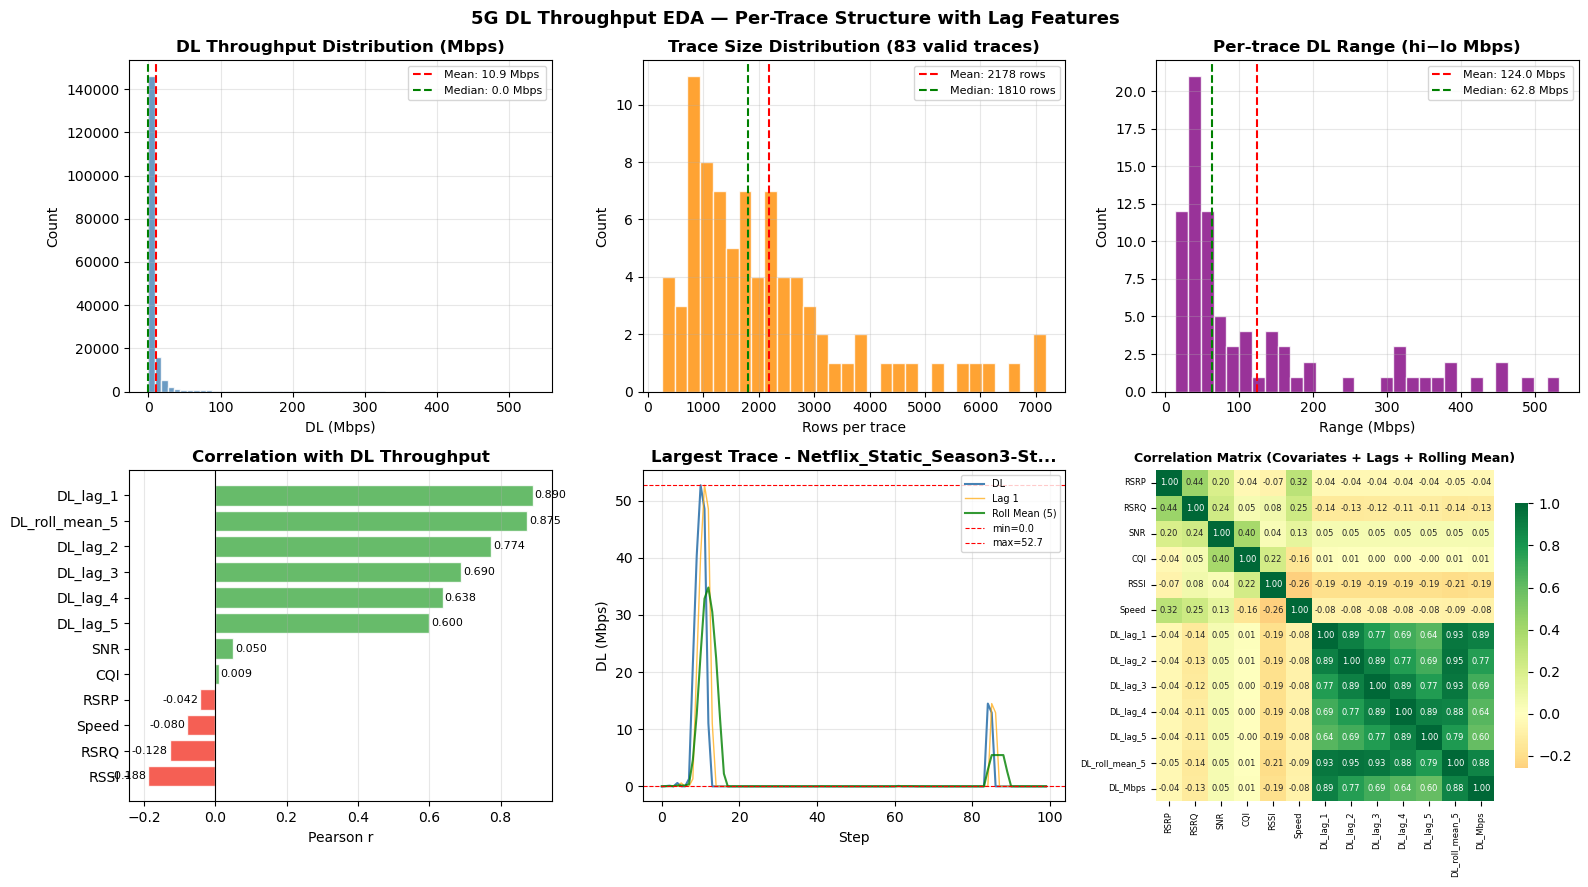


SUMMARY STATISTICS

Trace Statistics:
  • Total traces: 83
  • Total rows: 180,743
  • Min trace size: 249 rows
  • Max trace size: 7,185 rows
  • Mean trace size: 2178 rows
  • Median trace size: 1810 rows

DL Statistics:
  • Mean DL: 10.95 Mbps
  • Median DL: 0.00 Mbps
  • Std DL: 37.15 Mbps
  • Min DL: 0.00 Mbps
  • Max DL: 532.90 Mbps

Feature Correlations with DL (sorted by absolute value):

  •        DL_lag_1:    0.890
  •  DL_roll_mean_5:    0.875
  •        DL_lag_2:    0.774
  •        DL_lag_3:    0.690
  •        DL_lag_4:    0.638
  •        DL_lag_5:    0.600
  •            RSSI:   -0.188
  •            RSRQ:   -0.128
  •           Speed:   -0.080
  •             SNR:    0.050
  •            RSRP:   -0.042
  •             CQI:    0.009

Most predictive features:
  1. DL_lag_1 (0.890)
  2. DL_roll_mean_5 (0.875)
  3. DL_lag_2 (0.774)

Best lag feature: DL_lag_1 (0.890)
Rolling mean correlation: 0.875


In [6]:
print("\n" + "="*70)
print("5G DL THROUGHPUT EDA — Per-Trace Structure")
print("="*70)

# build a DataFrame with all traces and their metadata
all_data = []
for i, df in enumerate(processed_traces):
    tid = processed_trace_ids[i]
    df_copy = df.copy()
    df_copy['trace_id'] = tid
    df_copy['trace_num'] = i + 1
    all_data.append(df_copy)

df_valid = pd.concat(all_data, ignore_index=True)

print(f"Total rows: {len(df_valid):,}")
print(f"Valid traces: {df_valid['trace_id'].nunique()}")
print(f"DL range: {df_valid['DL_Mbps'].min():.2f} - {df_valid['DL_Mbps'].max():.2f} Mbps")
print(f"DL mean: {df_valid['DL_Mbps'].mean():.2f} Mbps")
print(f"DL median: {df_valid['DL_Mbps'].median():.2f} Mbps")

print("\nGenerating lag features for correlation analysis...")

df_lagged = df_valid.copy()

# group by trace_id and compute lags + rolling mean
for g in df_lagged.groupby('trace_id'):
    idx = g[1].index
    df_lagged.loc[idx, 'DL_lag_1'] = g[1]['DL_Mbps'].shift(1).values
    df_lagged.loc[idx, 'DL_lag_2'] = g[1]['DL_Mbps'].shift(2).values
    df_lagged.loc[idx, 'DL_lag_3'] = g[1]['DL_Mbps'].shift(3).values
    df_lagged.loc[idx, 'DL_lag_4'] = g[1]['DL_Mbps'].shift(4).values
    df_lagged.loc[idx, 'DL_lag_5'] = g[1]['DL_Mbps'].shift(5).values
    df_lagged.loc[idx, 'DL_roll_mean_5'] = g[1]['DL_Mbps'].rolling(5, min_periods=1).mean().values

# drop rows with NaN lags (first few rows of each trace)
df_lagged = df_lagged.dropna(subset=['DL_lag_1'])

print(f"Rows after lag feature generation: {len(df_lagged):,}")
print(f"trace_id column present: {'trace_id' in df_lagged.columns}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('5G DL Throughput EDA — Per-Trace Structure with Lag Features',
             fontsize=13, fontweight='bold')

# 1. DL distribution
axes[0,0].hist(df_valid['DL_Mbps'], bins=60, color='steelblue', alpha=0.8, edgecolor='white')
axes[0,0].set_title('DL Throughput Distribution (Mbps)', fontweight='bold')
axes[0,0].set_xlabel('DL (Mbps)'); axes[0,0].set_ylabel('Count')
axes[0,0].axvline(df_valid['DL_Mbps'].mean(), color='red', ls='--', lw=1.5, 
                  label=f'Mean: {df_valid["DL_Mbps"].mean():.1f} Mbps')
axes[0,0].axvline(df_valid['DL_Mbps'].median(), color='green', ls='--', lw=1.5,
                  label=f'Median: {df_valid["DL_Mbps"].median():.1f} Mbps')
axes[0,0].legend(fontsize=8)
axes[0,0].grid(alpha=0.3)

# 2. Trace size distribution
tsizes = df_valid.groupby('trace_id').size()
axes[0,1].hist(tsizes, bins=30, color='darkorange', alpha=0.8, edgecolor='white')
axes[0,1].set_title(f'Trace Size Distribution ({len(tsizes)} valid traces)',
                    fontweight='bold')
axes[0,1].set_xlabel('Rows per trace'); axes[0,1].set_ylabel('Count')
axes[0,1].axvline(tsizes.mean(), color='red', ls='--', lw=1.5,
                  label=f'Mean: {tsizes.mean():.0f} rows')
axes[0,1].axvline(tsizes.median(), color='green', ls='--', lw=1.5,
                  label=f'Median: {tsizes.median():.0f} rows')
axes[0,1].legend(fontsize=8)
axes[0,1].grid(alpha=0.3)

# 3. Per-trace DL range (what gets normalised)
ranges = df_valid.groupby('trace_id')['DL_Mbps'].apply(lambda x: x.max()-x.min())
axes[0,2].hist(ranges, bins=30, color='purple', alpha=0.8, edgecolor='white')
axes[0,2].set_title('Per-trace DL Range (hi−lo Mbps)', fontweight='bold')
axes[0,2].set_xlabel('Range (Mbps)'); axes[0,2].set_ylabel('Count')
axes[0,2].axvline(ranges.mean(), color='red', ls='--', lw=1.5,
                  label=f'Mean: {ranges.mean():.1f} Mbps')
axes[0,2].axvline(ranges.median(), color='green', ls='--', lw=1.5,
                  label=f'Median: {ranges.median():.1f} Mbps')
axes[0,2].legend(fontsize=8)
axes[0,2].grid(alpha=0.3)

# 4. Correlations with DL (INCLUDING LAGS AND ROLLING MEAN)
# define all features for correlation
all_features = COVARIATES + ['DL_lag_1', 'DL_lag_2', 'DL_lag_3', 'DL_lag_4', 'DL_lag_5', 'DL_roll_mean_5']
corrs = df_lagged[all_features + ['DL_Mbps']].corr()['DL_Mbps'].drop('DL_Mbps').sort_values()

bar_col = ['#F44336' if v < 0 else '#4CAF50' for v in corrs.values]
axes[1,0].barh(corrs.index, corrs.values, color=bar_col, alpha=0.85, edgecolor='white')
axes[1,0].axvline(0, color='black', lw=0.8)
axes[1,0].set_title('Correlation with DL Throughput', fontweight='bold')
axes[1,0].set_xlabel('Pearson r')
axes[1,0].grid(alpha=0.3, axis='x')
for i, (v, n) in enumerate(zip(corrs.values, corrs.index)):
    axes[1,0].text(v + (0.005 if v >= 0 else -0.005), i, f'{v:.3f}',
                   va='center', ha='left' if v >= 0 else 'right', fontsize=8)

# 5. Sample trace-largest valid trace with lags
sample_tid = tsizes.nlargest(1).index[0]
strace = df_lagged[df_lagged['trace_id'] == sample_tid].head(100)  # First 100 points for clarity
axes[1,1].plot(range(len(strace)), strace['DL_Mbps'].values, color='steelblue', lw=1.5, label='DL')
axes[1,1].plot(range(len(strace)), strace['DL_lag_1'].values, color='orange', lw=1, alpha=0.7, label='Lag 1')
axes[1,1].plot(range(len(strace)), strace['DL_roll_mean_5'].values, color='green', lw=1.5, alpha=0.8, label='Roll Mean (5)')
lo, hi = strace['DL_Mbps'].min(), strace['DL_Mbps'].max()
axes[1,1].axhline(lo, color='red', ls='--', lw=0.8, label=f'min={lo:.1f}')
axes[1,1].axhline(hi, color='red', ls='--', lw=0.8, label=f'max={hi:.1f}')
axes[1,1].set_title(f'Largest Trace - {sample_tid[:25]}...',
                    fontweight='bold')
axes[1,1].set_xlabel('Step'); axes[1,1].set_ylabel('DL (Mbps)')
axes[1,1].legend(fontsize=7, loc='upper right')
axes[1,1].grid(alpha=0.3)

# 6. Covariate + Lag correlation matrix
corr_matrix = df_lagged[all_features + ['DL_Mbps']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, ax=axes[1,2], annot_kws={'size':6},
            cbar_kws={'shrink':0.8})
axes[1,2].set_title('Correlation Matrix (Covariates + Lags + Rolling Mean)', 
                    fontweight='bold', fontsize=9)
axes[1,2].tick_params(labelsize=6)

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)

print(f"""
Trace Statistics:
  • Total traces: {len(tsizes)}
  • Total rows: {len(df_valid):,}
  • Min trace size: {tsizes.min():,} rows
  • Max trace size: {tsizes.max():,} rows
  • Mean trace size: {tsizes.mean():.0f} rows
  • Median trace size: {tsizes.median():.0f} rows

DL Statistics:
  • Mean DL: {df_valid['DL_Mbps'].mean():.2f} Mbps
  • Median DL: {df_valid['DL_Mbps'].median():.2f} Mbps
  • Std DL: {df_valid['DL_Mbps'].std():.2f} Mbps
  • Min DL: {df_valid['DL_Mbps'].min():.2f} Mbps
  • Max DL: {df_valid['DL_Mbps'].max():.2f} Mbps

Feature Correlations with DL (sorted by absolute value):
""")

# sort by absolute correlation
corrs_sorted = corrs.abs().sort_values(ascending=False)
for feat in corrs_sorted.index:
    val = corrs[feat]
    print(f"  • {feat:>15s}: {val:>8.3f}")

print("\nMost predictive features:")
print(f"  1. {corrs_sorted.index[0]} ({corrs[corrs_sorted.index[0]]:.3f})")
if len(corrs_sorted) > 1:
    print(f"  2. {corrs_sorted.index[1]} ({corrs[corrs_sorted.index[1]]:.3f})")
if len(corrs_sorted) > 2:
    print(f"  3. {corrs_sorted.index[2]} ({corrs[corrs_sorted.index[2]]:.3f})")

# Lag analysis
lag_corrs = {k: v for k, v in corrs.items() if k.startswith('DL_lag_')}
if lag_corrs:
    best_lag = max(lag_corrs, key=lambda x: abs(lag_corrs[x]))
    print(f"\nBest lag feature: {best_lag} ({lag_corrs[best_lag]:.3f})")
    print(f"Rolling mean correlation: {corrs.get('DL_roll_mean_5', 0):.3f}")

print("="*70)

## Measurement Sites (CellID) Coverage

Counts distinct `CellID` values across all processed traces, using the dataset itself (not an external reference), since `CellID` passes through preprocessing untouched.


Distinct CellIDs across all 83 traces: 187
Total rows: 180,743
Top 10 CellIDs by measurement volume:
  CellID       11:  84,188 rows (46.6%)
  CellID       13:  31,168 rows (17.2%)
  CellID       12:  16,410 rows (9.1%)
  CellID        2:  15,307 rows (8.5%)
  CellID        3:   7,886 rows (4.4%)
  CellID        1:   5,835 rows (3.2%)
  CellID    21001:   4,014 rows (2.2%)
  CellID    41001:   2,293 rows (1.3%)
  CellID    51923:     846 rows (0.5%)
  CellID    10505:     816 rows (0.5%)

Top 10 CellIDs account for 93.4% of all measurements;
the remaining 177 CellIDs cover the rest (brief handovers / edge-of-coverage transitions).


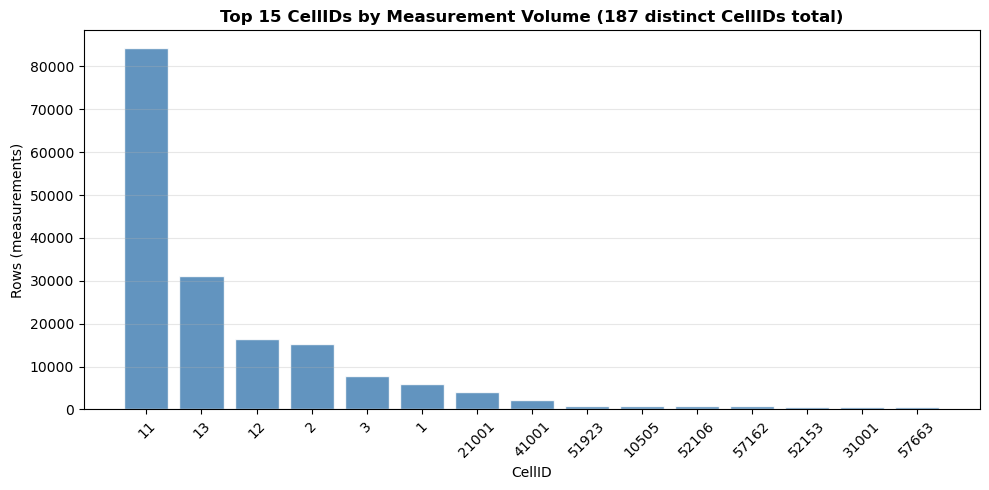

In [7]:
# Check CellID survived preprocessing, then count distinct cells across df_valid
assert 'CellID' in df_valid.columns, "CellID missing -- check preprocess_trace_with_reporting"

cell_counts = df_valid['CellID'].value_counts()
n_distinct_cells = df_valid['CellID'].nunique()

print(f"Distinct CellIDs across all {df_valid['trace_id'].nunique()} traces: {n_distinct_cells}")
print(f"Total rows: {len(df_valid):,}")
print(f"Top 10 CellIDs by measurement volume:")
for cid, cnt in cell_counts.head(10).items():
    print(f"  CellID {cid:>8}: {cnt:>7,} rows ({cnt/len(df_valid)*100:.1f}%)")

top10_share = cell_counts.head(10).sum() / len(df_valid) * 100
print(f"\nTop 10 CellIDs account for {top10_share:.1f}% of all measurements;")
print(f"the remaining {n_distinct_cells - 10} CellIDs cover the rest "
      f"(brief handovers / edge-of-coverage transitions).")

fig, ax = plt.subplots(figsize=(10, 5))
top15 = cell_counts.head(15)
ax.bar(top15.index.astype(str), top15.values, color='steelblue', alpha=0.85, edgecolor='white')
ax.set_title(f'Top 15 CellIDs by Measurement Volume ({n_distinct_cells} distinct CellIDs total)',
             fontweight='bold')
ax.set_xlabel('CellID')
ax.set_ylabel('Rows (measurements)')
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


In [8]:
# y has shape (n_samples, HORIZON): one row per prediction origin, one
# column per future step (genuine multi-step-ahead forecasting).

def make_features(yn, cov_mat=None, n_lags=5):
    """
    Build supervised features for genuine multi-step-ahead forecasting.

    Track A: yn + covariates
    Track B: yn only
    Track C: yn only (per trace)

    Returns X of shape (n_samples, n_features) and Y of shape
    (n_samples, HORIZON) -- Y[i] = [yn[i], yn[i+1], ..., yn[i+HORIZON-1]],
    the actual future trajectory, not its average.
    """
    n = len(yn)
    Xs, Ys = [], []
    for i in range(n_lags, n - HORIZON):
        # Lag features
        lags = [yn[i-k] for k in range(1, n_lags+1)]
        # Rolling mean of last 5
        roll5 = np.mean(yn[max(0, i-5):i])
        row = lags + [roll5]
        # add covariates if provided (Track A)
        if cov_mat is not None:
            row += list(cov_mat[i])
        Xs.append(row)
        # Target: the actual next HORIZON steps, not their average
        Ys.append(yn[i:i+HORIZON])
    return np.array(Xs), np.array(Ys)

def eval_horizon(y_true, y_pred):
    """
    Score a multi-step forecast the way the paper's walk-forward protocol
    does: flatten across all prediction origins AND all horizon steps, then
    compute RMSE/MAE on the pooled values. This is what "iteratively over a
    fixed 10-step horizon, validation window advancing sequentially" means
    in practice once you flatten it into one big error sample.

    y_true, y_pred: shape (n_samples, HORIZON)
    Returns: rmse, mae (scalars, on the same [0,1] normalised scale as yn --
    convert to Mbps at the point of use, same as before).
    """
    diff = y_true.ravel() - y_pred.ravel()
    rmse = float(np.sqrt(np.mean(diff ** 2)))
    mae = float(np.mean(np.abs(diff)))
    return rmse, mae

def prepare_trace_data(trace_df, trace_id):
    """
    Prepare data for all three tracks.

    Returns:
        track_A: (X_train, Y_train, X_test, Y_test) -- with covariates, Y is (n, HORIZON)
        track_B: (X_train, Y_train, X_test, Y_test) -- without covariates, Y is (n, HORIZON)
        track_C: (Y_train, Y_test) -- univariate, per trace, Y is (n, HORIZON)
    """

    y = trace_df['DL_Mbps'].values
    n_all = len(y)

    # ---- split FIRST, then fit the normalisation on the development portion only ----
    # Windows are origins i = N_LAGS .. n_all-HORIZON-1. The first holdout origin is
    # N_LAGS + n_tr, so every value strictly before it is development data.
    n_windows = n_all - N_LAGS - HORIZON
    if n_windows < 10:
        return None
    n_tr = int(n_windows * TRAIN_FRAC)
    dev_end = N_LAGS + n_tr                 # first holdout origin; y[:dev_end] is development data

    lo, hi = y[:dev_end].min(), y[:dev_end].max()
    if hi - lo < 0.01:
        return None

    # Normalise per trace with the DEV min/max (no clipping: holdout values may fall outside [0,1])
    yn = (y - lo) / (hi - lo)

    # Covariates (normalised with development-portion min/max)
    cov = trace_df[COVARIATES].values.astype(float)
    cov_norm = np.zeros_like(cov)
    for j, col in enumerate(COVARIATES):
        min_val = cov[:dev_end, j].min()
        max_val = cov[:dev_end, j].max()
        if max_val > min_val:
            cov_norm[:, j] = (cov[:, j] - min_val) / (max_val - min_val)
        else:
            cov_norm[:, j] = 0

    # track A: with covariates
    XA, YA = make_features(yn, cov_norm, N_LAGS)

    # track B: without covariates
    XB, YB = make_features(yn, None, N_LAGS)

    if len(YA) < 10:
        return None

    # split (80/20 walk-forward); n_tr is the same value computed above
    assert n_tr == int(len(YA) * TRAIN_FRAC)

    # track A
    XA_train, XA_test = XA[:n_tr], XA[n_tr:]
    YA_train, YA_test = YA[:n_tr], YA[n_tr:]

    # track B
    XB_train, XB_test = XB[:n_tr], XB[n_tr:]
    YB_train, YB_test = YB[:n_tr], YB[n_tr:]

    # track C (univariate) -- same targets as Track A/B, no covariates used downstream
    YC_train, YC_test = YA[:n_tr], YA[n_tr:]

    return {
        'trace_id': trace_id,
        'track_A': (XA_train, YA_train, XA_test, YA_test),
        'track_B': (XB_train, YB_train, XB_test, YB_test),
        'track_C': (YC_train, YC_test),
        'min_val': lo,          # development-portion min (Mbps)
        'max_val': hi,          # development-portion max (Mbps)
        'dev_end': dev_end,
        'holdout_min_norm': float(yn[dev_end:].min()),
        'holdout_max_norm': float(yn[dev_end:].max()),
    }

# prepare data for all traces
trace_data_list = []

print("\n" + "="*70)
print("PREPARING DATA FOR ALL TRACKS (genuine multi-step-ahead targets)")
print("="*70)

for trace in numbered_traces:
    data = prepare_trace_data(trace['dataframe'], trace['id'])
    if data is not None:
        trace_data_list.append(data)

print(f"Prepared {len(trace_data_list)} traces for modeling")
if trace_data_list:
    _, YA_check, _, _ = trace_data_list[0]['track_A']
    print(f"Target shape per trace, e.g. trace 0: {YA_check.shape}  (n_samples, HORIZON={HORIZON})")

_out_hi = sum(d['holdout_max_norm'] > 1 for d in trace_data_list)
_out_lo = sum(d['holdout_min_norm'] < 0 for d in trace_data_list)
print(f"Normalisation fitted on the development portion only. Holdout exceeds the dev maximum in {_out_hi}/{len(trace_data_list)} traces and falls below the dev minimum in {_out_lo}/{len(trace_data_list)}.")



PREPARING DATA FOR ALL TRACKS (genuine multi-step-ahead targets)
Prepared 83 traces for modeling
Target shape per trace, e.g. trace 0: (2979, 10)  (n_samples, HORIZON=10)
Normalisation fitted on the development portion only. Holdout exceeds the dev maximum in 14/83 traces and falls below the dev minimum in 0/83.


## Model Configuration and Reproducibility Reference (Section 3.1.4)

Full hyperparameter, architecture, and training-procedure details for every model trained in Part 1, compiled here as a single reference table. Values below are transcribed directly from the actual training code in this notebook, not estimated or reconstructed.

### Tree-based and linear models (Track A & B)

| Model | Key hyperparameters | Random seed |
|---|---|---|
| LightGBM | `n_estimators=1000`, `learning_rate=0.02`, `max_depth=15`, `num_leaves=31`, `subsample=0.8`, `colsample_bytree=0.8`, `min_child_samples=10` | `random_state=42` |
| Random Forest | `n_estimators=300`, `max_depth=15`, `min_samples_leaf=3` | `random_state=42` |
| Linear Regression | scikit-learn defaults (no explicit regularization) | n/a (deterministic) |

### Deep learning models (Block RNN, Transformer -- Track A & B; N-BEATS -- Track B)

| Model | Architecture | Optimizer / LR / Schedule | Epochs / Batch | Early stopping |
|---|---|---|---|---|
| Block RNN | 1-layer LSTM, 32 hidden units, dropout=0.3; FC head 32→16→10 (ReLU, Dropout, Sigmoid) | Adam, lr=5e-4, weight_decay=1e-4; StepLR(step_size=5, gamma=0.7) | 20 epochs (fixed), batch_size=256, seq_len=10 | **No** -- best-training-loss checkpoint only (not validation-based) |
| Transformer | d_model=32, 2 attention heads, 1 encoder layer, dim_feedforward=64, dropout=0.3; same FC head as Block RNN; **input is projected directly into the encoder, with no explicit positional encoding (sinusoidal or learned) added** | Same as Block RNN (shared `train_nn()` routine) | Same as Block RNN | **No** -- same as Block RNN |
| N-BEATS | hidden_dim=128, n_layers=2, dropout=0.2, ReLU; shared MLP + forecast_linear head, Sigmoid output | Adam, lr=1e-3; ReduceLROnPlateau(patience=5, factor=0.5) | Up to 30 epochs, batch_size=256 | **Yes** -- genuine validation-based early stopping: internal 80/20 split of the *training* data (`sklearn.train_test_split`, random shuffle, `random_state=42`), patience=10 epochs on validation loss |

Loss function for all three: MSE, computed on the normalized [0,1] target.

**Note on early-stopping asymmetry:** only N-BEATS uses a genuine held-out validation set for early stopping during training. Block RNN and Transformer train for a fixed 20 epochs and checkpoint the best *training*-loss epoch, which is not equivalent to validation-based stopping. This is an accurate description of current practice, not a claim that all three models were regularized identically.

### Track C (local, per-trace models)

| Model | Configuration |
|---|---|
| AutoARIMA (`pmdarima.auto_arima`) | `seasonal=False`, `start_p=0`, `start_q=0`, `max_p=2`, `max_q=2`, `max_d=1`, `stepwise=True`, `information_criterion='aic'`, `n_fits=10`, `error_action='ignore'` |
| Exponential Smoothing (`statsmodels.ExponentialSmoothing`) | `trend=None`, `seasonal=None`, `initialization_method='estimated'` (simple exponential smoothing; no trend or seasonal component) |

Both are refit at every walk-forward test origin (genuine walk-forward retraining, not fit-once), matching the paper's protocol. Naive Mean (Track C) and the Track B naive baselines (Aggregate, Seasonal, Drift) use no learned parameters.

### Random seed summary

- Global seeds set once at notebook start: `np.random.seed(42)`, `torch.manual_seed(42)`.
- Explicit `random_state=42` on every scikit-learn/LightGBM model instantiation.
- N-BEATS's internal validation split also uses `random_state=42`.
- **Caveat:** `torch.manual_seed(42)` alone does not guarantee bit-exact reproducibility on GPU (cuDNN non-determinism is not additionally disabled here via `torch.backends.cudnn.deterministic`), so exact loss values may vary slightly run-to-run on GPU hardware even with the seed fixed; CPU execution should be exactly reproducible.

### Software versions

Library versions are not hardcoded here to avoid stating numbers that may not match your actual runtime environment. Running the cell immediately below captures the exact versions used in this environment.


In [9]:
# Software versions 

import pandas, numpy, sklearn, lightgbm, torch, statsmodels, pmdarima
import sys

print(f"Python:       {sys.version.split()[0]}")
print(f"pandas:       {pandas.__version__}")
print(f"numpy:        {numpy.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"lightgbm:     {lightgbm.__version__}")
print(f"torch:        {torch.__version__}")
print(f"statsmodels:  {statsmodels.__version__}")
print(f"pmdarima:     {pmdarima.__version__}")


Python:       3.13.9
pandas:       2.3.3
numpy:        2.3.5
scikit-learn: 1.7.2
lightgbm:     4.6.0
torch:        2.13.0
statsmodels:  0.14.5
pmdarima:     2.1.1


# Build Global Training Data (Track A & B)

Concatenates the training folds from every trace into one global dataset for Track A and Track B.


In [10]:

def build_global_data(trace_data_list, track='A'):
    """
    Build global training data for Track A or Track B.
    Concatenates all trace training folds.
    """
    
    X_all = []
    y_all = []
    
    for data in trace_data_list:
        if track == 'A':
            X_train, y_train, _, _ = data['track_A']
        elif track == 'B':
            X_train, y_train, _, _ = data['track_B']
        else:
            continue
        
        if len(X_train) > 0:
            X_all.append(X_train)
            y_all.append(y_train)
    
    if X_all:
        X_global = np.vstack(X_all)
        y_global = np.concatenate(y_all)
        return X_global, y_global
    return None, None

# build global data
X_global_A, y_global_A = build_global_data(trace_data_list, 'A')
X_global_B, y_global_B = build_global_data(trace_data_list, 'B')

print("\n" + "="*70)
print("GLOBAL TRAINING DATA")
print("="*70)
print(f"Track A (with covariates): {X_global_A.shape if X_global_A is not None else 'None'}")
print(f"Track B (without covariates): {X_global_B.shape if X_global_B is not None else 'None'}")

# scale features
scaler_A = StandardScaler()
scaler_B = StandardScaler()

X_global_A_scaled = scaler_A.fit_transform(X_global_A) if X_global_A is not None else None
X_global_B_scaled = scaler_B.fit_transform(X_global_B) if X_global_B is not None else None

print(f"\nFeature dimensions:")
print(f"  Track A: {X_global_A.shape[1] if X_global_A is not None else 'N/A'} features")
print(f"  Track B: {X_global_B.shape[1] if X_global_B is not None else 'N/A'} features")


GLOBAL TRAINING DATA
Track A (with covariates): (143565, 12)
Track B (without covariates): (143565, 6)

Feature dimensions:
  Track A: 12 features
  Track B: 6 features


# Track A & B - Tree and Linear Models

Trains LightGBM, Random Forest, and Linear Regression on Track A and B. LightGBM is wrapped in `MultiOutputRegressor` to handle the 10-step target.


In [11]:
# y_global_A/B has shape (n, HORIZON). RandomForest/LinearRegression accept
# this natively; LightGBM needs MultiOutputRegressor (one model per horizon
# step, so ~10x LightGBM's usual training time).

from sklearn.multioutput import MultiOutputRegressor

def evaluate_global_model_full_distribution(model, X_test_list, y_test_list, trace_data_list, scaler, model_name, track='A'):
    """Evaluate a global model across all traces with full distribution.
    y_test is now (n_test, HORIZON); pred is scored with eval_horizon(),
    which pools every prediction origin and every horizon step together --
    same pooling the paper's walk-forward protocol implies."""

    results = {'rmse': [], 'mae': []}

    for i, data in enumerate(trace_data_list):
        if track == 'A':
            _, _, X_test, y_test = data['track_A']
        else:
            _, _, X_test, y_test = data['track_B']

        if len(y_test) < 3:
            continue

        try:
            X_test_scaled = scaler.transform(X_test)
            pred = model.predict(X_test_scaled)
            pred = np.clip(pred, 0, None)

            # convert to Mbps (broadcasts fine over the (n, HORIZON) shape)
            lo, hi = data['min_val'], data['max_val']
            y_true_mbps = y_test * (hi - lo) + lo
            y_pred_mbps = pred * (hi - lo) + lo

            rmse, mae = eval_horizon(y_true_mbps, y_pred_mbps)

            results['rmse'].append(rmse)
            results['mae'].append(mae)
        except Exception as e:
            continue

    rmse_arr = np.array(results['rmse'])
    mae_arr = np.array(results['mae'])

    return {
        'model': model_name,
        'track': track,
        'rmse_min': np.min(rmse_arr),
        'rmse_q1': np.percentile(rmse_arr, 25),
        'rmse_median': np.median(rmse_arr),
        'rmse_mean': np.mean(rmse_arr),
        'rmse_q3': np.percentile(rmse_arr, 75),
        'rmse_max': np.max(rmse_arr),
        'rmse_iqr': np.percentile(rmse_arr, 75) - np.percentile(rmse_arr, 25),
        'rmse_std': np.std(rmse_arr),
        'mae_min': np.min(mae_arr),
        'mae_q1': np.percentile(mae_arr, 25),
        'mae_median': np.median(mae_arr),
        'mae_mean': np.mean(mae_arr),
        'mae_q3': np.percentile(mae_arr, 75),
        'mae_max': np.max(mae_arr),
        'mae_iqr': np.percentile(mae_arr, 75) - np.percentile(mae_arr, 25),
        'mae_std': np.std(mae_arr),
        'n_traces': len(rmse_arr),
    }

print("\n" + "="*70)
print("TRAINING TRACK A & B MODELS WITH TIME TRACKING")
print("="*70)

# Dictionary to store training times
training_times = {}

# LightGBM (wrapped for multi-step output)
print("\nTraining LightGBM (MultiOutputRegressor -- 10 models per track, one per horizon step)...")
start_time = time.time()
lgb_A = MultiOutputRegressor(
    lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.02, max_depth=15,
                       num_leaves=31, subsample=0.8, colsample_bytree=0.8,
                       min_child_samples=10, random_state=42, verbose=-1),
    n_jobs=-1)
lgb_A.fit(X_global_A_scaled, y_global_A)
training_times['LightGBM_A'] = time.time() - start_time
print(f"  LightGBM A training time: {training_times['LightGBM_A']:.2f}s")

start_time = time.time()
lgb_B = MultiOutputRegressor(
    lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.02, max_depth=15,
                       num_leaves=31, subsample=0.8, colsample_bytree=0.8,
                       min_child_samples=10, random_state=42, verbose=-1),
    n_jobs=-1)
lgb_B.fit(X_global_B_scaled, y_global_B)
training_times['LightGBM_B'] = time.time() - start_time
print(f"  LightGBM B training time: {training_times['LightGBM_B']:.2f}s")

# Random Forest (native multi-output support, no wrapper needed)
print("\nTraining Random Forest...")
start_time = time.time()
rf_A = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=3,
                             n_jobs=-1, random_state=42)
rf_A.fit(X_global_A_scaled, y_global_A)
training_times['Random Forest_A'] = time.time() - start_time
print(f"  Random Forest A training time: {training_times['Random Forest_A']:.2f}s")

start_time = time.time()
rf_B = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=3,
                             n_jobs=-1, random_state=42)
rf_B.fit(X_global_B_scaled, y_global_B)
training_times['Random Forest_B'] = time.time() - start_time
print(f"  Random Forest B training time: {training_times['Random Forest_B']:.2f}s")

# Linear Regression (native multi-output support, no wrapper needed)
print("\nTraining Linear Regression...")
start_time = time.time()
lr_A = LinearRegression().fit(X_global_A_scaled, y_global_A)
training_times['Linear Regression_A'] = time.time() - start_time
print(f"  Linear Regression A training time: {training_times['Linear Regression_A']:.2f}s")

start_time = time.time()
lr_B = LinearRegression().fit(X_global_B_scaled, y_global_B)
training_times['Linear Regression_B'] = time.time() - start_time
print(f"  Linear Regression B training time: {training_times['Linear Regression_B']:.2f}s")

# evaluate all models with full distribution
results_track_A = []
results_track_B = []

print("\nEvaluating models...")

for model, name, track in [
    (lgb_A, 'LightGBM', 'A'),
    (rf_A, 'Random Forest', 'A'),
    (lr_A, 'Linear Regression', 'A'),
    (lgb_B, 'LightGBM', 'B'),
    (rf_B, 'Random Forest', 'B'),
    (lr_B, 'Linear Regression', 'B'),
]:
    scaler = scaler_A if track == 'A' else scaler_B
    result = evaluate_global_model_full_distribution(model, None, None, trace_data_list, scaler, name, track)
    result['train_time'] = training_times[f'{name}_{track}']
    if track == 'A':
        results_track_A.append(result)
    else:
        results_track_B.append(result)

print("\n" + "="*100)
print("TRACK A RESULTS (with covariates) - FULL ERROR DISTRIBUTION")
print("="*100)
print(f"{'Model':<20s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>8s} {'N':>5s}")
print("-"*100)
for r in sorted(results_track_A, key=lambda x: x['rmse_median']):
    print(f"{r['model']:<20s} {r['rmse_min']:>8.3f} {r['rmse_q1']:>8.3f} {r['rmse_median']:>8.3f} {r['rmse_mean']:>8.3f} {r['rmse_q3']:>8.3f} {r['rmse_max']:>8.3f} {r['rmse_iqr']:>8.3f} {r['rmse_std']:>8.3f} {r['train_time']:>8.2f} {r['n_traces']:>5d}")

print("\n" + "="*100)
print("TRACK B RESULTS (without covariates) - FULL ERROR DISTRIBUTION")
print("="*100)
print(f"{'Model':<20s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>8s} {'N':>5s}")
print("-"*100)
for r in sorted(results_track_B, key=lambda x: x['rmse_median']):
    print(f"{r['model']:<20s} {r['rmse_min']:>8.3f} {r['rmse_q1']:>8.3f} {r['rmse_median']:>8.3f} {r['rmse_mean']:>8.3f} {r['rmse_q3']:>8.3f} {r['rmse_max']:>8.3f} {r['rmse_iqr']:>8.3f} {r['rmse_std']:>8.3f} {r['train_time']:>8.2f} {r['n_traces']:>5d}")



TRAINING TRACK A & B MODELS WITH TIME TRACKING

Training LightGBM (MultiOutputRegressor -- 10 models per track, one per horizon step)...
  LightGBM A training time: 29.55s
  LightGBM B training time: 25.07s

Training Random Forest...
  Random Forest A training time: 36.92s
  Random Forest B training time: 24.09s

Training Linear Regression...
  Linear Regression A training time: 0.05s
  Linear Regression B training time: 0.02s

Evaluating models...

TRACK A RESULTS (with covariates) - FULL ERROR DISTRIBUTION
Model                     Min       Q1   Median     Mean       Q3      Max      IQR      Std  Time(s)     N
----------------------------------------------------------------------------------------------------
LightGBM                0.549    1.723    3.443   11.676    5.075   85.194    3.351   21.779    29.55    83
Random Forest           0.559    1.703    3.553   11.751    4.992   84.872    3.289   21.731    36.92    83
Linear Regression       0.392    1.672    3.684   12.675    

# Deep Learning Models (Track A & B)

Trains the sequence models (RNN, Transformer) on Track A and Track B using PyTorch.


In [12]:
# Reduced complexity to prevent overfitting

import copy

# Sequence dataset for RNN/Transformer
class SeqDS(Dataset):
    def __init__(self, X, y, seq_len=10):
        self.X, self.y, self.seq = X, y, seq_len
        # y is (n_samples, HORIZON)
    
    def __len__(self):
        return max(0, len(self.X) - self.seq)
    
    def __getitem__(self, i):
        return (torch.tensor(self.X[i:i+self.seq], dtype=torch.float32),
                torch.tensor(self.y[i+self.seq-1], dtype=torch.float32))

# Block RNN - Smaller and more regularized
class BlockRNN(nn.Module):
    def __init__(self, d, h=32, nl=1, drop=0.3, horizon=10):
        """
        Block RNN:
        - 32 hidden units
        - 1 layer
        - 0.3 dropout
        """
        super().__init__()
        self.horizon = horizon
        self.lstm = nn.LSTM(d, h, nl, batch_first=True, dropout=drop if nl > 1 else 0)
        self.fc = nn.Sequential(
            nn.Linear(h, 16),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(16, horizon),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.fc(o[:, -1, :])

# Transformer - Smaller and more regularized
class TSTransformer(nn.Module):
    def __init__(self, d, dm=32, nh=2, nl=1, drop=0.3, horizon=10):
        """
        Transformer:
        - 32 model dim
        - 2 attention heads
        - 1 encoder layer
        - 0.3 dropout
        """
        super().__init__()
        self.horizon = horizon
        self.proj = nn.Linear(d, dm)
        enc = nn.TransformerEncoderLayer(dm, nh, 64, drop, batch_first=True)
        self.enc = nn.TransformerEncoder(enc, nl)
        self.fc = nn.Sequential(
            nn.Linear(dm, 16),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(16, horizon),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        return self.fc(self.enc(self.proj(x))[:, -1, :])

def train_nn(model, X_tr, y_tr, epochs=20, bs=256, seq_len=10):
    """Train a neural network model for multi-step forecasting."""
    ds = SeqDS(X_tr, y_tr, seq_len)
    loader = DataLoader(ds, batch_size=bs, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.7)
    crit = nn.MSELoss()
    
    best_loss = float('inf')
    best_state = None
    
    for ep in range(epochs):
        model.train()
        total_loss = 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            total_loss += loss.item()
        total_loss /= max(len(loader), 1)
        sch.step()
        if total_loss < best_loss:
            best_loss = total_loss
            best_state = copy.deepcopy(model.state_dict())
    
    model.load_state_dict(best_state)
    return model

def evaluate_nn_model_full_distribution(model, trace_data_list, scaler, seq_len=10, track='A'):
    """Evaluate a neural network model across all traces with full distribution."""
    results = {'rmse': [], 'mae': []}
    model.eval()
    
    for data in trace_data_list:
        if track == 'A':
            _, _, X_test, y_test = data['track_A']
        else:
            _, _, X_test, y_test = data['track_B']
        
        if len(y_test) < seq_len + 3:
            continue
        
        X_test_scaled = scaler.transform(X_test)
        
        preds = []
        with torch.no_grad():
            for i in range(0, len(X_test_scaled) - seq_len + 1, 1):
                seq = X_test_scaled[i:i+seq_len]
                seq_tensor = torch.tensor(seq, dtype=torch.float32).unsqueeze(0).to(DEVICE)
                pred = model(seq_tensor).cpu().numpy()[0]
                preds.append(pred)
        
        preds = np.array(preds)
        max_len = min(len(y_test) - seq_len + 1, len(preds))
        if max_len < 3:
            continue
        
        y_test_aligned = y_test[seq_len-1:seq_len-1 + max_len]
        preds_aligned = preds[:max_len]
        preds_aligned = np.clip(preds_aligned, 0, None)
        
        lo, hi = data['min_val'], data['max_val']
        y_true_mbps = y_test_aligned * (hi - lo) + lo
        y_pred_mbps = preds_aligned * (hi - lo) + lo
        
        rmse, mae = eval_horizon(y_true_mbps, y_pred_mbps)
        results['rmse'].append(rmse)
        results['mae'].append(mae)
    
    rmse_arr = np.array(results['rmse'])
    mae_arr = np.array(results['mae'])
    
    return {
        'rmse_min': np.min(rmse_arr), 'rmse_q1': np.percentile(rmse_arr, 25),
        'rmse_median': np.median(rmse_arr), 'rmse_mean': np.mean(rmse_arr),
        'rmse_q3': np.percentile(rmse_arr, 75), 'rmse_max': np.max(rmse_arr),
        'rmse_iqr': np.percentile(rmse_arr, 75) - np.percentile(rmse_arr, 25),
        'rmse_std': np.std(rmse_arr),
        'mae_min': np.min(mae_arr), 'mae_q1': np.percentile(mae_arr, 25),
        'mae_median': np.median(mae_arr), 'mae_mean': np.mean(mae_arr),
        'mae_q3': np.percentile(mae_arr, 75), 'mae_max': np.max(mae_arr),
        'mae_iqr': np.percentile(mae_arr, 75) - np.percentile(mae_arr, 25),
        'mae_std': np.std(mae_arr),
        'n_traces': len(rmse_arr),
    }

SEQ_LEN = 10

print("\n" + "="*70)
print("TRAINING DEEP LEARNING MODELS")
print("="*70)

# Block RNN - Track A
print("\nTraining Block RNN - Track A...")
start_time = time.time()
rnn_A = BlockRNN(X_global_A.shape[1], horizon=HORIZON).to(DEVICE)
rnn_A = train_nn(rnn_A, X_global_A_scaled, y_global_A, epochs=20, seq_len=SEQ_LEN)
training_times['Block RNN_A'] = time.time() - start_time
print(f"  Block RNN A training time: {training_times['Block RNN_A']:.2f}s")

# Block RNN - Track B
print("Training Block RNN - Track B...")
start_time = time.time()
rnn_B = BlockRNN(X_global_B.shape[1], horizon=HORIZON).to(DEVICE)
rnn_B = train_nn(rnn_B, X_global_B_scaled, y_global_B, epochs=20, seq_len=SEQ_LEN)
training_times['Block RNN_B'] = time.time() - start_time
print(f"  Block RNN B training time: {training_times['Block RNN_B']:.2f}s")

# Transformer - Track A
print("Training Transformer - Track A...")
start_time = time.time()
tr_A = TSTransformer(X_global_A.shape[1], horizon=HORIZON).to(DEVICE)
tr_A = train_nn(tr_A, X_global_A_scaled, y_global_A, epochs=20, seq_len=SEQ_LEN)
training_times['Transformer_A'] = time.time() - start_time
print(f"  Transformer A training time: {training_times['Transformer_A']:.2f}s")

# remove old entries and evaluate new models
print("\nEvaluating neural models...")

# remove old neural entries from results
results_track_A = [r for r in results_track_A if r['model'] not in ['Block RNN', 'Transformer']]
results_track_B = [r for r in results_track_B if r['model'] not in ['Block RNN']]

# evaluate new models
rnn_A_results = evaluate_nn_model_full_distribution(rnn_A, trace_data_list, scaler_A, SEQ_LEN, 'A')
rnn_B_results = evaluate_nn_model_full_distribution(rnn_B, trace_data_list, scaler_B, SEQ_LEN, 'B')
tr_A_results = evaluate_nn_model_full_distribution(tr_A, trace_data_list, scaler_A, SEQ_LEN, 'A')

# add to results
results_track_A.append({
    'model': 'Block RNN',
    'track': 'A',
    **rnn_A_results,
    'train_time': training_times['Block RNN_A'],
})
results_track_A.append({
    'model': 'Transformer',
    'track': 'A',
    **tr_A_results,
    'train_time': training_times['Transformer_A'],
})
results_track_B.append({
    'model': 'Block RNN',
    'track': 'B',
    **rnn_B_results,
    'train_time': training_times['Block RNN_B'],
})

# print updated results
print("\n" + "="*100)
print("TRACK A RESULTS (Deep Learning Models)")
print("="*100)
print(f"{'Model':<25s} {'Trk':>4s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>8s} {'N':>5s}")
print("-"*100)

track_a_sorted = sorted(results_track_A, key=lambda x: x['rmse_median'])
for r in track_a_sorted:
    print(f"{r['model']:<25s} {r['track']:>4s} {r['rmse_min']:>8.3f} {r['rmse_q1']:>8.3f} {r['rmse_median']:>8.3f} {r['rmse_mean']:>8.3f} {r['rmse_q3']:>8.3f} {r['rmse_max']:>8.3f} {r['rmse_iqr']:>8.3f} {r['rmse_std']:>8.3f} {r['train_time']:>8.2f} {r['n_traces']:>5d}")

print("\n" + "="*100)
print("TRACK B RESULTS (Deep Learning Models)")
print("="*100)
print(f"{'Model':<25s} {'Trk':>4s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>8s} {'N':>5s}")
print("-"*100)

track_b_sorted = sorted(results_track_B, key=lambda x: x['rmse_median'])
for r in track_b_sorted:
    print(f"{r['model']:<25s} {r['track']:>4s} {r['rmse_min']:>8.3f} {r['rmse_q1']:>8.3f} {r['rmse_median']:>8.3f} {r['rmse_mean']:>8.3f} {r['rmse_q3']:>8.3f} {r['rmse_max']:>8.3f} {r['rmse_iqr']:>8.3f} {r['rmse_std']:>8.3f} {r['train_time']:>8.2f} {r['n_traces']:>5d}")


TRAINING DEEP LEARNING MODELS

Training Block RNN - Track A...
  Block RNN A training time: 32.00s
Training Block RNN - Track B...
  Block RNN B training time: 30.65s
Training Transformer - Track A...
  Transformer A training time: 70.52s

Evaluating neural models...

TRACK A RESULTS (Deep Learning Models)
Model                      Trk      Min       Q1   Median     Mean       Q3      Max      IQR      Std  Time(s)     N
----------------------------------------------------------------------------------------------------
Block RNN                    A    0.235    1.531    3.270   12.415    5.372   91.123    3.842   23.798    32.00    83
Transformer                  A    0.351    1.524    3.296   12.587    5.729   94.496    4.205   24.074    70.52    83
LightGBM                     A    0.549    1.723    3.443   11.676    5.075   85.194    3.351   21.779    29.55    83
Random Forest                A    0.559    1.703    3.553   11.751    4.992   84.872    3.289   21.731    36.92    83


## Track B - Additional Models (Naive Baselines + N-BEATS) with Full Distribution

Adds naive baselines (rolling mean, seasonal) and N-BEATS to Track B for a fuller comparison set.


In [13]:
# Track B — additional models (naive baselines)

def evaluate_naive_model_full_distribution(trace_data_list, method='aggregate'):
    """
    Evaluate naive baseline models on each trace with full distribution.
    
    Methods:
    - aggregate: rolling mean of training tail (last 60 observations)
    - seasonal: last-cycle value (period = min(60, n_train))
    - drift: linear extrapolation from first to last training observation
    """
    
    results = {'rmse': [], 'mae': []}
    
    for data in trace_data_list:
        # track_C returns (Y_train, Y_test) where both are (n_samples, HORIZON)
        y_train, y_test = data['track_C']
        
        # ensure we have valid data
        if y_train is None or y_test is None or len(y_test) < 3:
            continue
        
        # flatten the training data to get a sequence of consecutive points
        # y_train is (n_windows, HORIZON) - each row is a window of HORIZON steps
        # The last value of each window is the most recent point for that window
        # For naive forecasts, we need a single time series
        # We'll use the last value of each training window as a sequence
        
        # get the last value of each training window
        train_vals = y_train[:, 0]  # first column = observed y at each training origin (ends at origin-1; the last column would reach 9 steps into the holdout)
        
        # For the test set, we need to predict horizon steps ahead
        # We'll use the last value of the training sequence as the baseline
        # and then predict the test sequence
        
        if method == 'aggregate':
            # use the last N training values for the mean
            n_tail = min(60, len(train_vals))
            if n_tail == 0:
                continue
            pred_val = np.mean(train_vals[-n_tail:])
            pred = np.full((len(y_test), HORIZON), pred_val)
            
        elif method == 'seasonal':
            season = min(60, len(train_vals))
            if season == 0:
                continue
            # use the last season values as a pattern
            # For each test step, use the corresponding seasonal value
            seasonal_pattern = train_vals[-season:]
            pred = np.array([seasonal_pattern[i % season] for i in range(len(y_test) * HORIZON)])
            pred = pred.reshape(-1, HORIZON)
            
        elif method == 'drift':
            if len(train_vals) > 1:
                drift = (train_vals[-1] - train_vals[0]) / (len(train_vals) - 1)
                # predict horizon steps for each test window
                # For each test window, we predict the next HORIZON steps
                # starting from the last training value plus drift
                pred = np.zeros((len(y_test), HORIZON))
                for i in range(len(y_test)):
                    pred[i, :] = train_vals[-1] + drift * (np.arange(HORIZON) + i * HORIZON + 1)
            else:
                pred = np.full((len(y_test), HORIZON), train_vals[-1] if len(train_vals) > 0 else 0)
        else:
            continue
        
        pred = np.clip(pred, 0, None)
        
        # ensure shapes match
        if pred.shape != y_test.shape:
            # If shapes don't match, adjust predictions
            if pred.shape[0] != y_test.shape[0]:
                min_len = min(pred.shape[0], y_test.shape[0])
                pred = pred[:min_len]
                y_test_aligned = y_test[:min_len]
            else:
                y_test_aligned = y_test
            
            if pred.shape[1] != HORIZON:
                # If horizon mismatch, take the first HORIZON steps or pad
                if pred.shape[1] >= HORIZON:
                    pred = pred[:, :HORIZON]
                else:
                    # pad with the last value
                    pad = np.full((pred.shape[0], HORIZON - pred.shape[1]), pred[:, -1:])
                    pred = np.concatenate([pred, pad], axis=1)
        else:
            y_test_aligned = y_test
        
        # convert to Mbps
        lo, hi = data['min_val'], data['max_val']
        y_true_mbps = y_test_aligned * (hi - lo) + lo
        y_pred_mbps = pred * (hi - lo) + lo
        
        # use eval_horizon for consistent evaluation
        rmse, mae = eval_horizon(y_true_mbps, y_pred_mbps)
        
        results['rmse'].append(rmse)
        results['mae'].append(mae)
    
    rmse_arr = np.array(results['rmse'])
    mae_arr = np.array(results['mae'])
    
    # handle empty results
    if len(rmse_arr) == 0:
        return {
            'rmse_min': np.nan,
            'rmse_q1': np.nan,
            'rmse_median': np.nan,
            'rmse_mean': np.nan,
            'rmse_q3': np.nan,
            'rmse_max': np.nan,
            'rmse_iqr': np.nan,
            'rmse_std': np.nan,
            'mae_min': np.nan,
            'mae_q1': np.nan,
            'mae_median': np.nan,
            'mae_mean': np.nan,
            'mae_q3': np.nan,
            'mae_max': np.nan,
            'mae_iqr': np.nan,
            'mae_std': np.nan,
            'n_traces': 0,
        }
    
    return {
        'rmse_min': np.min(rmse_arr),
        'rmse_q1': np.percentile(rmse_arr, 25),
        'rmse_median': np.median(rmse_arr),
        'rmse_mean': np.mean(rmse_arr),
        'rmse_q3': np.percentile(rmse_arr, 75),
        'rmse_max': np.max(rmse_arr),
        'rmse_iqr': np.percentile(rmse_arr, 75) - np.percentile(rmse_arr, 25),
        'rmse_std': np.std(rmse_arr),
        'mae_min': np.min(mae_arr),
        'mae_q1': np.percentile(mae_arr, 25),
        'mae_median': np.median(mae_arr),
        'mae_mean': np.mean(mae_arr),
        'mae_q3': np.percentile(mae_arr, 75),
        'mae_max': np.max(mae_arr),
        'mae_iqr': np.percentile(mae_arr, 75) - np.percentile(mae_arr, 25),
        'mae_std': np.std(mae_arr),
        'n_traces': len(rmse_arr),
    }

print("\n" + "="*70)
print("TRACK B - NAIVE BASELINE MODELS")
print("="*70)

# evaluate naive models with full distribution
naive_aggregate_results = evaluate_naive_model_full_distribution(trace_data_list, 'aggregate')
naive_seasonal_results = evaluate_naive_model_full_distribution(trace_data_list, 'seasonal')
naive_drift_results = evaluate_naive_model_full_distribution(trace_data_list, 'drift')

# add to Track B results
results_track_B.append({
    'model': 'Naive Aggregate',
    'track': 'B',
    **naive_aggregate_results,
    'train_time': 0.001,
})
results_track_B.append({
    'model': 'Naive Seasonal',
    'track': 'B',
    **naive_seasonal_results,
    'train_time': 0.001,
})
results_track_B.append({
    'model': 'Naive Drift',
    'track': 'B',
    **naive_drift_results,
    'train_time': 0.001,
})

# print Naive results in tabular format
print("\n" + "="*100)
print("NAIVE BASELINE RESULTS - FULL ERROR DISTRIBUTION")
print("="*100)
print(f"{'Model':<20s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>8s} {'N':>5s}")
print("-"*100)

naive_models = [
    ('Naive Aggregate', naive_aggregate_results, 0.001),
    ('Naive Seasonal', naive_seasonal_results, 0.001),
    ('Naive Drift', naive_drift_results, 0.001),
]

for model_name, results, train_time in naive_models:
    if results['n_traces'] > 0:
        print(f"{model_name:<20s} {results['rmse_min']:>8.3f} {results['rmse_q1']:>8.3f} {results['rmse_median']:>8.3f} {results['rmse_mean']:>8.3f} {results['rmse_q3']:>8.3f} {results['rmse_max']:>8.3f} {results['rmse_iqr']:>8.3f} {results['rmse_std']:>8.3f} {train_time:>8.2f} {results['n_traces']:>5d}")
    else:
        print(f"{model_name:<20s} {'N/A':>8s} {'N/A':>8s} {'N/A':>8s} {'N/A':>8s} {'N/A':>8s} {'N/A':>8s} {'N/A':>8s} {'N/A':>8s} {train_time:>8.2f} {results['n_traces']:>5d}")



TRACK B - NAIVE BASELINE MODELS

NAIVE BASELINE RESULTS - FULL ERROR DISTRIBUTION
Model                     Min       Q1   Median     Mean       Q3      Max      IQR      Std  Time(s)     N
----------------------------------------------------------------------------------------------------
Naive Aggregate         0.001    1.686    3.514   15.489    5.957  136.593    4.271   30.845     0.00    83
Naive Seasonal          0.001    2.166    4.634   19.507    7.541  161.213    5.375   38.096     0.00    83
Naive Drift             0.001    2.199    3.690   24.929   10.970  428.895    8.771   58.536     0.00    83


In [14]:
# N-BEATS with simpler architecture to prevent overfitting.

print("\n" + "="*70)
print("TRACK B - N-BEATS MODEL")
print("="*70)

class NBeatsBlock(nn.Module):
    def __init__(self, input_dim, horizon=10, hidden_dim=128, dropout=0.2, n_layers=2):
        super().__init__()
        self.input_dim = input_dim
        self.horizon = horizon
        
        layers = []
        layers.append(nn.Linear(input_dim, hidden_dim))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(dropout))
        
        for _ in range(n_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
        
        self.shared = nn.Sequential(*layers)
        self.forecast_linear = nn.Linear(hidden_dim, horizon)
        
    def forward(self, x):
        h = self.shared(x)
        return torch.sigmoid(self.forecast_linear(h))

def prepare_nbeats_data(X, y, seq_len=10, horizon=10):
    """
    Prepare data for N-BEATS training.
    
    X: (n_samples, n_features) - features for each time step
    y: (n_samples, horizon) - multi-step targets for each time step
    """
    X_nbeats = []
    y_nbeats = []
    
    for i in range(len(X) - seq_len):
        seq_features = X[i:i+seq_len].flatten()
        target = y[i+seq_len]
        X_nbeats.append(seq_features)
        y_nbeats.append(target)
    
    return np.array(X_nbeats), np.array(y_nbeats)

def evaluate_nbeats_full_distribution(model, trace_data_list, scaler, seq_len=10, horizon=10):
    """Evaluate N-BEATS using the SAME method as other Track B models."""
    results = {'rmse': [], 'mae': []}
    model.eval()
    
    for data in trace_data_list:
        _, _, X_test, y_test = data['track_B']
        
        if len(y_test) < seq_len + 3:
            continue
        
        X_test_scaled = scaler.transform(X_test)
        
        preds = []
        with torch.no_grad():
            for j in range(0, len(X_test_scaled) - seq_len + 1, 1):
                seq = X_test_scaled[j:j+seq_len].flatten()
                seq_tensor = torch.tensor(seq, dtype=torch.float32).unsqueeze(0).to(DEVICE)
                pred = model(seq_tensor).cpu().numpy()[0]
                preds.append(pred)
        
        if not preds:
            continue
        
        preds = np.array(preds)
        max_len = min(len(y_test), len(preds))
        if max_len < 3:
            continue
        
        y_true = y_test[:max_len]
        y_pred = preds[:max_len]
        y_pred = np.clip(y_pred, 0, None)
        
        lo, hi = data['min_val'], data['max_val']
        y_true_mbps = y_true * (hi - lo) + lo
        y_pred_mbps = y_pred * (hi - lo) + lo
        
        rmse, mae = eval_horizon(y_true_mbps, y_pred_mbps)
        results['rmse'].append(rmse)
        results['mae'].append(mae)
    
    rmse_arr = np.array(results['rmse'])
    mae_arr = np.array(results['mae'])
    
    if len(rmse_arr) == 0:
        return {
            'rmse_min': np.nan, 'rmse_q1': np.nan, 'rmse_median': np.nan,
            'rmse_mean': np.nan, 'rmse_q3': np.nan, 'rmse_max': np.nan,
            'rmse_iqr': np.nan, 'rmse_std': np.nan,
            'mae_min': np.nan, 'mae_q1': np.nan, 'mae_median': np.nan,
            'mae_mean': np.nan, 'mae_q3': np.nan, 'mae_max': np.nan,
            'mae_iqr': np.nan, 'mae_std': np.nan,
            'n_traces': 0,
        }
    
    return {
        'rmse_min': np.min(rmse_arr), 'rmse_q1': np.percentile(rmse_arr, 25),
        'rmse_median': np.median(rmse_arr), 'rmse_mean': np.mean(rmse_arr),
        'rmse_q3': np.percentile(rmse_arr, 75), 'rmse_max': np.max(rmse_arr),
        'rmse_iqr': np.percentile(rmse_arr, 75) - np.percentile(rmse_arr, 25),
        'rmse_std': np.std(rmse_arr),
        'mae_min': np.min(mae_arr), 'mae_q1': np.percentile(mae_arr, 25),
        'mae_median': np.median(mae_arr), 'mae_mean': np.mean(mae_arr),
        'mae_q3': np.percentile(mae_arr, 75), 'mae_max': np.max(mae_arr),
        'mae_iqr': np.percentile(mae_arr, 75) - np.percentile(mae_arr, 25),
        'mae_std': np.std(mae_arr),
        'n_traces': len(rmse_arr),
    }

print("Preparing N-BEATS training data...")
X_nbeats_list, y_nbeats_list = [], []

for data in trace_data_list:
    X_train, y_train, _, _ = data['track_B']
    if len(X_train) > 50:
        X_train_scaled = scaler_B.transform(X_train)
        Xn, yn = prepare_nbeats_data(X_train_scaled, y_train, seq_len=10, horizon=HORIZON)
        if len(Xn) > 10:
            X_nbeats_list.append(Xn)
            y_nbeats_list.append(yn)

if len(X_nbeats_list) == 0:
    print("  WARNING: No N-BEATS training data generated! Skipping N-BEATS.")
else:
    X_nbeats = np.vstack(X_nbeats_list)
    y_nbeats = np.vstack(y_nbeats_list)
    
    print(f"  X_nbeats shape: {X_nbeats.shape}")
    print(f"  y_nbeats shape: {y_nbeats.shape}")
    
    input_dim = X_nbeats.shape[1]
    
    nb_model = NBeatsBlock(
        input_dim=input_dim, 
        horizon=HORIZON, 
        hidden_dim=128,
        dropout=0.2,
        n_layers=2
    ).to(DEVICE)
    
    print(f"  Model parameters: {sum(p.numel() for p in nb_model.parameters()):,}")
    
    from sklearn.model_selection import train_test_split
    
    X_train_nb, X_val_nb, y_train_nb, y_val_nb = train_test_split(
        X_nbeats, y_nbeats, test_size=0.2, random_state=42
    )
    
    print(f"  Train split: {X_train_nb.shape[0]} samples")
    print(f"  Validation split: {X_val_nb.shape[0]} samples")
    
    train_dataset = TensorDataset(
        torch.tensor(X_train_nb, dtype=torch.float32),
        torch.tensor(y_train_nb, dtype=torch.float32)
    )
    val_dataset = TensorDataset(
        torch.tensor(X_val_nb, dtype=torch.float32),
        torch.tensor(y_val_nb, dtype=torch.float32)
    )
    
    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
    
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(nb_model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    
    best_val_loss = float('inf')
    best_state = None
    patience_counter = 0
    
    print("\nTraining N-BEATS...")
    start_time = time.time()
    
    for epoch in range(30):
        nb_model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = nb_model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        
        nb_model.eval()
        val_loss = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = nb_model(xb)
                val_loss += criterion(pred, yb).item()
        
        avg_train_loss = train_loss / len(train_loader)
        avg_val_loss = val_loss / len(val_loader)
        
        scheduler.step(avg_val_loss)
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_state = copy.deepcopy(nb_model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
        
        if (epoch + 1) % 10 == 0:
            print(f"  Epoch {epoch+1:2d}, Train Loss: {avg_train_loss:.6f}, Val Loss: {avg_val_loss:.6f}")
        
        if patience_counter >= 10:
            print(f"  Early stopping at epoch {epoch+1}")
            break
    
    nb_model.load_state_dict(best_state)
    training_times['N-BEATS_B'] = time.time() - start_time
    print(f"  N-BEATS training time: {training_times['N-BEATS_B']:.2f}s")
    print(f"  Best validation loss: {best_val_loss:.6f}")

    print("\n" + "="*70)
    print("EVALUATING N-BEATS ON TEST SET")
    print("="*70)
    
    nbeats_results = evaluate_nbeats_full_distribution(nb_model, trace_data_list, scaler_B)

    # remove old N-BEATS entry first
    results_track_B = [r for r in results_track_B if r['model'] != 'N-BEATS']
    
    results_track_B.append({
        'model': 'N-BEATS',
        'track': 'B',
        **nbeats_results,
        'train_time': training_times['N-BEATS_B'],
    })
    
    print("\n" + "="*70)
    print("VERIFICATION: N-BEATS Results")
    print("="*70)
    
    nbeats_in_results = [r for r in results_track_B if r['model'] == 'N-BEATS']
    
    if nbeats_in_results:
        print(f"✅ N-BEATS FOUND in results_track_B!")
        print(f"   Median RMSE: {nbeats_in_results[0]['rmse_median']:.4f} Mbps")
        print(f"   Mean RMSE: {nbeats_in_results[0]['rmse_mean']:.4f} Mbps")
        print(f"   Std RMSE: {nbeats_in_results[0]['rmse_std']:.4f} Mbps")
        print(f"   Traces evaluated: {nbeats_in_results[0]['n_traces']}")
        print(f"   Training time: {nbeats_in_results[0]['train_time']:.2f}s")
    else:
        print("❌ N-BEATS NOT FOUND in results_track_B!")

    # print COMPLETE results_track_B
    print("\n" + "="*70)
    print("COMPLETE results_track_B (ALL MODELS)")
    print("="*70)
    print(f"{'Model':<25s} {'Track':>6s} {'Median RMSE':>12s} {'Mean RMSE':>12s} {'N':>8s}")
    print("-"*60)
    
    for r in sorted(results_track_B, key=lambda x: x['rmse_median'] if not np.isnan(x['rmse_median']) else float('inf')):
        model_name = r['model']
        track = r['track']
        median = r['rmse_median']
        mean = r['rmse_mean']
        n = r['n_traces']
        
        if not np.isnan(median):
            print(f"{model_name:<25s} {track:>6s} {median:>12.4f} {mean:>12.4f} {n:>8d}")
        else:
            print(f"{model_name:<25s} {track:>6s} {'N/A':>12s} {'N/A':>12s} {n:>8d}")

print("\n" + "="*70)
print("N-BEATS CELL COMPLETE")
print("="*70)


TRACK B - N-BEATS MODEL
Preparing N-BEATS training data...
  X_nbeats shape: (142735, 60)
  y_nbeats shape: (142735, 10)
  Model parameters: 25,610
  Train split: 114188 samples
  Validation split: 28547 samples

Training N-BEATS...
  Epoch 10, Train Loss: 0.008354, Val Loss: 0.008188
  Epoch 20, Train Loss: 0.008137, Val Loss: 0.008130
  Epoch 30, Train Loss: 0.008033, Val Loss: 0.008148
  N-BEATS training time: 12.36s
  Best validation loss: 0.008031

EVALUATING N-BEATS ON TEST SET

VERIFICATION: N-BEATS Results
✅ N-BEATS FOUND in results_track_B!
   Median RMSE: 3.1316 Mbps
   Mean RMSE: 11.1218 Mbps
   Std RMSE: 20.8667 Mbps
   Traces evaluated: 83
   Training time: 12.36s

COMPLETE results_track_B (ALL MODELS)
Model                      Track  Median RMSE    Mean RMSE        N
------------------------------------------------------------
N-BEATS                        B       3.1316      11.1218       83
Block RNN                      B       3.2389      12.1883       83
LightGBM 

## Track C - Local Models (Univariate, Per Trace) with Full Distribution

Fits per-trace local models (AutoARIMA, Naive Mean, Exponential Smoothing) on the univariate series, retrained at every walk-forward step.


In [15]:
# refit AutoARIMA, Exponential Smoothing, and Naive Mean at every test
# origin (expanding window), matching the paper's protocol. Checkpoints to
# disk regularly so an interrupted run can resume without redoing work.

import os
import time
import pickle
import numpy as np
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing

CHECKPOINT_FILE = 'track_c_walkforward_checkpoint_causal_devnorm.pkl'
SAVE_EVERY = 5          # save checkpoint every N origins within a (trace, model) run
REFIT_STRIDE = 1         # 1 = exact paper match (refit every origin)
MODELS_TO_RUN = ['naive_mean', 'exp_smoothing', 'autoarima']  # cheap ones first

AUTOARIMA_KWARGS = dict(
    seasonal=False, start_p=0, start_q=0, max_p=2, max_q=2, max_d=1,
    stepwise=True, error_action='ignore', suppress_warnings=True,
    trace=False, n_fits=10, information_criterion='aic'
)

# Model display names for final output
MODEL_DISPLAY_NAMES = {
    'naive_mean': 'Naive Mean',
    'exp_smoothing': 'Exp. Smoothing',
    'autoarima': 'AutoARIMA',
}

# Checkpoint I/O (atomic write so a crash mid-save can't corrupt it)
def load_checkpoint():
    if os.path.exists(CHECKPOINT_FILE):
        with open(CHECKPOINT_FILE, 'rb') as f:
            return pickle.load(f)
    return {}

def save_checkpoint(state):
    tmp_path = CHECKPOINT_FILE + '.tmp'
    with open(tmp_path, 'wb') as f:
        pickle.dump(state, f)
    os.replace(tmp_path, CHECKPOINT_FILE)  # atomic on POSIX

# One-step forecast for a given model type
def fit_and_forecast(model_type, history, fitted_model, need_refit):
    """Returns (forecast, fitted_model). fitted_model is reused between calls
    when need_refit is False (only relevant if REFIT_STRIDE > 1)."""
    if model_type == 'naive_mean':
        return np.full(HORIZON, np.mean(history)), None

    elif model_type == 'exp_smoothing':
        if need_refit or fitted_model is None:
            try:
                fitted_model = ExponentialSmoothing(
                    history, trend=None, seasonal=None,
                    initialization_method='estimated').fit()
            except Exception:
                fitted_model = None
        if fitted_model is not None:
            try:
                return fitted_model.forecast(HORIZON), fitted_model
            except Exception:
                return np.full(HORIZON, history[-1]), fitted_model
        return np.full(HORIZON, history[-1]), None

    elif model_type == 'autoarima':
        if need_refit or fitted_model is None:
            try:
                fitted_model = auto_arima(history, **AUTOARIMA_KWARGS)
            except Exception:
                fitted_model = None
        if fitted_model is not None:
            try:
                return fitted_model.predict(n_periods=HORIZON), fitted_model
            except Exception:
                return np.full(HORIZON, history[-1]), fitted_model
        return np.full(HORIZON, history[-1]), None

    raise ValueError(f"Unknown model_type: {model_type}")

# Walk-forward for ONE (trace, model) pair, resumable mid-trace
def run_one_trace_model(trace_id, data, model_type, state):
    key = (trace_id, model_type)
    entry = state.get(key, {'preds': [], 'done': False, 'elapsed': 0.0})

    if entry['done']:
        return entry  # already fully completed, nothing to do

    y_train, y_test = data['track_C']
    train_series = list(y_train[:, 0])   # observed y at each training origin
    test_series = list(y_test[:, 0])     # observed y at each holdout origin; history at origin t uses test_series[:t] (ends at origin t-1)
    n_test = len(test_series)

    start_from = len(entry['preds'])  # resume point
    fitted_model = None
    t0 = time.time()

    for t in range(start_from, n_test):
        history = np.array(train_series + test_series[:t])
        need_refit = (t % REFIT_STRIDE == 0)
        forecast, fitted_model = fit_and_forecast(model_type, history, fitted_model, need_refit)
        entry['preds'].append(np.clip(forecast, 0, None))

        if (t - start_from + 1) % SAVE_EVERY == 0:
            entry['elapsed'] += time.time() - t0
            state[key] = entry
            save_checkpoint(state)
            t0 = time.time()

    entry['elapsed'] += time.time() - t0
    entry['done'] = True
    state[key] = entry
    save_checkpoint(state)
    return entry

# Main driver
def run_track_c_walkforward(trace_data_list, verbose=True):
    state = load_checkpoint()

    # Smallest traces first: cheapest, gives usable partial results soonest
    order = sorted(range(len(trace_data_list)),
                    key=lambda i: len(trace_data_list[i]['track_C'][1]))

    total_pairs = len(order) * len(MODELS_TO_RUN)
    done_pairs = sum(1 for k, v in state.items() if v.get('done'))
    if verbose:
        print(f"Resuming: {done_pairs}/{total_pairs} (trace, model) pairs already complete.\n")

    for model_type in MODELS_TO_RUN:
        for i in order:
            data = trace_data_list[i]
            trace_id = data.get('trace_id', i)
            key = (trace_id, model_type)

            already_done = state.get(key, {}).get('done', False)
            if already_done:
                continue

            n_test = len(data['track_C'][1])
            resumed_from = len(state.get(key, {}).get('preds', []))

            if verbose:
                tag = "resuming" if resumed_from > 0 else "starting"
                print(f"[{model_type}] trace_id={trace_id} — {tag} "
                      f"({resumed_from}/{n_test} origins already done)")

            t0 = time.time()
            entry = run_one_trace_model(trace_id, data, model_type, state)
            if verbose:
                print(f"  -> done in {time.time()-t0:.1f}s this session "
                      f"(cumulative: {entry['elapsed']:.1f}s)")

    print("\nAll (trace, model) pairs complete.")
    return state

# Generate results_track_c from checkpoint
def get_results_track_c(trace_data_list):
    """Extract results from checkpoint and return as list of dicts"""
    state = load_checkpoint()
    if not state:
        print("No checkpoint found. Run the walk-forward first.")
        return []

    id_to_data = {d.get('trace_id', i): d for i, d in enumerate(trace_data_list)}
    n_total_traces = len(trace_data_list)

    results = []
    
    for model_type, display_name in MODEL_DISPLAY_NAMES.items():
        rmses, maes, times, n_done = [], [], [], 0

        for (trace_id, mt), entry in state.items():
            if mt != model_type or not entry.get('done'):
                continue
            data = id_to_data.get(trace_id)
            if data is None:
                continue

            y_train, y_test = data['track_C']
            lo, hi = data['min_val'], data['max_val']
            pred = np.array(entry['preds'])
            
            # Ensure predictions match test length
            if pred.shape[0] != len(y_test):
                continue

            # Convert to original scale (Mbps)
            y_true_mbps = y_test * (hi - lo) + lo
            y_pred_mbps = pred * (hi - lo) + lo
            
            # Calculate metrics
            rmse, mae = eval_horizon(y_true_mbps, y_pred_mbps)
            rmses.append(rmse)
            maes.append(mae)
            times.append(entry.get('elapsed', 0.0))
            n_done += 1

        # count in-progress traces
        n_in_progress = sum(
            1 for (tid, mt), v in state.items()
            if mt == model_type and not v.get('done') and len(v.get('preds', [])) > 0
        )

        if n_done == 0:
            print(f"No completed traces yet for '{display_name}'")
            continue

        rmse_arr, mae_arr = np.array(rmses), np.array(maes)
        
        # build results dictionary (matching format expected by final comparison)
        results.append({
            'model': display_name,
            'track': 'C',
            'rmse_min': np.min(rmse_arr),
            'rmse_q1': np.percentile(rmse_arr, 25),
            'rmse_median': np.median(rmse_arr),
            'rmse_mean': np.mean(rmse_arr),
            'rmse_q3': np.percentile(rmse_arr, 75),
            'rmse_max': np.max(rmse_arr),
            'rmse_iqr': np.percentile(rmse_arr, 75) - np.percentile(rmse_arr, 25),
            'rmse_std': np.std(rmse_arr),
            'mae_min': np.min(mae_arr),
            'mae_q1': np.percentile(mae_arr, 25),
            'mae_median': np.median(mae_arr),
            'mae_mean': np.mean(mae_arr),
            'mae_q3': np.percentile(mae_arr, 75),
            'mae_max': np.max(mae_arr),
            'mae_iqr': np.percentile(mae_arr, 75) - np.percentile(mae_arr, 25),
            'mae_std': np.std(mae_arr),
            'train_time': sum(times),
            'n_traces': n_done,
            'n_in_progress': n_in_progress,
            'n_total': n_total_traces,
        })

    return results

def print_track_c_results(results_list):
    """Print results in formatted table"""
    if not results_list:
        print("\nNo Track C results available yet.")
        return

    # sort by RMSE median
    results_list = sorted(results_list, key=lambda x: x['rmse_median'])
    
    print("\n" + "=" * 115)
    print("TRACK C RESULTS - FULL ERROR DISTRIBUTION (WALK-FORWARD)")
    print("=" * 115)
    print(f"{'Model':<18s} {'Trk':>4s} {'Min':>7s} {'Q1':>7s} {'Median':>7s} {'Mean':>7s} "
          f"{'Q3':>7s} {'Max':>7s} {'IQR':>7s} {'Std':>7s} {'Time(s)':>9s} {'N':>5s}")
    print("-" * 115)
    
    for r in results_list:
        in_progress_note = f" (+{r.get('n_in_progress', 0)} in progress)" if r.get('n_in_progress', 0) > 0 else ""
        print(f"{r['model']:<18s} {r['track']:>4s} {r['rmse_min']:>7.3f} {r['rmse_q1']:>7.3f} "
              f"{r['rmse_median']:>7.3f} {r['rmse_mean']:>7.3f} {r['rmse_q3']:>7.3f} "
              f"{r['rmse_max']:>7.3f} {r['rmse_iqr']:>7.3f} {r['rmse_std']:>7.3f} "
              f"{r['train_time']:>9.1f} {r['n_traces']:>5d}{in_progress_note}")
    print("=" * 115)

def check_progress(trace_data_list):
    """Quick status check without doing any training."""
    state = load_checkpoint()
    if not state:
        print("No checkpoint found. Run the walk-forward first.")
        return
    
    for model_type in MODEL_DISPLAY_NAMES.values():
        # find the corresponding model key
        model_key = None
        for k, v in MODEL_DISPLAY_NAMES.items():
            if v == model_type:
                model_key = k
                break
        
        if model_key is None:
            continue
            
        done = sum(1 for (tid, mt), v in state.items() 
                   if mt == model_key and v.get('done'))
        in_progress = sum(1 for (tid, mt), v in state.items()
                           if mt == model_key and not v.get('done') and len(v.get('preds', [])) > 0)
        print(f"{model_type:<18s}: {done}/{len(trace_data_list)} traces done, "
              f"{in_progress} partially done")

# 1. First run (or after any interruption), just call:
# run_track_c_walkforward(trace_data_list)

# 2. Check progress at any time without training further:
# check_progress(trace_data_list)

# 3. Generate results_track_c from completed runs:
results_track_c = get_results_track_c(trace_data_list)

# 4. Print the results
print_track_c_results(results_track_c)

# Optional: Display summary of what's available
print(f"\nTrack C results generated: {len(results_track_c)} models complete")
for r in results_track_c:
    print(f"  - {r['model']}: {r['n_traces']}/{r['n_total']} traces, "
          f"RMSE median={r['rmse_median']:.3f} Mbps")


TRACK C RESULTS - FULL ERROR DISTRIBUTION (WALK-FORWARD)
Model               Trk     Min      Q1  Median    Mean      Q3     Max     IQR     Std   Time(s)     N
-------------------------------------------------------------------------------------------------------------------
AutoARIMA             C   0.106   1.629   3.320  13.075   5.464 102.253   3.834  25.450    2396.5    83
Naive Mean            C   0.610   1.655   3.598  15.169   6.169  98.432   4.514  27.857       2.7    83
Exp. Smoothing        C   0.001   1.679   3.614  14.642   5.869 109.555   4.190  28.757     130.2    83

Track C results generated: 3 models complete
  - Naive Mean: 83/83 traces, RMSE median=3.598 Mbps
  - Exp. Smoothing: 83/83 traces, RMSE median=3.614 Mbps
  - AutoARIMA: 83/83 traces, RMSE median=3.320 Mbps


# Final Comparison - Full Error Distribution Format

Combines the Track A/B/C results and compares them against the paper's reference RMSE/MAE values.


In [16]:

# check if Track C results exist, if not, create empty list
if 'results_track_C' not in dir():
    print("WARNING: results_track_C not found. Running Track C extraction...")
    try:
        results_track_C = get_results_track_c(trace_data_list)
        print_track_c_results(results_track_C)
    except NameError:
        print("ERROR: get_results_track_c function not available.")
        print("Please run the Track C cell first.")
        results_track_C = []

# combine all results
all_results = results_track_A + results_track_B + results_track_C

# sort by RMSE median
all_results_sorted = sorted(all_results, key=lambda x: x['rmse_median'])


# combine all results
all_results = results_track_A + results_track_B + results_track_C

# sort by RMSE median
all_results_sorted = sorted(all_results, key=lambda x: x['rmse_median'])

# Paper's reference values -- RMSE/MAE tuple, NOT track-qualified (the paper
# reports different RMSE per track for several models, e.g. LightGBM A vs B,
# so this dict is only safe to use where track doesn't matter, e.g. MAE below
# where no track-split reference is available).
paper_ref = {
    'LightGBM': (3.617, 1.464),
    'Random Forest': (3.678, 1.521),
    'Linear Regression': (3.799, 1.782),
    'Block RNN': (3.854, 1.439),
    'Transformer': (3.660, 1.499),
    'N-BEATS': (3.870, 1.977),
    'Naive Aggregate': (3.796, 1.408),
    'Naive Seasonal': (4.697, 1.505),
    'Naive Drift': (8.193, 2.779),
    'AutoARIMA': (3.489, 1.400),
    'Naive Mean': (3.777, 1.491),
    'Exp. Smoothing': (4.011, 1.413),
}

# Track-qualified median RMSE reference (Santos & Almeida 2025, Table I) --
# use this one for any RMSE comparison, since it correctly distinguishes
# e.g. LightGBM (Track A) from LightGBM (Track B).
paper_median_ref = {
    'LightGBM (Track A)': 3.617,
    'LightGBM (Track B)': 3.589,
    'Random Forest (Track A)': 3.678,
    'Random Forest (Track B)': 3.694,
    'Linear Regression (Track A)': 3.799,
    'Linear Regression (Track B)': 3.835,
    'Block RNN (Track A)': 3.854,
    'Block RNN (Track B)': 3.618,
    'Transformer (Track A)': 3.660,
    'N-BEATS (Track B)': 3.870,
    'Naive Aggregate (Track B)': 3.796,
    'Naive Seasonal (Track B)': 4.697,
    'Naive Drift (Track B)': 8.193,
    'AutoARIMA (Track C)': 3.489,
    'Naive Mean (Track C)': 3.777,
    'Exp. Smoothing (Track C)': 4.011,
}

print("\n" + "="*120)
print("FINAL RESULTS - FULL ERROR DISTRIBUTION: Min/Q1/Median/Mean/Q3/Max/IQR/Std/Time(s)/N")
print("="*120)

# RMSE Table
print("\n" + "="*120)
print("RMSE DISTRIBUTION (Mbps) - ALL MODELS")
print("="*120)
print(f"{'Model':<20s} {'Trk':>4s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>10s} {'N':>5s} {'Paper':>8s}")
print("-"*120)

for r in all_results_sorted:
    model_name = r['model']
    track = r['track']
    
    paper_rmse = paper_median_ref.get(f"{model_name} (Track {track})")
    paper_str = f"{paper_rmse:.3f}" if paper_rmse is not None else "—"
    
    print(f"{model_name:<20s} {track:>4s} {r['rmse_min']:>8.3f} {r['rmse_q1']:>8.3f} {r['rmse_median']:>8.3f} {r['rmse_mean']:>8.3f} {r['rmse_q3']:>8.3f} {r['rmse_max']:>8.3f} {r['rmse_iqr']:>8.3f} {r['rmse_std']:>8.3f} {r['train_time']:>10.2f} {r['n_traces']:>5d} {paper_str:>8s}")

# MAE Table
print("\n" + "="*120)
print("MAE DISTRIBUTION (Mbps) - ALL MODELS")
print("="*120)
print(f"{'Model':<20s} {'Trk':>4s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>10s} {'N':>5s} {'Paper':>8s}")
print("-"*120)

for r in all_results_sorted:
    model_name = r['model']
    track = r['track']
    
    ref_key = model_name
    paper_rmse, paper_mae = paper_ref.get(ref_key, (None, None))
    paper_str = f"{paper_mae:.3f}" if paper_mae is not None else "—"
    
    print(f"{model_name:<20s} {track:>4s} {r['mae_min']:>8.3f} {r['mae_q1']:>8.3f} {r['mae_median']:>8.3f} {r['mae_mean']:>8.3f} {r['mae_q3']:>8.3f} {r['mae_max']:>8.3f} {r['mae_iqr']:>8.3f} {r['mae_std']:>8.3f} {r['train_time']:>10.2f} {r['n_traces']:>5d} {paper_str:>8s}")

# Performance summary
print("\n" + "="*120)
print("PERFORMANCE SUMMARY")
print("="*120)

best_rmse = all_results_sorted[0]
print(f"🏆 Best overall (lowest median RMSE): {best_rmse['model']} (Track {best_rmse['track']})")
print(f"   RMSE: {best_rmse['rmse_median']:.4f} Mbps [IQR: {best_rmse['rmse_iqr']:.4f}, Std: {best_rmse['rmse_std']:.4f}]")
print(f"   Train time: {best_rmse['train_time']:.2f}s, N={best_rmse['n_traces']}")

# track winners
for track in ['A', 'B', 'C']:
    track_models = [r for r in all_results if r['track'] == track]
    if track_models:
        best = min(track_models, key=lambda x: x['rmse_median'])
        print(f"\n📊 Best Track {track} (with {'' if track == 'A' else 'out' if track == 'B' else 'local'} covariates):")
        print(f"   {best['model']} - RMSE={best['rmse_median']:.4f} Mbps")
        print(f"   IQR={best['rmse_iqr']:.4f}, Std={best['rmse_std']:.4f}, Train={best['train_time']:.2f}s, N={best['n_traces']}")

# Most consistent
most_consistent = min(all_results_sorted, key=lambda x: x['rmse_iqr'])
print(f"\n📈 Most consistent (lowest IQR): {most_consistent['model']} (Track {most_consistent['track']})")
print(f"   IQR={most_consistent['rmse_iqr']:.4f} Mbps, Median={most_consistent['rmse_median']:.4f} Mbps")

# Fastest training
fastest = min(all_results_sorted, key=lambda x: x['train_time'])
print(f"\n⚡ Fastest training: {fastest['model']} (Track {fastest['track']})")
print(f"   Train time={fastest['train_time']:.4f}s, RMSE={fastest['rmse_median']:.4f} Mbps")

# Slowest training
slowest = max(all_results_sorted, key=lambda x: x['train_time'])
print(f"\n🐢 Slowest training: {slowest['model']} (Track {slowest['track']})")
print(f"   Train time={slowest['train_time']:.2f}s, RMSE={slowest['rmse_median']:.4f} Mbps")

print("="*120)


TRACK C RESULTS - FULL ERROR DISTRIBUTION (WALK-FORWARD)
Model               Trk     Min      Q1  Median    Mean      Q3     Max     IQR     Std   Time(s)     N
-------------------------------------------------------------------------------------------------------------------
AutoARIMA             C   0.106   1.629   3.320  13.075   5.464 102.253   3.834  25.450    2396.5    83
Naive Mean            C   0.610   1.655   3.598  15.169   6.169  98.432   4.514  27.857       2.7    83
Exp. Smoothing        C   0.001   1.679   3.614  14.642   5.869 109.555   4.190  28.757     130.2    83

FINAL RESULTS - FULL ERROR DISTRIBUTION: Min/Q1/Median/Mean/Q3/Max/IQR/Std/Time(s)/N

RMSE DISTRIBUTION (Mbps) - ALL MODELS
Model                 Trk      Min       Q1   Median     Mean       Q3      Max      IQR      Std    Time(s)     N    Paper
------------------------------------------------------------------------------------------------------------------------
N-BEATS                 B    0.379    1.

# COMPREHENSIVE ERROR DISTRIBUTION SUMMARY - FINAL TABLE

Prints the full error-distribution summary table (min/Q1/median/mean/Q3/max/IQR/std/time) for every model.


In [17]:

print("\n" + "="*140)
print("COMPREHENSIVE ERROR DISTRIBUTION ANALYSIS - FINAL SUMMARY TABLE")
print("Format: Min | Q1 | Median | Mean | Q3 | Max | IQR | Std | Time(s) | N")
print("="*140)

# create a comprehensive DataFrame
all_results_df = pd.DataFrame(all_results)

# define columns for the final table
columns = ['model', 'track', 'rmse_min', 'rmse_q1', 'rmse_median', 'rmse_mean', 
           'rmse_q3', 'rmse_max', 'rmse_iqr', 'rmse_std', 'train_time', 'n_traces']

# create the table
final_table = all_results_df[columns].copy()
final_table = final_table.sort_values('rmse_median')

# add rank
final_table['Rank'] = range(1, len(final_table) + 1)

# rename columns for display
final_table.columns = ['Model', 'Track', 'Min', 'Q1', 'Median', 'Mean', 'Q3', 'Max', 
                       'IQR', 'Std', 'Time(s)', 'N', 'Rank']

print("\n" + "="*140)
print("RMSE ERROR DISTRIBUTION (Mbps) - ALL MODELS (Sorted by Median)")
print("="*140)
print(f"{'Rank':>4s} {'Model':<22s} {'Trk':>4s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>10s} {'N':>5s}")
print("-"*140)

for _, row in final_table.iterrows():
    print(f"{row['Rank']:>4d} {row['Model']:<22s} {row['Track']:>4s} {row['Min']:>8.3f} {row['Q1']:>8.3f} {row['Median']:>8.3f} {row['Mean']:>8.3f} {row['Q3']:>8.3f} {row['Max']:>8.3f} {row['IQR']:>8.3f} {row['Std']:>8.3f} {row['Time(s)']:>10.2f} {row['N']:>5.0f}")

# Summary statistics by track
print("\n" + "="*140)
print("SUMMARY STATISTICS BY TRACK")
print("="*140)

for track in ['A', 'B', 'C']:
    track_data = final_table[final_table['Track'] == track]
    if len(track_data) > 0:
        print(f"\n📌 Track {track} ({len(track_data)} models):")
        print(f"   Best:   {track_data.loc[track_data['Median'].idxmin(), 'Model']:<22s} Median={track_data['Median'].min():.4f} Mbps, IQR={track_data.loc[track_data['Median'].idxmin(), 'IQR']:.4f}")
        print(f"   Worst:  {track_data.loc[track_data['Median'].idxmax(), 'Model']:<22s} Median={track_data['Median'].max():.4f} Mbps, IQR={track_data.loc[track_data['Median'].idxmax(), 'IQR']:.4f}")
        print(f"   Avg Median RMSE: {track_data['Median'].mean():.4f} Mbps")
        print(f"   Avg Train Time:  {track_data['Time(s)'].mean():.2f}s")
        print(f"   Fastest: {track_data.loc[track_data['Time(s)'].idxmin(), 'Model']:<22s} {track_data['Time(s)'].min():.4f}s")

# Overall statistics
print("\n" + "="*140)
print("OVERALL STATISTICS")
print("="*140)
print(f"📊 Total models evaluated: {len(final_table)}")
print(f"📊 Total traces: {len(trace_data_list)}")
print(f"🏆 Best overall RMSE: {final_table['Median'].min():.4f} Mbps")
print(f"   Model: {final_table.loc[final_table['Median'].idxmin(), 'Model']} (Track {final_table.loc[final_table['Median'].idxmin(), 'Track']})")
print(f"   IQR: {final_table.loc[final_table['Median'].idxmin(), 'IQR']:.4f}, Std: {final_table.loc[final_table['Median'].idxmin(), 'Std']:.4f}")
print(f"   Train time: {final_table.loc[final_table['Median'].idxmin(), 'Time(s)']:.2f}s")
print(f"\n📈 Most consistent (lowest IQR): {final_table['IQR'].min():.4f}")
print(f"   Model: {final_table.loc[final_table['IQR'].idxmin(), 'Model']} (Track {final_table.loc[final_table['IQR'].idxmin(), 'Track']})")
print(f"   Median RMSE: {final_table.loc[final_table['IQR'].idxmin(), 'Median']:.4f} Mbps")
print(f"\n⚡ Fastest training: {final_table['Time(s)'].min():.4f}s")
print(f"   Model: {final_table.loc[final_table['Time(s)'].idxmin(), 'Model']} (Track {final_table.loc[final_table['Time(s)'].idxmin(), 'Track']})")
print(f"   Median RMSE: {final_table.loc[final_table['Time(s)'].idxmin(), 'Median']:.4f} Mbps")

# Quantile summary of all models
print("\n" + "="*140)
print("QUANTILE SUMMARY - DISTRIBUTION OF MODEL PERFORMANCES")
print("="*140)

rmse_values = final_table['Median'].values
print(f"  Min:    {np.min(rmse_values):.4f}")
print(f"  Q1:     {np.percentile(rmse_values, 25):.4f}")
print(f"  Median: {np.median(rmse_values):.4f}")
print(f"  Mean:   {np.mean(rmse_values):.4f}")
print(f"  Q3:     {np.percentile(rmse_values, 75):.4f}")
print(f"  Max:    {np.max(rmse_values):.4f}")
print(f"  IQR:    {np.percentile(rmse_values, 75) - np.percentile(rmse_values, 25):.4f}")
print(f"  Std:    {np.std(rmse_values):.4f}")

# Paper comparison -- uses the track-qualified paper_median_ref (defined
# above), not the plain paper_ref, since paper_ref has one RMSE value per
# model name regardless of track and would silently compare e.g. a Track B
# model against the paper's Track A figure for models present in both.
print("\n" + "="*140)
print("COMPARISON WITH PAPER (Santos & Almeida 2025)")
print("="*140)
print(f"{'Model':<22s} {'Track':>4s} {'Our Median':>10s} {'Paper RMSE':>12s} {'Diff':>10s}")
print("-"*70)

for _, row in final_table.iterrows():
    model_name = row['Model']
    track = row['Track']
    paper_rmse = paper_median_ref.get(f"{model_name} (Track {track})")
    if paper_rmse is not None:
        diff = row['Median'] - paper_rmse
        print(f"{model_name:<22s} {track:>4s} {row['Median']:>10.4f} {paper_rmse:>12.3f} {diff:>10.4f}")

print("\n" + "="*140)
print("END OF ERROR DISTRIBUTION ANALYSIS")
print("="*140)


COMPREHENSIVE ERROR DISTRIBUTION ANALYSIS - FINAL SUMMARY TABLE
Format: Min | Q1 | Median | Mean | Q3 | Max | IQR | Std | Time(s) | N

RMSE ERROR DISTRIBUTION (Mbps) - ALL MODELS (Sorted by Median)
Rank Model                   Trk      Min       Q1   Median     Mean       Q3      Max      IQR      Std    Time(s)     N
--------------------------------------------------------------------------------------------------------------------------------------------
   1 N-BEATS                   B    0.379    1.284    3.132   11.122    4.961   81.238    3.678   20.867      12.36    83
   2 Block RNN                 B    0.264    1.510    3.239   12.188    5.412   90.355    3.902   23.280      30.65    83
   3 Block RNN                 A    0.235    1.531    3.270   12.415    5.372   91.123    3.842   23.798      32.00    83
   4 Transformer               A    0.351    1.524    3.296   12.587    5.729   94.496    4.205   24.074      70.52    83
   5 AutoARIMA                 C    0.106    1.629

# Ensemble Model - Inverse RMSE Weighted Average (Top 4 Overall)

Builds the ensemble forecast: picks the top 4 models by median RMSE and combines them with inverse-RMSE weighting.



In [18]:

# Development-only ensemble model selection and weighting
#
# IMPORTANT:
# - The 20% chronological evaluation portion is NOT used to select models
#   or estimate ensemble weights.
# - Model selection and inverse-RMSE weighting are performed only inside
#   the 80% development portion using expanding-window time-series CV.
# - The final constituent models used by the ensemble are still the models
#   trained above on the complete 80% development portion.
# - The 20% evaluation portion is used once here for final ensemble scoring.
#
# Three inner folds are used within the 80% development portion:
#   Fold 1: train first 50%, validate next 10% of development data
#   Fold 2: train first 60%, validate next 10%
#   Fold 3: train first 70%, validate next 10%
#
# The last HORIZON-1 training origins before each validation window are
# excluded so that a training target cannot extend into that fold's
# validation window.

CV_FOLDS = [
    (0.50, 0.60),
    (0.60, 0.70),
    (0.70, 0.80),
]
CV_SEQ_LEN = SEQ_LEN
CV_EPOCHS = 20
CV_BATCH_SIZE = 256

# Candidate Track-A models. Selection is now based on CV performance,
# rather than the 20% evaluation portion.
TRACK_A_CANDIDATE_NAMES = [
    'LightGBM',
    'Random Forest',
    'Linear Regression',
    'Block RNN',
    'Transformer',
]

def _make_cv_model(model_name, input_dim):
    """Instantiate a fresh Track-A candidate with the same configuration
    used for the final 80%-development models above."""
    if model_name == 'LightGBM':
        return MultiOutputRegressor(
            lgb.LGBMRegressor(
                n_estimators=1000,
                learning_rate=0.02,
                max_depth=15,
                num_leaves=31,
                subsample=0.8,
                colsample_bytree=0.8,
                min_child_samples=10,
                random_state=42,
                verbose=-1
            ),
            n_jobs=-1
        )
    elif model_name == 'Random Forest':
        return RandomForestRegressor(
            n_estimators=300,
            max_depth=15,
            min_samples_leaf=3,
            n_jobs=-1,
            random_state=42
        )
    elif model_name == 'Linear Regression':
        return LinearRegression()
    elif model_name == 'Block RNN':
        return BlockRNN(input_dim, horizon=HORIZON).to(DEVICE)
    elif model_name == 'Transformer':
        return TSTransformer(input_dim, horizon=HORIZON).to(DEVICE)
    raise ValueError(f"Unknown Track-A CV model: {model_name}")

def _fit_cv_model(model_name, X_train_scaled, y_train):
    """Fit one fresh CV model without altering the final model objects."""
    if model_name in ['Block RNN', 'Transformer']:
        torch.manual_seed(42)
        np.random.seed(42)
        model = _make_cv_model(model_name, X_train_scaled.shape[1])
        model = train_nn(
            model,
            X_train_scaled,
            y_train,
            epochs=CV_EPOCHS,
            bs=CV_BATCH_SIZE,
            seq_len=CV_SEQ_LEN
        )
        return model

    model = _make_cv_model(model_name, X_train_scaled.shape[1])
    model.fit(X_train_scaled, y_train)
    return model

def _predict_cv_model(model_name, model, X_val_scaled):
    """Generate multi-step predictions using the same alignment convention
    as the final forecasting models in this notebook."""
    if model_name in ['Block RNN', 'Transformer']:
        if len(X_val_scaled) < CV_SEQ_LEN:
            return None, 0

        preds = []
        model.eval()
        with torch.no_grad():
            for j in range(0, len(X_val_scaled) - CV_SEQ_LEN + 1):
                seq = X_val_scaled[j:j + CV_SEQ_LEN]
                seq_tensor = torch.tensor(
                    seq, dtype=torch.float32
                ).unsqueeze(0).to(DEVICE)
                pred_step = model(seq_tensor).cpu().numpy()[0]
                preds.append(pred_step)

        if not preds:
            return None, 0

        # Same alignment as evaluate_nn_model_full_distribution:
        # prediction for the sequence ending at j is scored against y[j].
        return np.clip(np.asarray(preds), 0, None), CV_SEQ_LEN - 1

    pred = model.predict(X_val_scaled)
    if pred.ndim == 1:
        pred = pred.reshape(-1, 1)
    return np.clip(pred, 0, None), 0

def _build_inner_cv_fold(trace_data_list, train_frac, val_end_frac, track='A'):
    """
    Build one expanding-window global CV fold.

    For each trace, training uses the early portion of that trace's existing
    80% development samples, while validation uses the immediately following
    chronological block. Data from the 20% final evaluation portion are never
    included.
    """
    X_train_parts, y_train_parts = [], []
    val_parts = []

    for data in trace_data_list:
        if track == 'A':
            X_dev, y_dev = data['track_A'][0], data['track_A'][1]
        else:
            X_dev, y_dev = data['track_B'][0], data['track_B'][1]

        n = len(X_dev)
        if n < 30:
            continue

        train_end = int(n * train_frac)
        val_end = int(n * val_end_frac)

        # Prevent any training target from extending into the validation
        # window. Each target contains HORIZON future values.
        safe_train_end = train_end - (HORIZON - 1)

        if safe_train_end < 10 or val_end <= train_end:
            continue

        Xtr = X_dev[:safe_train_end]
        ytr = y_dev[:safe_train_end]
        Xv = X_dev[train_end:val_end]
        yv = y_dev[train_end:val_end]

        if len(Xtr) < 10 or len(Xv) < 3:
            continue

        X_train_parts.append(Xtr)
        y_train_parts.append(ytr)
        val_parts.append({
            'data': data,
            'X': Xv,
            'y': yv,
        })

    if not X_train_parts or not val_parts:
        return None

    X_train = np.vstack(X_train_parts)
    y_train = np.vstack(y_train_parts)

    return X_train, y_train, val_parts

def _cv_model_score(model_name, model, val_parts, scaler):
    """Return trace-level Mbps RMSE values for one CV fold."""
    trace_rmse = []

    for item in val_parts:
        data = item['data']
        Xv = item['X']
        yv = item['y']

        Xv_scaled = scaler.transform(Xv)
        pred, offset = _predict_cv_model(model_name, model, Xv_scaled)

        if pred is None:
            continue

        # Align neural predictions to their target rows.
        if offset > 0:
            y_score = yv[offset:offset + len(pred)]
        else:
            y_score = yv[:len(pred)]

        n = min(len(y_score), len(pred))
        if n < 3:
            continue

        y_score = y_score[:n]
        pred = pred[:n]

        lo, hi = data['min_val'], data['max_val']
        y_true_mbps = y_score * (hi - lo) + lo
        y_pred_mbps = pred * (hi - lo) + lo

        rmse = float(np.sqrt(
            mean_squared_error(
                y_true_mbps.reshape(-1),
                y_pred_mbps.reshape(-1)
            )
        ))
        trace_rmse.append(rmse)

    return trace_rmse

print("\n" + "=" * 90)
print("DEVELOPMENT-ONLY TRACK-A MODEL SELECTION")
print("=" * 90)
print("Final 20% evaluation portion is excluded from model selection and weighting.")
print("Inner expanding-window folds:")
for k, (tr_frac, val_frac) in enumerate(CV_FOLDS, 1):
    print(f"  Fold {k}: train first {tr_frac:.0%} of development -> "
          f"validate next {(val_frac-tr_frac):.0%} "
          f"(up to {val_frac:.0%} of development)")
print("-" * 90)

cv_rmse_by_model = {name: [] for name in TRACK_A_CANDIDATE_NAMES}
cv_fold_summary = []

cv_start_time = time.time()

for fold_id, (train_frac, val_end_frac) in enumerate(CV_FOLDS, 1):
    print(f"\n--- Inner CV Fold {fold_id}: "
          f"{train_frac:.0%} -> {val_end_frac:.0%} of development ---")

    fold_data = _build_inner_cv_fold(
        trace_data_list,
        train_frac,
        val_end_frac,
        track='A'
    )

    if fold_data is None:
        print("  WARNING: fold could not be constructed; skipping.")
        continue

    X_cv_train, y_cv_train, val_parts = fold_data

    # Fit the feature scaler using ONLY this fold's training data.
    cv_scaler = StandardScaler()
    X_cv_train_scaled = cv_scaler.fit_transform(X_cv_train)

    print(f"  Training rows: {len(X_cv_train):,}")
    print(f"  Validation traces: {len(val_parts)}")

    for model_name in TRACK_A_CANDIDATE_NAMES:
        print(f"  CV model: {model_name} ...", end=" ", flush=True)

        model_start = time.time()
        cv_model = _fit_cv_model(
            model_name,
            X_cv_train_scaled,
            y_cv_train
        )

        fold_rmse = _cv_model_score(
            model_name,
            cv_model,
            val_parts,
            cv_scaler
        )

        cv_rmse_by_model[model_name].extend(fold_rmse)

        elapsed = time.time() - model_start
        fold_median = np.median(fold_rmse) if fold_rmse else np.nan
        print(f"median RMSE={fold_median:.4f} Mbps "
              f"(N={len(fold_rmse)}, {elapsed:.1f}s)")

        # Release temporary neural model before the next candidate.
        if model_name in ['Block RNN', 'Transformer']:
            del cv_model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    cv_fold_summary.append({
        'fold': fold_id,
        'train_fraction': train_frac,
        'validation_end_fraction': val_end_frac,
        'n_training_rows': len(X_cv_train),
        'n_validation_traces': len(val_parts),
    })

cv_elapsed = time.time() - cv_start_time

# Summarise CV performance and select the four models using validation data only.
cv_selection_table = []
for model_name in TRACK_A_CANDIDATE_NAMES:
    vals = np.asarray(cv_rmse_by_model[model_name], dtype=float)
    vals = vals[np.isfinite(vals)]

    if len(vals) == 0:
        median_rmse = np.inf
        mean_rmse = np.inf
    else:
        median_rmse = float(np.median(vals))
        mean_rmse = float(np.mean(vals))

    cv_selection_table.append({
        'model': model_name,
        'track': 'A',
        'cv_rmse_median': median_rmse,
        'cv_rmse_mean': mean_rmse,
        'cv_n': int(len(vals)),
    })

cv_selection_table = sorted(
    cv_selection_table,
    key=lambda x: x['cv_rmse_median']
)

top4_models = [
    {
        'model': r['model'],
        'track': 'A',
        'cv_rmse_median': r['cv_rmse_median'],
        'cv_rmse_mean': r['cv_rmse_mean'],
        'cv_n': r['cv_n'],
    }
    for r in cv_selection_table[:4]
]

print("\n" + "=" * 90)
print("INNER-CV MODEL SELECTION RESULTS")
print("=" * 90)
print(f"{'Rank':>4} {'Model':<20} {'CV Median RMSE':>18} "
      f"{'CV Mean RMSE':>16} {'N':>8}")
print("-" * 90)

for rank, r in enumerate(cv_selection_table, 1):
    print(f"{rank:>4} {r['model']:<20} "
          f"{r['cv_rmse_median']:>18.4f} "
          f"{r['cv_rmse_mean']:>16.4f} "
          f"{r['cv_n']:>8d}")

print("\nSelected four Track-A models using INNER-CV only:")
for i, model in enumerate(top4_models, 1):
    print(f"  {i}. {model['model']:<18} "
          f"CV median RMSE={model['cv_rmse_median']:.4f} Mbps")

# -------------------------------------------------------------------------
# CV-based inverse-RMSE weighting
# -------------------------------------------------------------------------
# The weights are calculated from out-of-fold validation performance only.
# The final 20% evaluation data do not enter this calculation.
cv_median_errors = np.array(
    [m['cv_rmse_median'] for m in top4_models],
    dtype=float
)

inverse_errors = 1.0 / np.maximum(cv_median_errors, 1e-10)
weights = inverse_errors / inverse_errors.sum()

print("\n" + "=" * 70)
print("CV-BASED INVERSE-RMSE ENSEMBLE WEIGHTS")
print("=" * 70)

for model, weight in zip(top4_models, weights):
    print(f"  {model['model']:<18s} "
          f"CV median RMSE={model['cv_rmse_median']:.4f} Mbps  "
          f"Weight={weight:.4f}")

print(f"\nCV model-selection/weighting runtime: {cv_elapsed:.1f}s")
print("NOTE: These weights are now frozen before final 20% evaluation.")

# -------------------------------------------------------------------------
# Shared helper: fetch the final 80%-development model object and generate
# predictions on the untouched 20% evaluation portion.
# -------------------------------------------------------------------------

def _get_model_object(model_name, track):
    if model_name == 'LightGBM':
        return lgb_A if track == 'A' else lgb_B
    elif model_name == 'Random Forest':
        return rf_A if track == 'A' else rf_B
    elif model_name == 'Linear Regression':
        return lr_A if track == 'A' else lr_B
    elif model_name == 'Transformer':
        return tr_A if track == 'A' else None
    elif model_name == 'Block RNN':
        return rnn_A if track == 'A' else rnn_B
    elif model_name == 'N-BEATS':
        return nb_model if track == 'B' else None
    return None

def get_ensemble_prediction(model_info, data, scaler_A, scaler_B, seq_len=SEQ_LEN):
    """
    Returns (pred, y_test) aligned to the same length and HORIZON columns.
    Predictions are generated from the final models trained on the complete
    80% development portion. The 20% evaluation portion is used only here.
    """
    model_name, track = model_info['model'], model_info['track']
    model = _get_model_object(model_name, track)

    if model is None:
        return None, None

    if track == 'A':
        _, _, X_test, y_test = data['track_A']
        scaler = scaler_A
    else:
        _, _, X_test, y_test = data['track_B']
        scaler = scaler_B

    if len(y_test) < 3:
        return None, None

    try:
        X_scaled = scaler.transform(X_test)

        if model_name == 'N-BEATS':
            preds = []
            model.eval()
            with torch.no_grad():
                for j in range(0, len(X_scaled) - seq_len + 1, 1):
                    seq = X_scaled[j:j+seq_len].flatten()
                    seq_tensor = torch.tensor(
                        seq, dtype=torch.float32
                    ).unsqueeze(0).to(DEVICE)
                    pred_step = model(seq_tensor).cpu().numpy()[0]
                    preds.append(pred_step)
            pred = np.clip(np.array(preds), 0, None)

        elif hasattr(model, 'predict') and not hasattr(model, 'forward') and not hasattr(model, 'blocks'):
            pred = model.predict(X_scaled)
            pred = np.clip(pred, 0, None)
            if pred.ndim == 1:
                pred = pred.reshape(-1, 1)

        elif hasattr(model, 'forward') or hasattr(model, 'blocks'):
            preds = []
            model.eval()
            with torch.no_grad():
                for j in range(0, len(X_scaled) - seq_len + 1, 1):
                    seq = X_scaled[j:j+seq_len]
                    seq_tensor = torch.tensor(
                        seq, dtype=torch.float32
                    ).unsqueeze(0).to(DEVICE)
                    pred_step = model(seq_tensor).cpu().numpy()[0]
                    preds.append(pred_step)
            pred = np.clip(np.array(preds), 0, None)

        else:
            return None, None

        if pred.shape[0] > len(y_test):
            pred = pred[:len(y_test)]
        elif pred.shape[0] < len(y_test):
            pad = np.tile(pred[-1:], (len(y_test) - pred.shape[0], 1))
            pred = np.concatenate([pred, pad], axis=0)

        if pred.shape[1] != HORIZON:
            if pred.shape[1] > HORIZON:
                pred = pred[:, :HORIZON]
            else:
                pad = np.tile(
                    pred[:, -1:],
                    (1, HORIZON - pred.shape[1])
                )
                pred = np.concatenate([pred, pad], axis=1)

        return pred, y_test
    except Exception:
        return None, None

# -------------------------------------------------------------------------
# Final evaluation of the CV-selected ensemble on the untouched 20%.
# -------------------------------------------------------------------------

def evaluate_ensemble_inverse_rmse(
    trace_data_list,
    models,
    weights,
    scaler_A,
    scaler_B,
    seq_len=10
):
    results = {'rmse': [], 'mae': []}

    for data in trace_data_list:
        all_preds, valid_weights, ref_y_test = [], [], None

        for model_info, weight in zip(models, weights):
            pred, y_test = get_ensemble_prediction(
                model_info,
                data,
                scaler_A,
                scaler_B,
                seq_len
            )

            if pred is None:
                continue

            if ref_y_test is None:
                ref_y_test = y_test

            all_preds.append(pred)
            valid_weights.append(weight)

        if not all_preds or ref_y_test is None:
            continue

        pred_stack = np.stack(all_preds, axis=0)
        weights_array = np.array(valid_weights).reshape(-1, 1, 1)
        weights_array = weights_array / weights_array.sum()

        pred_ensemble = np.clip(
            np.sum(pred_stack * weights_array, axis=0),
            0,
            None
        )

        lo, hi = data['min_val'], data['max_val']
        y_true_mbps = ref_y_test * (hi - lo) + lo
        y_pred_mbps = pred_ensemble * (hi - lo) + lo

        rmse = np.sqrt(
            mean_squared_error(
                y_true_mbps.flatten(),
                y_pred_mbps.flatten()
            )
        )
        mae = mean_absolute_error(
            y_true_mbps.flatten(),
            y_pred_mbps.flatten()
        )

        results['rmse'].append(rmse)
        results['mae'].append(mae)

    rmse_arr = np.asarray(results['rmse'])
    mae_arr = np.asarray(results['mae'])

    return {
        'rmse_min': np.min(rmse_arr),
        'rmse_q1': np.percentile(rmse_arr, 25),
        'rmse_median': np.median(rmse_arr),
        'rmse_mean': np.mean(rmse_arr),
        'rmse_q3': np.percentile(rmse_arr, 75),
        'rmse_max': np.max(rmse_arr),
        'rmse_iqr': np.percentile(rmse_arr, 75) - np.percentile(rmse_arr, 25),
        'rmse_std': np.std(rmse_arr),
        'mae_min': np.min(mae_arr),
        'mae_q1': np.percentile(mae_arr, 25),
        'mae_median': np.median(mae_arr),
        'mae_mean': np.mean(mae_arr),
        'mae_q3': np.percentile(mae_arr, 75),
        'mae_max': np.max(mae_arr),
        'mae_iqr': np.percentile(mae_arr, 75) - np.percentile(mae_arr, 25),
        'mae_std': np.std(mae_arr),
        'n_traces': len(rmse_arr),
    }

# Remove any previously created ensemble result if this cell is re-run.
results_track_A = [
    r for r in results_track_A
    if r.get('model') != 'Ensemble'
]

print("\n" + "=" * 70)
print("FINAL EVALUATION: CV-SELECTED ENSEMBLE ON 20% HOLDOUT")
print("=" * 70)

ensemble_results = evaluate_ensemble_inverse_rmse(
    trace_data_list,
    top4_models,
    weights,
    scaler_A,
    scaler_B,
    SEQ_LEN
)

ensemble_results['model'] = 'Ensemble'
ensemble_results['track'] = 'A'
ensemble_results['train_time'] = sum(
    training_times.get(f"{m['model']}_{m['track']}", 0)
    for m in top4_models
)
ensemble_results['cv_selection'] = True
ensemble_results['cv_folds'] = len(CV_FOLDS)

results_track_A.append(ensemble_results)

print(
    f"Ensemble 20% holdout median RMSE: "
    f"{ensemble_results['rmse_median']:.4f} Mbps"
)
print(
    f"Ensemble 20% holdout mean RMSE:   "
    f"{ensemble_results['rmse_mean']:.4f} Mbps"
)
print(
    f"Ensemble 20% holdout std RMSE:    "
    f"{ensemble_results['rmse_std']:.4f} Mbps"
)

# Simple-average comparison is retained, but it uses the same CV-selected
# constituent models. It does not influence selection or weighting.

def evaluate_ensemble_simple_average(
    trace_data_list,
    models,
    scaler_A,
    scaler_B,
    seq_len=10
):
    results = {'rmse': [], 'mae': []}

    for data in trace_data_list:
        all_preds, ref_y_test = [], None

        for model_info in models:
            pred, y_test = get_ensemble_prediction(
                model_info,
                data,
                scaler_A,
                scaler_B,
                seq_len
            )
            if pred is None:
                continue
            if ref_y_test is None:
                ref_y_test = y_test
            all_preds.append(pred)

        if not all_preds or ref_y_test is None:
            continue

        pred_ensemble = np.clip(
            np.mean(all_preds, axis=0),
            0,
            None
        )

        lo, hi = data['min_val'], data['max_val']
        y_true_mbps = ref_y_test * (hi - lo) + lo
        y_pred_mbps = pred_ensemble * (hi - lo) + lo

        rmse = np.sqrt(
            mean_squared_error(
                y_true_mbps.flatten(),
                y_pred_mbps.flatten()
            )
        )
        mae = mean_absolute_error(
            y_true_mbps.flatten(),
            y_pred_mbps.flatten()
        )

        results['rmse'].append(rmse)
        results['mae'].append(mae)

    rmse_arr = np.asarray(results['rmse'])

    return {
        'rmse_median': np.median(rmse_arr),
        'rmse_mean': np.mean(rmse_arr),
        'rmse_std': np.std(rmse_arr),
        'n_traces': len(rmse_arr),
    }

simple_avg_results = evaluate_ensemble_simple_average(
    trace_data_list,
    top4_models,
    scaler_A,
    scaler_B,
    SEQ_LEN
)

print("\n" + "=" * 70)
print("FINAL HOLDOUT ENSEMBLE COMPARISON")
print("=" * 70)
print(
    f"Simple average:       median RMSE="
    f"{simple_avg_results['rmse_median']:.4f} Mbps"
)
print(
    f"CV inverse-RMSE:       median RMSE="
    f"{ensemble_results['rmse_median']:.4f} Mbps"
)

best_solo_median = min(
    r['rmse_median']
    for r in results_track_A + results_track_B
    if r['model'] != 'Ensemble'
)

if ensemble_results['rmse_median'] < best_solo_median:
    print(
        f"Ensemble ({ensemble_results['rmse_median']:.4f}) "
        f"beats the best individual model "
        f"({best_solo_median:.4f}) on the untouched 20% holdout."
    )
else:
    print(
        f"Ensemble ({ensemble_results['rmse_median']:.4f}) "
        f"does not beat the best individual model "
        f"({best_solo_median:.4f}) on the untouched 20% holdout."
    )

print("\n" + "=" * 100)
print("ENSEMBLE RESULTS - FULL ERROR DISTRIBUTION")
print("=" * 100)
print(
    f"{'Model':<25s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} "
    f"{'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} "
    f"{'Std':>8s} {'Time(s)':>8s} {'N':>5s}"
)
print("-" * 100)
print(
    f"{'Ensemble':<25s} "
    f"{ensemble_results['rmse_min']:>8.3f} "
    f"{ensemble_results['rmse_q1']:>8.3f} "
    f"{ensemble_results['rmse_median']:>8.3f} "
    f"{ensemble_results['rmse_mean']:>8.3f} "
    f"{ensemble_results['rmse_q3']:>8.3f} "
    f"{ensemble_results['rmse_max']:>8.3f} "
    f"{ensemble_results['rmse_iqr']:>8.3f} "
    f"{ensemble_results['rmse_std']:>8.3f} "
    f"{ensemble_results['train_time']:>8.2f} "
    f"{ensemble_results['n_traces']:>5d}"
)

print("\n" + "=" * 70)
print("ENSEMBLE COMPOSITION")
print("=" * 70)
print(
    "Models selected by inner CV: "
    + ", ".join(
        f"{m['model']} (Track {m['track']})"
        for m in top4_models
    )
)
print("Weighting: inverse of inner-CV median RMSE")
print(
    "Weights: "
    + ", ".join(f"{w:.4f}" for w in weights)
)
print(
    "Final ensemble evaluation: untouched chronological 20% holdout"
)



DEVELOPMENT-ONLY TRACK-A MODEL SELECTION
Final 20% evaluation portion is excluded from model selection and weighting.
Inner expanding-window folds:
  Fold 1: train first 50% of development -> validate next 10% (up to 60% of development)
  Fold 2: train first 60% of development -> validate next 10% (up to 70% of development)
  Fold 3: train first 70% of development -> validate next 10% (up to 80% of development)
------------------------------------------------------------------------------------------

--- Inner CV Fold 1: 50% -> 60% of development ---
  Training rows: 71,018
  Validation traces: 83
  CV model: LightGBM ... median RMSE=3.1806 Mbps (N=83, 41.0s)
  CV model: Random Forest ... median RMSE=3.3588 Mbps (N=83, 21.3s)
  CV model: Linear Regression ... median RMSE=3.5999 Mbps (N=83, 0.0s)
  CV model: Block RNN ... median RMSE=3.2096 Mbps (N=83, 17.2s)
  CV model: Transformer ... median RMSE=3.2668 Mbps (N=83, 38.0s)

--- Inner CV Fold 2: 60% -> 70% of development ---
  Trainin

# Final Error Distribution Table - All Models Including Ensemble

Same summary table as the preceding comprehensive summary, now with the ensemble model included.


In [19]:

# combine all results including ensemble
all_results_final = results_track_A + results_track_B + results_track_C

# sort by RMSE median
all_results_sorted_final = sorted(all_results_final, key=lambda x: x['rmse_median'])

print("\n" + "="*140)
print("FINAL ERROR DISTRIBUTION - ALL MODELS INCLUDING ENSEMBLE")
print("Format: Min | Q1 | Median | Mean | Q3 | Max | IQR | Std | Time(s) | N")
print("="*140)

print("\n" + "="*140)
print("RMSE DISTRIBUTION (Mbps) - ALL MODELS (Sorted by Median)")
print("="*140)
print(f"{'Rank':>4s} {'Model':<25s} {'Track':>6s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>10s} {'N':>5s}")
print("-"*140)

for rank, r in enumerate(all_results_sorted_final, 1):
    # Clean display - just show model name without extra text
    model_name = r['model']
    track = r['track']
    
    print(f"{rank:>4d} {model_name:<25s} {track:>6s} {r['rmse_min']:>8.3f} {r['rmse_q1']:>8.3f} {r['rmse_median']:>8.3f} {r['rmse_mean']:>8.3f} {r['rmse_q3']:>8.3f} {r['rmse_max']:>8.3f} {r['rmse_iqr']:>8.3f} {r['rmse_std']:>8.3f} {r['train_time']:>10.2f} {r['n_traces']:>5d}")

# MAE Distribution
print("\n" + "="*140)
print("MAE DISTRIBUTION (Mbps) - ALL MODELS (Sorted by Median)")
print("="*140)
print(f"{'Rank':>4s} {'Model':<25s} {'Track':>6s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>10s} {'N':>5s}")
print("-"*140)

mae_sorted = sorted(all_results_final, key=lambda x: x['mae_median'])
for rank, r in enumerate(mae_sorted, 1):
    model_name = r['model']
    track = r['track']
    
    print(f"{rank:>4d} {model_name:<25s} {track:>6s} {r['mae_min']:>8.3f} {r['mae_q1']:>8.3f} {r['mae_median']:>8.3f} {r['mae_mean']:>8.3f} {r['mae_q3']:>8.3f} {r['mae_max']:>8.3f} {r['mae_iqr']:>8.3f} {r['mae_std']:>8.3f} {r['train_time']:>10.2f} {r['n_traces']:>5d}")

print("\n" + "="*140)
print("PERFORMANCE SUMMARY - WITH ENSEMBLE")
print("="*140)

# Best models
best_rmse = all_results_sorted_final[0]
best_ensemble = min([r for r in all_results_final if r['model'] == 'Ensemble'], key=lambda x: x['rmse_median'])

print(f"\n🏆 Best Overall: {best_rmse['model']} (Track {best_rmse['track']})")
print(f"   Median RMSE: {best_rmse['rmse_median']:.4f} Mbps")
print(f"   IQR: {best_rmse['rmse_iqr']:.4f} Mbps, Std: {best_rmse['rmse_std']:.4f} Mbps")
print(f"   Train Time: {best_rmse['train_time']:.2f}s, N={best_rmse['n_traces']}")

print(f"\n⭐ Best Ensemble: {best_ensemble['model']}")
print(f"   Median RMSE: {best_ensemble['rmse_median']:.4f} Mbps")
print(f"   IQR: {best_ensemble['rmse_iqr']:.4f} Mbps, Std: {best_ensemble['rmse_std']:.4f} Mbps")
print(f"   Train Time: {best_ensemble['train_time']:.2f}s, N={best_ensemble['n_traces']}")

# Ensemble ranking
ensemble_rank = [r for r in all_results_sorted_final if r['model'] == 'Ensemble'][0]
ensemble_position = all_results_sorted_final.index(ensemble_rank) + 1
print(f"\n📊 Ensemble Ranking: #{ensemble_position} out of {len(all_results_sorted_final)} models")
print(f"   Performance relative to best: +{(ensemble_rank['rmse_median'] - best_rmse['rmse_median']):.4f} Mbps")

# track winners with ensemble
print(f"\n📊 Best by Track:")
for track in ['A', 'B', 'C']:
    track_models = [r for r in all_results_final if r['track'] == track]
    if track_models:
        best = min(track_models, key=lambda x: x['rmse_median'])
        print(f"   Track {track}: {best['model']} - RMSE={best['rmse_median']:.4f} Mbps")

# Comparison with individual models
print(f"\n📈 Ensemble Improvement Analysis:")
print("-"*70)
best_single_a = min([r for r in results_track_A if r['model'] != 'Ensemble'], key=lambda x: x['rmse_median'])
improvement = ((best_single_a['rmse_median'] - best_ensemble['rmse_median']) / best_single_a['rmse_median']) * 100
print(f"   Best single Track A model: {best_single_a['model']} - {best_single_a['rmse_median']:.4f} Mbps")
print(f"   Ensemble: {best_ensemble['model']} - {best_ensemble['rmse_median']:.4f} Mbps")
print(f"   Improvement: {improvement:.2f}%")

# Top 10 models
print(f"\n📊 TOP 10 MODELS (by median RMSE):")
print("-"*70)
for rank, r in enumerate(all_results_sorted_final[:10], 1):
    star = "⭐ " if r['model'] == 'Ensemble' else "   "
    print(f"  {rank:2d}. {star}{r['model']:<22s} Track {r['track']}  RMSE={r['rmse_median']:.4f}  IQR={r['rmse_iqr']:.4f}")

print("\n" + "="*140)
print("END OF ERROR DISTRIBUTION ANALYSIS WITH ENSEMBLE")
print("="*140)


FINAL ERROR DISTRIBUTION - ALL MODELS INCLUDING ENSEMBLE
Format: Min | Q1 | Median | Mean | Q3 | Max | IQR | Std | Time(s) | N

RMSE DISTRIBUTION (Mbps) - ALL MODELS (Sorted by Median)
Rank Model                      Track      Min       Q1   Median     Mean       Q3      Max      IQR      Std    Time(s)     N
--------------------------------------------------------------------------------------------------------------------------------------------
   1 N-BEATS                        B    0.379    1.284    3.132   11.122    4.961   81.238    3.678   20.867      12.36    83
   2 Ensemble                       A    0.477    1.489    3.227   10.590    4.732   73.852    3.243   19.765     168.99    83
   3 Block RNN                      B    0.264    1.510    3.239   12.188    5.412   90.355    3.902   23.280      30.65    83
   4 Block RNN                      A    0.235    1.531    3.270   12.415    5.372   91.123    3.842   23.798      32.00    83
   5 Transformer                    A 

In [20]:
print("TRACK A ERROR DISTRIBUTION ANALYSIS - FINAL SUMMARY TABLE")
print("Format: Min | Q1 | Median | Mean | Q3 | Max | IQR | Std | Time(s) | N")
print("="*140)

# get all Track A models from results_track_A
track_a_results = [r for r in results_track_A if r['model'] != 'Ensemble']  # Exclude Ensemble from main list
track_a_results.append(ensemble_results)  # Add Ensemble back

# create a comprehensive DataFrame
all_results_df_track_a = pd.DataFrame(track_a_results)

# define columns for the final table
columns = ['model', 'track', 'rmse_min', 'rmse_q1', 'rmse_median', 'rmse_mean', 
           'rmse_q3', 'rmse_max', 'rmse_iqr', 'rmse_std', 'train_time', 'n_traces']

# create the table
final_table_track_a = all_results_df_track_a[columns].copy()
final_table_track_a = final_table_track_a.sort_values('rmse_median')

# add rank
final_table_track_a['Rank'] = range(1, len(final_table_track_a) + 1)

# rename columns for display
final_table_track_a.columns = ['Model', 'Track', 'Min', 'Q1', 'Median', 'Mean', 'Q3', 'Max', 
                                'IQR', 'Std', 'Time(s)', 'N', 'Rank']

print("\n" + "="*140)
print("RMSE ERROR DISTRIBUTION (Mbps) - TRACK A MODELS (Sorted by Median)")
print("="*140)
print(f"{'Rank':>4s} {'Model':<25s} {'Trk':>4s} {'Min':>8s} {'Q1':>8s} {'Median':>8s} {'Mean':>8s} {'Q3':>8s} {'Max':>8s} {'IQR':>8s} {'Std':>8s} {'Time(s)':>8s} {'N':>5s}")
print("-"*140)

# highlight Ensemble with a star
for _, row in final_table_track_a.iterrows():
    model_name = row['Model']
    if model_name == 'Ensemble':
        model_name = f"{model_name}"
    print(f"{row['Rank']:>4d} {model_name:<25s} {row['Track']:>4s} {row['Min']:>8.3f} {row['Q1']:>8.3f} {row['Median']:>8.3f} {row['Mean']:>8.3f} {row['Q3']:>8.3f} {row['Max']:>8.3f} {row['IQR']:>8.3f} {row['Std']:>8.3f} {row['Time(s)']:>8.2f} {row['N']:>5.0f}")

print("\n" + "="*140)
print("SUMMARY STATISTICS - TRACK A")
print("="*140)

track_a_data = final_table_track_a

print(f"\n📌 Track A ({len(track_a_data)} models including Ensemble):")
best_idx = track_a_data['Median'].idxmin()
worst_idx = track_a_data['Median'].idxmax()
fastest_idx = track_a_data['Time(s)'].idxmin()

print(f"   Best:   {track_a_data.loc[best_idx, 'Model']:<22s} Median={track_a_data.loc[best_idx, 'Median']:.4f} Mbps, IQR={track_a_data.loc[best_idx, 'IQR']:.4f}")
print(f"   Worst:  {track_a_data.loc[worst_idx, 'Model']:<22s} Median={track_a_data.loc[worst_idx, 'Median']:.4f} Mbps, IQR={track_a_data.loc[worst_idx, 'IQR']:.4f}")
print(f"   Avg Median RMSE: {track_a_data['Median'].mean():.4f} Mbps")
print(f"   Avg Train Time:  {track_a_data['Time(s)'].mean():.2f}s")
print(f"   Fastest: {track_a_data.loc[fastest_idx, 'Model']:<22s} {track_a_data.loc[fastest_idx, 'Time(s)']:.4f}s")

print("\n" + "="*140)
print("ENSEMBLE VS INDIVIDUAL MODELS - TRACK A")
print("="*140)

# get the Ensemble row
ensemble_row = final_table_track_a[final_table_track_a['Model'] == 'Ensemble']
if len(ensemble_row) > 0:
    ensemble_median = ensemble_row['Median'].values[0]
    ensemble_iqr = ensemble_row['IQR'].values[0]
    ensemble_std = ensemble_row['Std'].values[0]
    ensemble_time = ensemble_row['Time(s)'].values[0]
    ensemble_rank = ensemble_row['Rank'].values[0]
    
    # get best non-ensemble model
    non_ensemble = final_table_track_a[final_table_track_a['Model'] != 'Ensemble']
    best_non_ensemble = non_ensemble.iloc[0]
    
    improvement = ((best_non_ensemble['Median'] - ensemble_median) / best_non_ensemble['Median']) * 100
    
    print(f"\n⭐ Ensemble Performance:")
    print(f"   Median RMSE: {ensemble_median:.4f} Mbps")
    print(f"   IQR: {ensemble_iqr:.4f} Mbps")
    print(f"   Std: {ensemble_std:.4f} Mbps")
    print(f"   Train Time: {ensemble_time:.2f}s")
    print(f"   Rank: #{ensemble_rank} out of {len(final_table_track_a)} Track A models")
    
    print(f"\n📊 Best Individual Model (Track A):")
    print(f"   Model: {best_non_ensemble['Model']}")
    print(f"   Median RMSE: {best_non_ensemble['Median']:.4f} Mbps")
    print(f"   IQR: {best_non_ensemble['IQR']:.4f} Mbps")
    
    print(f"\n📈 Ensemble Improvement:")
    print(f"   Improvement: {improvement:+.2f}%")
    print(f"   {'✅ Ensemble beats best individual' if improvement > 0 else '⚠️ Ensemble does NOT beat best individual'}")

print("\n" + "="*140)
print("OVERALL STATISTICS - TRACK A")
print("="*140)
print(f"📊 Total models evaluated (Track A): {len(final_table_track_a)}")
print(f"📊 Total traces: {len(trace_data_list)}")
print(f"🏆 Best overall RMSE (Track A): {final_table_track_a['Median'].min():.4f} Mbps")
print(f"   Model: {final_table_track_a.loc[final_table_track_a['Median'].idxmin(), 'Model']}")
print(f"   IQR: {final_table_track_a.loc[final_table_track_a['Median'].idxmin(), 'IQR']:.4f}")
print(f"   Std: {final_table_track_a.loc[final_table_track_a['Median'].idxmin(), 'Std']:.4f}")
print(f"   Train time: {final_table_track_a.loc[final_table_track_a['Median'].idxmin(), 'Time(s)']:.2f}s")

print("\n" + "="*140)
print("QUANTILE SUMMARY - DISTRIBUTION OF TRACK A MODEL PERFORMANCES")
print("="*140)

rmse_values_a = final_table_track_a['Median'].values
print(f"  Min:    {np.min(rmse_values_a):.4f}")
print(f"  Q1:     {np.percentile(rmse_values_a, 25):.4f}")
print(f"  Median: {np.median(rmse_values_a):.4f}")
print(f"  Mean:   {np.mean(rmse_values_a):.4f}")
print(f"  Q3:     {np.percentile(rmse_values_a, 75):.4f}")
print(f"  Max:    {np.max(rmse_values_a):.4f}")
print(f"  IQR:    {np.percentile(rmse_values_a, 75) - np.percentile(rmse_values_a, 25):.4f}")
print(f"  Std:    {np.std(rmse_values_a):.4f}")

print("\n" + "="*140)
print("COMPARISON WITH PAPER (Santos & Almeida 2025) - TRACK A")
print("="*140)

# Paper reference values for Track A models
paper_ref_track_a = {
    'Block RNN': 3.854,
    'Transformer': 3.660,
    'LightGBM': 3.617,
    'Random Forest': 3.678,
    'Linear Regression': 3.799,
}

print(f"{'Model':<25s} {'Track':>4s} {'Our Median':>12s} {'Paper RMSE':>12s} {'Diff':>12s}")
print("-"*70)

for _, row in final_table_track_a.iterrows():
    model_name = row['Model']
    if model_name == 'Ensemble':
        continue  # Skip Ensemble for paper comparison
    paper_rmse = paper_ref_track_a.get(model_name, None)
    if paper_rmse is not None:
        diff = row['Median'] - paper_rmse
        print(f"{model_name:<25s} {row['Track']:>4s} {row['Median']:>12.4f} {paper_rmse:>12.3f} {diff:>+12.4f}")

print("\n" + "="*140)
print("END OF TRACK A ERROR DISTRIBUTION ANALYSIS")
print("="*140)

TRACK A ERROR DISTRIBUTION ANALYSIS - FINAL SUMMARY TABLE
Format: Min | Q1 | Median | Mean | Q3 | Max | IQR | Std | Time(s) | N

RMSE ERROR DISTRIBUTION (Mbps) - TRACK A MODELS (Sorted by Median)
Rank Model                      Trk      Min       Q1   Median     Mean       Q3      Max      IQR      Std  Time(s)     N
--------------------------------------------------------------------------------------------------------------------------------------------
   1 Ensemble                     A    0.477    1.489    3.227   10.590    4.732   73.852    3.243   19.765   168.99    83
   2 Block RNN                    A    0.235    1.531    3.270   12.415    5.372   91.123    3.842   23.798    32.00    83
   3 Transformer                  A    0.351    1.524    3.296   12.587    5.729   94.496    4.205   24.074    70.52    83
   4 LightGBM                     A    0.549    1.723    3.443   11.676    5.075   85.194    3.351   21.779    29.55    83
   5 Random Forest                A    0.559    

In [21]:
print(
    "Models selected by inner CV: "
    + ", ".join(
        f"{m['model']} (Track {m['track']})"
        for m in top4_models
    )
)

Models selected by inner CV: Block RNN (Track A), LightGBM (Track A), Transformer (Track A), Random Forest (Track A)


## Median Metrics Comparison vs Paper (Santos & Almeida 2025)

Bar chart + heatmap comparing median RMSE/MAE against the paper's published values. Ensemble has no paper equivalent, so it's excluded from the bar chart but shown in the heatmap.


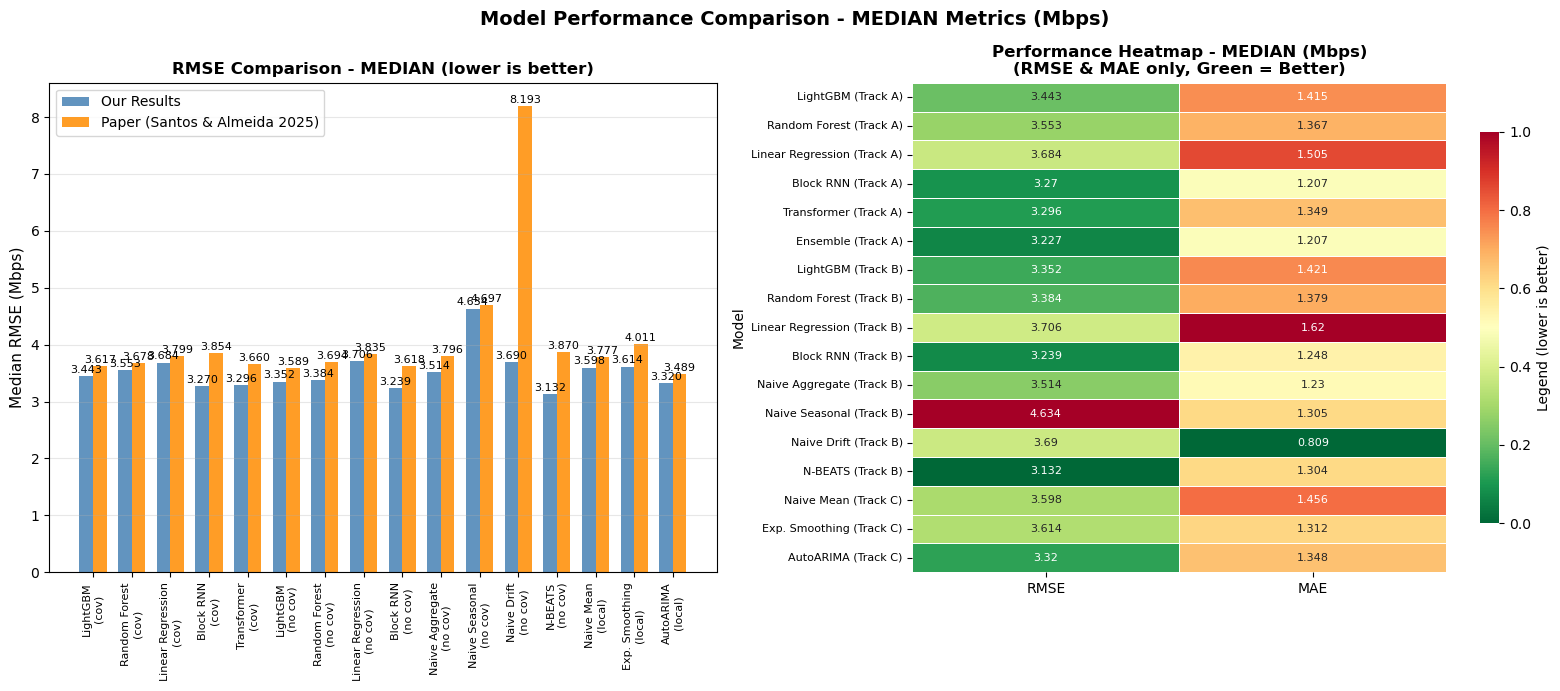


✅ Median metrics displayed in Mbps — 16/17 models have a paper reference value.


In [22]:
# use all_results_final (includes the ensemble) and the paper's
# published median RMSE values (Santos & Almeida 2025), split by track.

paper_median_ref = {
    'LightGBM (Track A)': 3.617,
    'LightGBM (Track B)': 3.589,
    'Random Forest (Track A)': 3.678,
    'Random Forest (Track B)': 3.694,
    'Linear Regression (Track A)': 3.799,
    'Linear Regression (Track B)': 3.835,
    'Block RNN (Track A)': 3.854,
    'Block RNN (Track B)': 3.618,
    'Transformer (Track A)': 3.660,
    'N-BEATS (Track B)': 3.870,
    'Naive Aggregate (Track B)': 3.796,
    'Naive Seasonal (Track B)': 4.697,
    'Naive Drift (Track B)': 8.193,
    'AutoARIMA (Track C)': 3.489,
    'Naive Mean (Track C)': 3.777,
    'Exp. Smoothing (Track C)': 4.011,
}

df_median = pd.DataFrame([
    {'Model': f"{r['model']} (Track {r['track']})", 'RMSE': r['rmse_median'], 'MAE': r['mae_median']}
    for r in all_results_final
])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Model Performance Comparison - MEDIAN Metrics (Mbps)', fontsize=14, fontweight='bold')

# plot 1: grouped bar chart, ours vs paper, for the models that have a paper reference
models_in_both_median = [(row['Model'], row['RMSE'], paper_median_ref[row['Model']])
                          for _, row in df_median.iterrows() if row['Model'] in paper_median_ref]

if models_in_both_median:
    names_median = [m[0].replace(' (Track A)', '\n(cov)').replace(' (Track B)', '\n(no cov)').replace(' (Track C)', '\n(local)')
                     for m in models_in_both_median]
    ours_median = [m[1] for m in models_in_both_median]
    paper_median = [m[2] for m in models_in_both_median]
    x_median = np.arange(len(names_median))
    w = 0.35

    axes[0].bar(x_median - w/2, ours_median, w, label='Our Results', color='steelblue', alpha=0.85)
    axes[0].bar(x_median + w/2, paper_median, w, label='Paper (Santos & Almeida 2025)', color='darkorange', alpha=0.85)
    axes[0].set_xticks(x_median)
    axes[0].set_xticklabels(names_median, rotation=90, ha='center', fontsize=8)
    axes[0].set_title('RMSE Comparison - MEDIAN (lower is better)', fontweight='bold', fontsize=12)
    axes[0].set_ylabel('Median RMSE (Mbps)', fontsize=11)
    axes[0].legend(loc='upper left', fontsize=10)
    axes[0].grid(alpha=0.3, axis='y')

    for bar1, bar2, o, p in zip(axes[0].containers[0], axes[0].containers[1], ours_median, paper_median):
        axes[0].text(bar1.get_x() + bar1.get_width()/2, bar1.get_height() + 0.02, f'{o:.3f}', ha='center', va='bottom', fontsize=8)
        axes[0].text(bar2.get_x() + bar2.get_width()/2, bar2.get_height() + 0.02, f'{p:.3f}', ha='center', va='bottom', fontsize=8)

# plot 2: heatmap of our RMSE/MAE medians across every model (incl. Ensemble)
hm_median = df_median.set_index('Model')[['RMSE', 'MAE']]
hn_median = (hm_median - hm_median.min()) / (hm_median.max() - hm_median.min())
sns.heatmap(hn_median, annot=hm_median.round(3), fmt='g', cmap='RdYlGn_r', ax=axes[1],
            cbar_kws={'label': 'Legend (lower is better)', 'shrink': 0.8},
            linewidths=0.5, annot_kws={'size': 8})
axes[1].set_title('Performance Heatmap - MEDIAN (Mbps)\n(RMSE & MAE only, Green = Better)', fontweight='bold', fontsize=12)
axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

print(f"\n✅ Median metrics displayed in Mbps — {len(models_in_both_median)}/{len(df_median)} models have a paper reference value.")


In [23]:
# build the same Model/Track/Our Median/Paper RMSE/Diff table as the mean
# comparison above, using median RMSE and the track-qualified paper_median_ref
# values (Table I) defined above, rather than the single-value-per-model
# paper_ref dict, since that one doesn't distinguish Track A from Track B.
print("\n" + "="*70)
print("COMPARISON WITH PAPER (Santos & Almeida 2025) — MEDIAN RMSE")
print("="*70)
print(f"{'Model':<22s} {'Track':>5s} {'Our Median':>10s} {'Paper RMSE':>12s} {'Diff':>10s}")
print("-"*70)

median_rows = sorted(all_results_final, key=lambda r: r['rmse_median'])
for r in median_rows:
    model_name, track = r['model'], r['track']
    key = f"{model_name} (Track {track})"
    paper_rmse = paper_median_ref.get(key)
    if paper_rmse is not None:
        diff = r['rmse_median'] - paper_rmse
        print(f"{model_name:<22s} {track:>5s} {r['rmse_median']:>10.4f} {paper_rmse:>12.3f} {diff:>+10.4f}")

print("="*70)


COMPARISON WITH PAPER (Santos & Almeida 2025) — MEDIAN RMSE
Model                  Track Our Median   Paper RMSE       Diff
----------------------------------------------------------------------
N-BEATS                    B     3.1316        3.870    -0.7384
Block RNN                  B     3.2389        3.618    -0.3791
Block RNN                  A     3.2700        3.854    -0.5840
Transformer                A     3.2961        3.660    -0.3639
AutoARIMA                  C     3.3202        3.489    -0.1688
LightGBM                   B     3.3522        3.589    -0.2368
Random Forest              B     3.3845        3.694    -0.3095
LightGBM                   A     3.4434        3.617    -0.1736
Naive Aggregate            B     3.5139        3.796    -0.2821
Random Forest              A     3.5532        3.678    -0.1248
Naive Mean                 C     3.5983        3.777    -0.1787
Exp. Smoothing             C     3.6139        4.011    -0.3971
Linear Regression          A     3.6

## Mean Metrics Comparison vs Paper (Santos & Almeida 2025, Figure 1)

Same as the median comparison above, using mean RMSE from the paper's Figure 1. Also flags models with the largest mean-vs-median gap (a sign of a heavy right tail).


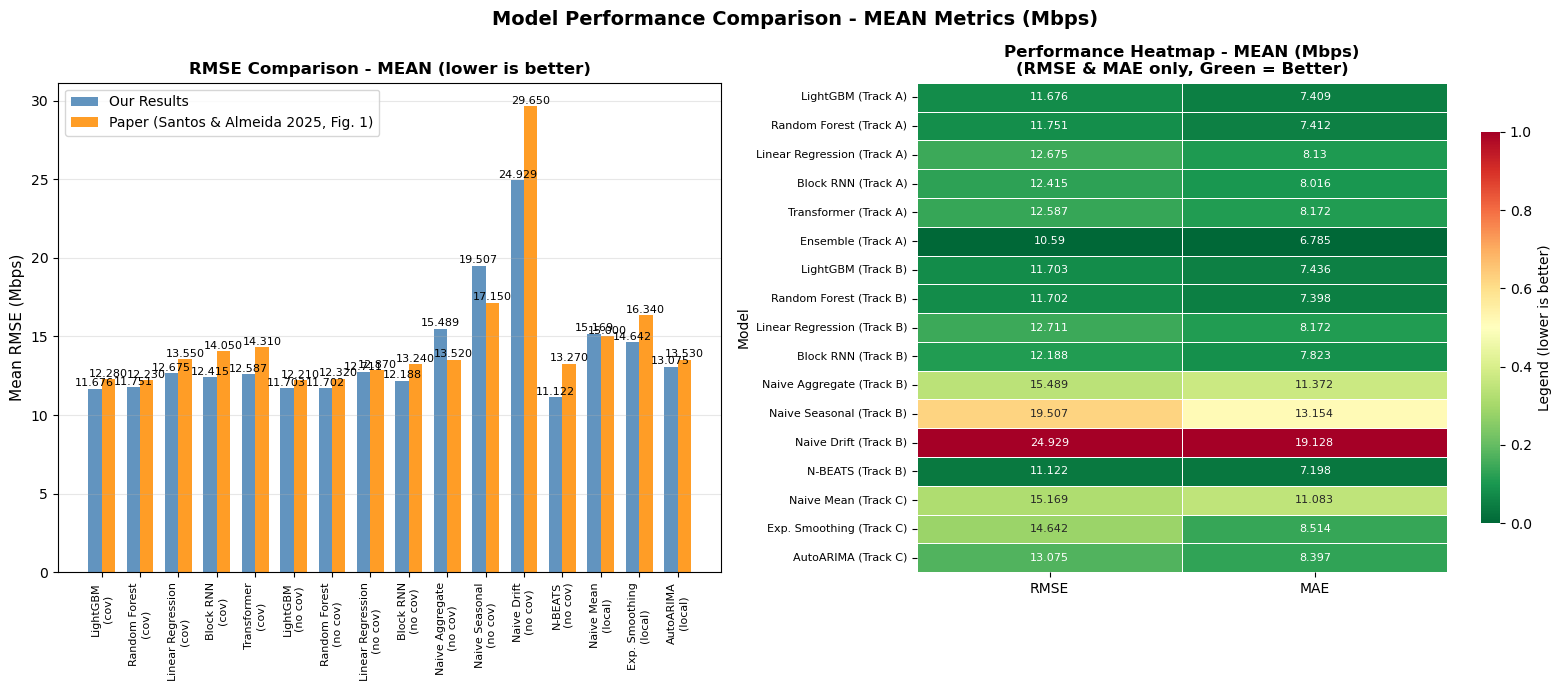


✅ Mean metrics displayed in Mbps — 16/17 models have a paper reference value (from Figure 1).

Mean − Median RMSE gap (top 5, largest first):
Model
Naive Drift (Track B)        21.239
Naive Seasonal (Track B)     14.874
Naive Aggregate (Track B)    11.975
Naive Mean (Track C)         11.570
Exp. Smoothing (Track C)     11.028


In [24]:
# Paper's mean RMSE comes from Figure 1 (a chart, not the Table I text) —
# values below transcribed directly from that figure. Same structure as
# the median chart above: grouped bars for models with a paper reference,
# heatmap for everything (incl. Ensemble, which has none).

paper_mean_ref = {
    'LightGBM (Track B)': 12.21,
    'Random Forest (Track A)': 12.23,
    'LightGBM (Track A)': 12.28,
    'Random Forest (Track B)': 12.32,
    'Linear Regression (Track B)': 12.87,
    'Block RNN (Track B)': 13.24,
    'N-BEATS (Track B)': 13.27,
    'Naive Aggregate (Track B)': 13.52,
    'AutoARIMA (Track C)': 13.53,
    'Linear Regression (Track A)': 13.55,
    'Block RNN (Track A)': 14.05,
    'Transformer (Track A)': 14.31,
    'Naive Mean (Track C)': 15.00,
    'Exp. Smoothing (Track C)': 16.34,
    'Naive Seasonal (Track B)': 17.15,
    'Naive Drift (Track B)': 29.65,
}

df_mean = pd.DataFrame([
    {'Model': f"{r['model']} (Track {r['track']})", 'RMSE': r['rmse_mean'], 'MAE': r['mae_mean']}
    for r in all_results_final
])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Model Performance Comparison - MEAN Metrics (Mbps)', fontsize=14, fontweight='bold')

# Plot 1: grouped bar chart, ours vs paper, for the models that have a paper reference
models_in_both_mean = [(row['Model'], row['RMSE'], paper_mean_ref[row['Model']])
                        for _, row in df_mean.iterrows() if row['Model'] in paper_mean_ref]

if models_in_both_mean:
    names_mean = [m[0].replace(' (Track A)', '\n(cov)').replace(' (Track B)', '\n(no cov)').replace(' (Track C)', '\n(local)')
                   for m in models_in_both_mean]
    ours_mean = [m[1] for m in models_in_both_mean]
    paper_mean = [m[2] for m in models_in_both_mean]
    x_mean = np.arange(len(names_mean))
    w = 0.35

    axes[0].bar(x_mean - w/2, ours_mean, w, label='Our Results', color='steelblue', alpha=0.85)
    axes[0].bar(x_mean + w/2, paper_mean, w, label='Paper (Santos & Almeida 2025, Fig. 1)', color='darkorange', alpha=0.85)
    axes[0].set_xticks(x_mean)
    axes[0].set_xticklabels(names_mean, rotation=90, ha='center', fontsize=8)
    axes[0].set_title('RMSE Comparison - MEAN (lower is better)', fontweight='bold', fontsize=12)
    axes[0].set_ylabel('Mean RMSE (Mbps)', fontsize=11)
    axes[0].legend(loc='upper left', fontsize=10)
    axes[0].grid(alpha=0.3, axis='y')

    for bar1, bar2, o, p in zip(axes[0].containers[0], axes[0].containers[1], ours_mean, paper_mean):
        axes[0].text(bar1.get_x() + bar1.get_width()/2, bar1.get_height() + 0.02, f'{o:.3f}', ha='center', va='bottom', fontsize=8)
        axes[0].text(bar2.get_x() + bar2.get_width()/2, bar2.get_height() + 0.02, f'{p:.3f}', ha='center', va='bottom', fontsize=8)

# Plot 2: heatmap of our RMSE/MAE means across every model (incl. Ensemble)
hm_mean = df_mean.set_index('Model')[['RMSE', 'MAE']]
hn_mean = (hm_mean - hm_mean.min()) / (hm_mean.max() - hm_mean.min())
sns.heatmap(hn_mean, annot=hm_mean.round(3), fmt='g', cmap='RdYlGn_r', ax=axes[1],
            cbar_kws={'label': 'Legend (lower is better)', 'shrink': 0.8},
            linewidths=0.5, annot_kws={'size': 8})
axes[1].set_title('Performance Heatmap - MEAN (Mbps)\n(RMSE & MAE only, Green = Better)', fontweight='bold', fontsize=12)
axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

print(f"\n✅ Mean metrics displayed in Mbps — {len(models_in_both_mean)}/{len(df_mean)} models have a paper reference value (from Figure 1).")

# Mean-vs-median gap, largest first — flags heavy right-tailed models
gap = (df_mean.set_index('Model')['RMSE'] - df_median.set_index('Model')['RMSE']).sort_values(ascending=False)
print("\nMean − Median RMSE gap (top 5, largest first):")
print(gap.head(5).round(3).to_string())


## Comparison With Paper — Mean RMSE (Table Form)

Same tabular format as the median comparison above, using mean RMSE and the track-qualified `paper_mean_ref` values from the mean comparison above (Figure 1).


In [25]:
# Build the same Model/Track/Our Mean/Paper RMSE/Diff table as the median
# comparison above, using mean RMSE and the track-qualified paper_mean_ref
# values (Figure 1) defined above, rather than the single-value-per-model
# paper_ref dict, since that one doesn't distinguish Track A from Track B.

print("\n" + "="*70)
print("COMPARISON WITH PAPER (Santos & Almeida 2025) — MEAN RMSE")
print("="*70)
print(f"{'Model':<22s} {'Track':>5s} {'Our Mean':>10s} {'Paper RMSE':>12s} {'Diff':>10s}")
print("-"*70)

mean_rows = sorted(all_results_final, key=lambda r: r['rmse_mean'])
for r in mean_rows:
    model_name, track = r['model'], r['track']
    key = f"{model_name} (Track {track})"
    paper_rmse = paper_mean_ref.get(key)
    if paper_rmse is not None:
        diff = r['rmse_mean'] - paper_rmse
        print(f"{model_name:<22s} {track:>5s} {r['rmse_mean']:>10.4f} {paper_rmse:>12.3f} {diff:>+10.4f}")

print("="*70)



COMPARISON WITH PAPER (Santos & Almeida 2025) — MEAN RMSE
Model                  Track   Our Mean   Paper RMSE       Diff
----------------------------------------------------------------------
N-BEATS                    B    11.1218       13.270    -2.1482
LightGBM                   A    11.6758       12.280    -0.6042
Random Forest              B    11.7017       12.320    -0.6183
LightGBM                   B    11.7031       12.210    -0.5069
Random Forest              A    11.7510       12.230    -0.4790
Block RNN                  B    12.1883       13.240    -1.0517
Block RNN                  A    12.4148       14.050    -1.6352
Transformer                A    12.5873       14.310    -1.7227
Linear Regression          A    12.6745       13.550    -0.8755
Linear Regression          B    12.7112       12.870    -0.1588
AutoARIMA                  C    13.0754       13.530    -0.4546
Exp. Smoothing             C    14.6416       16.340    -1.6984
Naive Mean                 C    15.168

## RL Setup — Actions, KPI Index, and Ensemble Forecast for the RL Trace

Applies the Track A ensemble (top 4 models, inverse-RMSE weighted) to a single trace to build the forecast series used by `SOEnvFused`/`MOEnvFused`.


In [26]:

def get_ensemble_predictions_for_trace(data, models, weights, seq_len=SEQ_LEN):
    """Reproduces the inverse-RMSE ensemble defined above for one trace, returning
    the (n, HORIZON) prediction array."""
    all_preds, valid_weights = [], []

    for model_info, w in zip(models, weights):
        pred, _ = get_ensemble_prediction(model_info, data, scaler_A, scaler_B, seq_len)
        if pred is None:
            continue
        all_preds.append(pred)
        valid_weights.append(w)

    if not all_preds:
        return None

    pred_stack = np.stack(all_preds, axis=0)  # (n_models, n_samples, HORIZON)
    weights_array = np.array(valid_weights).reshape(-1, 1, 1)
    weights_array = weights_array / weights_array.sum()  # renormalise over models actually available for this trace
    ensemble_pred = np.clip(np.sum(pred_stack * weights_array, axis=0), 0, None)
    return ensemble_pred  # (n_samples, HORIZON)

# ---- Select the RL trace: largest by row count, among traces that aren't
# dominated by zero-throughput readings (poor forecast signal otherwise). ----

ZERO_FRAC_MAX = 0.05  # exclude traces where >5% of rows have DL_Mbps == 0

candidate_traces = []
for t in numbered_traces:
    dl = t['dataframe']['DL_Mbps'].values
    zero_frac = float((dl == 0).mean())
    candidate_traces.append({**t, 'zero_frac': zero_frac})

clean_candidates = [t for t in candidate_traces if t['zero_frac'] <= ZERO_FRAC_MAX]

print(f"Traces with <= {ZERO_FRAC_MAX*100:.0f}% zero-throughput rows: {len(clean_candidates)} / {len(candidate_traces)}")

if clean_candidates:
    largest_trace_info = max(clean_candidates, key=lambda t: t['n_rows'])
else:
    # Fallback: if nothing clears the threshold, fall back to least-zero-heavy
    # trace instead of the previous "just take the biggest, zeros or not" rule.
    print(f"WARNING: no trace has <= {ZERO_FRAC_MAX*100:.0f}% zero rows -- falling back to the trace with the LOWEST zero fraction instead of the largest overall.")
    largest_trace_info = min(candidate_traces, key=lambda t: t['zero_frac'])

largest_tid = largest_trace_info['id']
print(f"Selected trace for RL: {largest_tid}  ({largest_trace_info['n_rows']} rows, {largest_trace_info['zero_frac']*100:.2f}% zero-throughput)")

rl_data = next(d for d in trace_data_list if d['trace_id'] == largest_tid)
lo_rl, hi_rl = rl_data['min_val'], rl_data['max_val']
print(f"DL range: {lo_rl:.2f}–{hi_rl:.2f} Mbps")

# Ensemble forecast + actual target for this trace's test portion
_, _, XA_test, y_te_rl = rl_data['track_A']

print(f"\nDebug - Before ensemble:")
print(f"  XA_test shape: {XA_test.shape}")
print(f"  y_te_rl shape: {y_te_rl.shape}")

ensemble_preds_multistep = get_ensemble_predictions_for_trace(rl_data, top4_models, weights, SEQ_LEN)

if ensemble_preds_multistep is None:
    raise RuntimeError(f"Could not generate ensemble predictions for {largest_tid}")

print(f"  ensemble_preds_multistep shape: {ensemble_preds_multistep.shape}")

# ---- Take the h=1 (one-step-ahead) column of both the multi-step target and
# the multi-step ensemble forecast ---- the RL environment needs a single
# scalar "current DL" and "current forecast" per step, and h=1 is the
# genuine "what's about to happen next" signal (rather than an average
# across the whole 10-step horizon).
y_te_single_step = y_te_rl[:, 0]           # Shape: (n_samples,)
ensemble_preds = ensemble_preds_multistep[:, 0]  # Shape: (n_samples,)

min_len = min(len(y_te_single_step), len(ensemble_preds))
y_te_aligned = y_te_single_step[:min_len]
ensemble_aligned = ensemble_preds[:min_len]

print(f"\nAfter alignment:")
print(f"  y_te_aligned shape: {y_te_aligned.shape}")
print(f"  ensemble_aligned shape: {ensemble_aligned.shape}")

# Raw (un-normalized) covariates for the same test origins
raw_df = next(t['dataframe'] for t in numbered_traces if t['id'] == largest_tid)
raw_cov_full = raw_df[COVARIATES].values.astype(float)

n_full = len(raw_df)
n_windows = n_full - N_LAGS - HORIZON
n_tr_rl = int(n_windows * TRAIN_FRAC)

test_start_raw_idx = N_LAGS + n_tr_rl
cov_aligned = raw_cov_full[test_start_raw_idx: test_start_raw_idx + min_len]

# Guard against off-by-one
final_len = min(len(y_te_aligned), len(ensemble_aligned), len(cov_aligned))
y_te_aligned = y_te_aligned[:final_len]
ensemble_aligned = ensemble_aligned[:final_len]
cov_aligned = cov_aligned[:final_len]

from scipy.stats import pearsonr

print(f"\nRL data ready:")
print(f"  Test samples: {len(y_te_aligned)}")
print(f"  Covariates shape: {cov_aligned.shape}")
print(f"  Forecast MAE (normalized): {np.mean(np.abs(y_te_aligned - ensemble_aligned)):.4f}")
print(f"  Forecast RMSE (normalized): {np.sqrt(np.mean((y_te_aligned - ensemble_aligned) ** 2)):.4f}")

if len(y_te_aligned) > 2 and np.std(y_te_aligned) > 0 and np.std(ensemble_aligned) > 0:
    corr, p_value = pearsonr(y_te_aligned, ensemble_aligned)
    print(f"  Forecast Pearson r: {corr:.4f}  (p={p_value:.4e})")
    if abs(corr) < 0.3:
        print(f"  WARNING: weak correlation -- this trace's zero-throughput fraction ({largest_trace_info['zero_frac']*100:.2f}%) or its overall dynamics may still be making it hard to forecast even after the zero-heavy filter above. Consider lowering ZERO_FRAC_MAX further or inspecting this trace directly.")
else:
    print(f"  Forecast Pearson r: undefined (zero variance in actual or predicted values -- check the zero-throughput fraction above)")

Traces with <= 5% zero-throughput rows: 20 / 83
Selected trace for RL: Download_Static_unknown_B_2020.02.27_18.39.27  (5568 rows, 1.72% zero-throughput)
DL range: 0.00–323.68 Mbps

Debug - Before ensemble:
  XA_test shape: (1111, 12)
  y_te_rl shape: (1111, 10)
  ensemble_preds_multistep shape: (1111, 10)

After alignment:
  y_te_aligned shape: (1111,)
  ensemble_aligned shape: (1111,)

RL data ready:
  Test samples: 1111
  Covariates shape: (1111, 6)
  Forecast MAE (normalized): 0.1217
  Forecast RMSE (normalized): 0.1618
  Forecast Pearson r: 0.8244  (p=2.3961e-276)


## Ensemble Forecast Quality — Actual vs Forecast

Checks forecast quality (MAE, RMSE, Pearson r) against the real signal before wiring it into the RL environments.


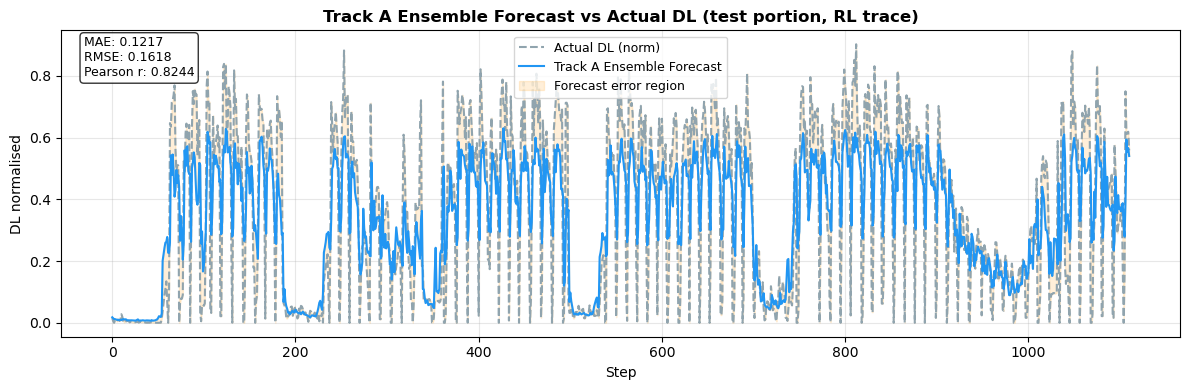


📊 Forecast Statistics: MAE=0.1217, RMSE=0.1618, Pearson r=0.8244

FORECAST CORRELATION ANALYSIS
Pearson correlation coefficient (r): 0.8244
P-value: 2.3961e-276
✓ Correlation is statistically significant (p < 0.05)

Interpretation of r = 0.8244:
  → Strong correlation - forecast captures underlying patterns well


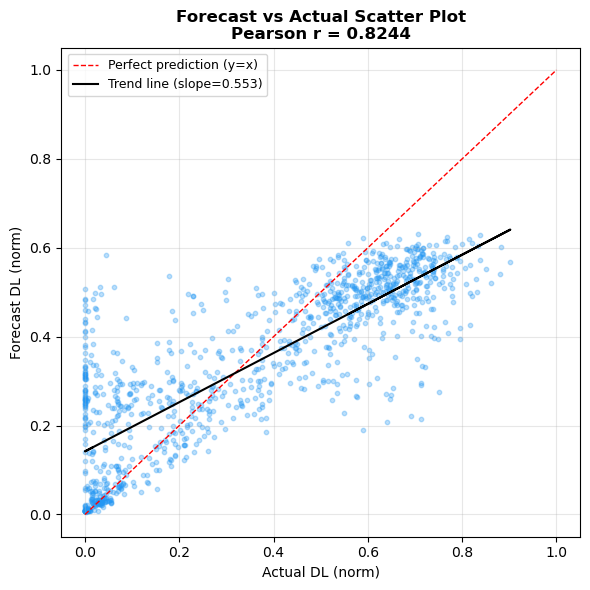

In [27]:
from scipy.stats import pearsonr

fig, ax = plt.subplots(figsize=(12, 4))

steps = np.arange(len(y_te_aligned))
actual = y_te_aligned
forecast = ensemble_aligned

# Metrics
mae = np.mean(np.abs(actual - forecast))
rmse = np.sqrt(np.mean((actual - forecast) ** 2))
corr, p_value = pearsonr(actual, forecast)

# Plot
ax.plot(steps, actual, color='#90A4AE', lw=1.5, ls='--', label='Actual DL (norm)')
ax.plot(steps, forecast, color='#2196F3', lw=1.5, label='Track A Ensemble Forecast')
ax.fill_between(steps, actual, forecast, alpha=0.15, color='#FF9800', label='Forecast error region')

metrics_text = f'MAE: {mae:.4f}\nRMSE: {rmse:.4f}\nPearson r: {corr:.4f}'
ax.text(0.02, 0.98, metrics_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_title('Track A Ensemble Forecast vs Actual DL (test portion, RL trace)',
             fontweight='bold', fontsize=12)
ax.set_xlabel('Step')
ax.set_ylabel('DL normalised')
ax.legend(fontsize=9, loc='upper center')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n📊 Forecast Statistics: MAE={mae:.4f}, RMSE={rmse:.4f}, Pearson r={corr:.4f}")

# Correlation analysis
print("\n" + "=" * 60)
print("FORECAST CORRELATION ANALYSIS")
print("=" * 60)
print(f"Pearson correlation coefficient (r): {corr:.4f}")
print(f"P-value: {p_value:.4e}")
if p_value < 0.05:
    print("✓ Correlation is statistically significant (p < 0.05)")
else:
    print("✗ Correlation is NOT statistically significant")

print(f"\nInterpretation of r = {corr:.4f}:")
if abs(corr) >= 0.7:
    print("  → Strong correlation - forecast captures underlying patterns well")
elif abs(corr) >= 0.5:
    print("  → Moderate correlation - forecast has reasonable predictive power")
elif abs(corr) >= 0.3:
    print("  → Weak correlation - forecast provides some information")
else:
    print("  → Negligible correlation - forecast has limited predictive value")

# Scatter plot for correlation visualisation
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(actual, forecast, alpha=0.3, color='#2196F3', s=10)
ax.plot([0, 1], [0, 1], 'r--', lw=1, label='Perfect prediction (y=x)')

z = np.polyfit(actual, forecast, 1)
p = np.poly1d(z)
ax.plot(actual, p(actual), 'k-', lw=1.5, label=f'Trend line (slope={z[0]:.3f})')

ax.set_xlabel('Actual DL (norm)')
ax.set_ylabel('Forecast DL (norm)')
ax.set_title(f'Forecast vs Actual Scatter Plot\nPearson r = {corr:.4f}', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()



N-BEATS FORECAST QUALITY - RL Trace Test Portion
N-BEATS predictions shape: (1111,)
Actual DL shape: (1111,)

📊 N-BEATS Forecast Statistics:
   MAE: 0.1922
   RMSE: 0.2584
   Pearson r: 0.4614
   P-value: 1.1808e-59


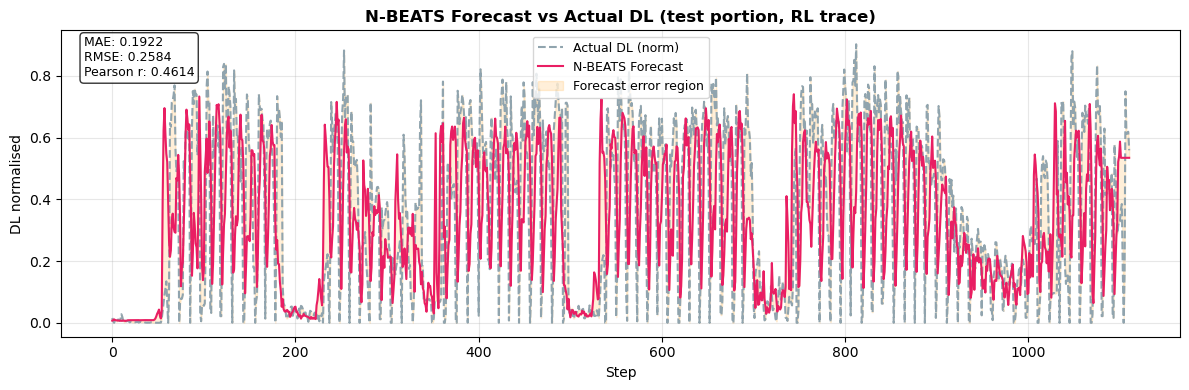

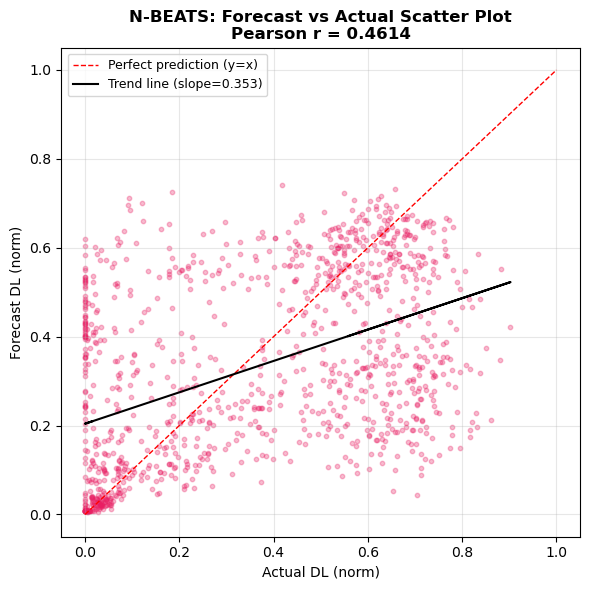


COMPARISON: N-BEATS vs ENSEMBLE
Metric               N-BEATS     Ensemble   Difference
-------------------------------------------------------
MAE                   0.1922       0.1217      +0.0706
RMSE                  0.2584       0.1618      +0.0967
Pearson r             0.4614       0.8244      -0.3630

N-BEATS FORECAST CORRELATION ANALYSIS
Pearson correlation coefficient (r): 0.4614
P-value: 1.1808e-59
✓ Correlation is statistically significant (p < 0.05)

Interpretation of r = 0.4614:
  → Weak correlation - forecast provides some information

CONCLUSION: N-BEATS vs ENSEMBLE for RL
✅ Ensemble has BETTER correlation (r=0.8244 vs 0.4614)
   Ensemble is better for the RL environment
✅ Ensemble has LOWER RMSE (0.1618 vs 0.2584)



In [28]:

from scipy.stats import pearsonr
import numpy as np
import matplotlib.pyplot as plt

print("\n" + "="*70)
print("N-BEATS FORECAST QUALITY - RL Trace Test Portion")
print("="*70)

# get the RL trace data
rl_data = next(d for d in trace_data_list if d['trace_id'] == largest_tid)
_, _, XA_test, y_te_rl = rl_data['track_A']

# get N-BEATS predictions for this trace
# get_ensemble_prediction returns (pred, y_test)
nbeats_pred_result = get_ensemble_prediction(
    {'model': 'N-BEATS', 'track': 'B'},  # N-BEATS is Track B
    rl_data,
    scaler_A,  # scaler_A works for Track B features too (same lags + rolling mean)
    scaler_B,
    SEQ_LEN
)

if nbeats_pred_result is None or nbeats_pred_result[0] is None:
    print("ERROR: Could not generate N-BEATS predictions for the RL trace")
    print("Using ensemble predictions as fallback...")
    nbeats_preds_multistep = ensemble_preds_multistep
    nbeats_preds = ensemble_aligned
    y_te_aligned_nb = y_te_aligned
else:
    nbeats_preds_multistep, y_test_nb = nbeats_pred_result
    # take the h=1 (one-step-ahead) column
    nbeats_preds = nbeats_preds_multistep[:, 0]
    
    # Align lengths - use y_test_nb which is the actual target for this model
    min_len = min(len(y_test_nb), len(nbeats_preds))
    y_te_aligned_nb = y_test_nb[:min_len, 0]  # h=1 column
    nbeats_preds = nbeats_preds[:min_len]
    
    print(f"N-BEATS predictions shape: {nbeats_preds.shape}")
    print(f"Actual DL shape: {y_te_aligned_nb.shape}")

actual = y_te_aligned_nb
forecast = nbeats_preds

# Metrics
mae = np.mean(np.abs(actual - forecast))
rmse = np.sqrt(np.mean((actual - forecast) ** 2))
corr, p_value = pearsonr(actual, forecast)

print(f"\n📊 N-BEATS Forecast Statistics:")
print(f"   MAE: {mae:.4f}")
print(f"   RMSE: {rmse:.4f}")
print(f"   Pearson r: {corr:.4f}")
print(f"   P-value: {p_value:.4e}")

# plot 1: Time Series Comparison

fig, ax = plt.subplots(figsize=(12, 4))

steps = np.arange(len(actual))

ax.plot(steps, actual, color='#90A4AE', lw=1.5, ls='--', label='Actual DL (norm)')
ax.plot(steps, forecast, color='#E91E63', lw=1.5, label='N-BEATS Forecast')
ax.fill_between(steps, actual, forecast, alpha=0.15, color='#FF9800', label='Forecast error region')

metrics_text = f'MAE: {mae:.4f}\nRMSE: {rmse:.4f}\nPearson r: {corr:.4f}'
ax.text(0.02, 0.98, metrics_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_title('N-BEATS Forecast vs Actual DL (test portion, RL trace)',
             fontweight='bold', fontsize=12)
ax.set_xlabel('Step')
ax.set_ylabel('DL normalised')
ax.legend(fontsize=9, loc='upper center')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# plot 2: Scatter Plot for Correlation

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(actual, forecast, alpha=0.3, color='#E91E63', s=10)
ax.plot([0, 1], [0, 1], 'r--', lw=1, label='Perfect prediction (y=x)')

z = np.polyfit(actual, forecast, 1)
p = np.poly1d(z)
ax.plot(actual, p(actual), 'k-', lw=1.5, label=f'Trend line (slope={z[0]:.3f})')

ax.set_xlabel('Actual DL (norm)')
ax.set_ylabel('Forecast DL (norm)')
ax.set_title(f'N-BEATS: Forecast vs Actual Scatter Plot\nPearson r = {corr:.4f}', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# get ensemble predictions for comparison
ensemble_actual = y_te_aligned
ensemble_forecast = ensemble_aligned

ens_mae = np.mean(np.abs(ensemble_actual - ensemble_forecast))
ens_rmse = np.sqrt(np.mean((ensemble_actual - ensemble_forecast) ** 2))
ens_corr, _ = pearsonr(ensemble_actual, ensemble_forecast)

print("\n" + "="*70)
print("COMPARISON: N-BEATS vs ENSEMBLE")
print("="*70)
print(f"{'Metric':<15} {'N-BEATS':>12} {'Ensemble':>12} {'Difference':>12}")
print("-"*55)
print(f"{'MAE':<15} {mae:>12.4f} {ens_mae:>12.4f} {mae - ens_mae:>+12.4f}")
print(f"{'RMSE':<15} {rmse:>12.4f} {ens_rmse:>12.4f} {rmse - ens_rmse:>+12.4f}")
print(f"{'Pearson r':<15} {corr:>12.4f} {ens_corr:>12.4f} {corr - ens_corr:>+12.4f}")

print("\n" + "=" * 60)
print("N-BEATS FORECAST CORRELATION ANALYSIS")
print("=" * 60)
print(f"Pearson correlation coefficient (r): {corr:.4f}")
print(f"P-value: {p_value:.4e}")
if p_value < 0.05:
    print("✓ Correlation is statistically significant (p < 0.05)")
else:
    print("✗ Correlation is NOT statistically significant")

print(f"\nInterpretation of r = {corr:.4f}:")
if abs(corr) >= 0.7:
    print("  → Strong correlation - forecast captures underlying patterns well")
elif abs(corr) >= 0.5:
    print("  → Moderate correlation - forecast has reasonable predictive power")
elif abs(corr) >= 0.3:
    print("  → Weak correlation - forecast provides some information")
else:
    print("  → Negligible correlation - forecast has limited predictive value")

print("\n" + "="*70)
print("CONCLUSION: N-BEATS vs ENSEMBLE for RL")
print("="*70)

if corr > ens_corr:
    print(f"✅ N-BEATS has BETTER correlation (r={corr:.4f} vs {ens_corr:.4f})")
    print(f"   N-BEATS is better for the RL environment")
else:
    print(f"✅ Ensemble has BETTER correlation (r={ens_corr:.4f} vs {corr:.4f})")
    print(f"   Ensemble is better for the RL environment")

if rmse < ens_rmse:
    print(f"✅ N-BEATS has LOWER RMSE ({rmse:.4f} vs {ens_rmse:.4f})")
else:
    print(f"✅ Ensemble has LOWER RMSE ({ens_rmse:.4f} vs {rmse:.4f})")

print("\n" + "="*70)

## Phase 1 — Shared simulated RL environments (Fused and Reactive)

Both variants now use the **same** SO/MO transition functions, action effects, KPI constraints, reward functions, trace, and training configuration. Fused observes six covariates + current normalized DL + ensemble forecast; Reactive observes the same seven variables **without the forecast**. The SO reward is post-action normalized DL throughput only in both variants. Proactive bonuses and volume-preservation penalties/reward blends have been removed from both. Volume is still tracked as an evaluation metric, not rewarded. Normalized DL is lower-bounded at zero and has no upper cap. These are simulated RF interventions, not observed network actions.

In [29]:

# Actions available to the RL agent
ACTIONS = ['Increase_TX_power', 'Adjust_beamforming', 'Optimise_MCS',
           'Reduce_interference', 'Increase_bandwidth', 'Load_balance']

# Covariate index map (order must match COVARIATES / the last 6 columns of Track A features)
COV_IDX = {'RSRP': 0, 'RSRQ': 1, 'SNR': 2, 'CQI': 3, 'RSSI': 4, 'Speed': 5}

# Single-Objective shared reward environment (Fused)
class SOEnvFused:
    """Single-objective with shared forecast-neutral reward: 
    reward = post-action normalized DL throughput only.
    Forecast affects the fused state only, never the reward."""
    
    DL_DELTAS = [0.08, 0.10, 0.12, 0.07, 0.09, 0.11]
    STEP_DURATION = 1.0

    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):
        self.yn, self.fc, self.cov = yn_te, fc, cov
        self.lo_rl, self.hi_rl = lo_rl, hi_rl
        self.N = len(yn_te)
        self.N_ACT = len(ACTIONS)
        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]
                       + [(0., 1.), (0., 1.)])
        self.idx = 0
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        self.episode_start_idx = 0
        self.action_stats = {i: {'count': 0, 'total_reward': 0.0, 'success_count': 0,
                                  'total_improvement': 0.0} for i in range(self.N_ACT)}

    def reset(self, random_start=True):
        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0
        self.episode_start_idx = self.idx
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        return self._state()

    def _state(self):
        c = self.cov[self.idx].astype(float)
        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])



    def step(self, action):
        i = self.idx
        dl = float(self.yn[i])
        dl_new = float(max(dl + self.DL_DELTAS[action], 0.))   # no upper clip: holdout DL may exceed the dev max (dev-only normalisation)
        dl_improvement = dl_new - dl

        dl_mbps_pre = dl * (self.hi_rl - self.lo_rl) + self.lo_rl
        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl
        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION
        volume_post_Mb = dl_mbps_post * self.STEP_DURATION
        self.cumulative_volume_pre_Mb += volume_pre_Mb
        self.cumulative_volume_post_Mb += volume_post_Mb

        # Base reward: normalized DL throughput
        base_reward = dl_new
        
        # No improvement shaping, forecast bonus, or volume bonus
        shaping_bonus = 0.0  # no SO improvement shaping
        
        # Forecast bonus disabled
        proactive_bonus = 0.0  # compatibility diagnostic only; no forecast bonus
        
        # Volume penalty disabled
        volume_penalty = 0.0  # compatibility diagnostic only; no volume penalty
        
        # Total reward: post-action normalized DL only
        reward = base_reward

        self.action_stats[action]['count'] += 1
        self.action_stats[action]['total_reward'] += reward
        self.action_stats[action]['total_improvement'] += dl_improvement
        if dl_new > dl:
            self.action_stats[action]['success_count'] += 1

        self.idx += 1
        done = self.idx >= self.N

        info = {
            'DL_norm_pre': dl, 'DL_norm_post': dl_new,
            'DL_improvement': dl_improvement, 'DL_improvement_pct': dl_improvement * 100,
            'DL_Mbps_pre': dl_mbps_pre, 'DL_Mbps_post': dl_mbps_post,
            'shaping_bonus': 0.0,  # retained diagnostic field; not part of reward
            'proactive_bonus': proactive_bonus,
            'SNR': float(self.cov[i, COV_IDX['SNR']]), 'RSRP': float(self.cov[i, COV_IDX['RSRP']]),
            'RSRQ': float(self.cov[i, COV_IDX['RSRQ']]), 'CQI': float(self.cov[i, COV_IDX['CQI']]),
            'RSSI': float(self.cov[i, COV_IDX['RSSI']]), 'Speed': float(self.cov[i, COV_IDX['Speed']]),
            'Ensemble_Forecast': float(self.fc[i]),
            'volume_pre_Mb': volume_pre_Mb, 'volume_post_Mb': volume_post_Mb,
            'cumulative_volume_pre_Mb': self.cumulative_volume_pre_Mb,
            'cumulative_volume_post_Mb': self.cumulative_volume_post_Mb,
            'volume_ratio': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),
            'volume_penalty': volume_penalty,
            'action': ACTIONS[action], 'action_index': action, 'done': done}
        next_state = self._state() if not done else None
        return next_state, reward, done, info

    def get_action_stats(self):
        stats = []
        for i in range(self.N_ACT):
            if self.action_stats[i]['count'] > 0:
                stats.append({
                    'action': ACTIONS[i], 'dl_delta': self.DL_DELTAS[i],
                    'dl_delta_pct': self.DL_DELTAS[i] * 100, 'count': self.action_stats[i]['count'],
                    'avg_reward': self.action_stats[i]['total_reward'] / self.action_stats[i]['count'],
                    'success_rate': self.action_stats[i]['success_count'] / self.action_stats[i]['count'] * 100,
                    'avg_improvement': self.action_stats[i]['total_improvement'] / self.action_stats[i]['count'] * 100
                })
        return pd.DataFrame(stats)

# Multi-Objective Environment with Ensemble Forecasting (Fused)
class MOEnvFused:
    """Reward = weighted sum of normalized KPI sub-rewards; no forecast or volume bonus."""

    W = {'DL': 0.50, 'RSRP': 0.15, 'RSRQ': 0.15, 'CQI': 0.08, 'RSSI': 0.10, 'SNR': 0.02}
    STEP_DURATION = 1.0
    ACTION_DELTAS = {
        0: {'DL': 0.08, 'RSRP': 1.4, 'RSRQ': 0.5, 'CQI': 0.5, 'RSSI': 1.0, 'SNR': 0.05},
        1: {'DL': 0.10, 'RSRP': 1.0, 'RSRQ': 1.0, 'CQI': 0.8, 'RSSI': 0.5, 'SNR': 0.08},
        2: {'DL': 0.12, 'RSRP': 0.6, 'RSRQ': 0.3, 'CQI': 1.2, 'RSSI': 0.3, 'SNR': 0.10},
        3: {'DL': 0.07, 'RSRP': 1.2, 'RSRQ': 1.5, 'CQI': 0.6, 'RSSI': 1.5, 'SNR': 0.12},
        4: {'DL': 0.09, 'RSRP': 0.7, 'RSRQ': 0.2, 'CQI': 0.4, 'RSSI': 2.0, 'SNR': 0.03},
        5: {'DL': 0.11, 'RSRP': 1.2, 'RSRQ': 0.8, 'CQI': 0.7, 'RSSI': 1.2, 'SNR': 0.08}}

    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):
        self.yn, self.fc, self.cov = yn_te, fc, cov
        self.lo_rl, self.hi_rl = lo_rl, hi_rl
        self.N = len(yn_te)
        self.N_ACT = len(ACTIONS)
        self.cov_min = cov.min(axis=0)
        self.cov_max = cov.max(axis=0)
        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]
                       + [(0., 1.), (0., 1.)])
        self.idx = 0
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        self.episode_start_idx = 0

    def reset(self, random_start=True):
        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0
        self.episode_start_idx = self.idx
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        return self._state()

    def _state(self):
        c = self.cov[self.idx].astype(float)
        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])

    def _norm_kpi(self, col_idx, val):
        lo = self.cov_min[col_idx]
        hi = self.cov_max[col_idx]
        span = max(hi - lo, 1e-9)
        return float(np.clip((val - lo) / span, 0.0, 1.0))



    def step(self, action):
        d = self.ACTION_DELTAS[action]
        i = self.idx

        dl_old = float(self.yn[i])
        rsrp_old = float(self.cov[i, 0])
        rsrq_old = float(self.cov[i, 1])
        cqi_old = float(self.cov[i, 3])
        rssi_old = float(self.cov[i, 4])
        snr_old = float(self.cov[i, 2])

        dl_new = float(max(dl_old + d['DL'], 0.0))   # no upper clip (see SO environment)
        rsrp_new = float(np.clip(rsrp_old + d['RSRP'], self.cov_min[0], self.cov_max[0]))
        rsrq_new = float(np.clip(rsrq_old + d['RSRQ'], self.cov_min[1], self.cov_max[1]))
        cqi_new = float(np.clip(cqi_old + d['CQI'], 0.0, 15.0))
        rssi_new = float(np.clip(rssi_old + d['RSSI'], self.cov_min[4], self.cov_max[4]))
        snr_new = float(np.clip(snr_old + d['SNR'], self.cov_min[2], self.cov_max[2]))

        dl_mbps_pre = dl_old * (self.hi_rl - self.lo_rl) + self.lo_rl
        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl
        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION
        volume_post_Mb = dl_mbps_post * self.STEP_DURATION
        self.cumulative_volume_pre_Mb += volume_pre_Mb
        self.cumulative_volume_post_Mb += volume_post_Mb

        r_dl = dl_new
        r_rsrp = self._norm_kpi(0, rsrp_new)
        r_rsrq = self._norm_kpi(1, rsrq_new)
        r_cqi = np.clip(cqi_new / 15.0, 0.0, 1.0)
        r_rssi = self._norm_kpi(4, rssi_new)
        r_snr = self._norm_kpi(2, snr_new)

        pb = 0.0  # compatibility diagnostic only; no forecast bonus

        W = self.W
        kpi_reward = (W['DL'] * r_dl + W['RSRP'] * r_rsrp + W['RSRQ'] * r_rsrq
                      + W['CQI'] * r_cqi + W['RSSI'] * r_rssi + W['SNR'] * r_snr)

        volume_reward = 0.0  # compatibility diagnostic only; no volume reward
        reward = kpi_reward

        self.idx += 1
        done = self.idx >= self.N

        info = {
            'DL_norm_pre': dl_old, 'DL_norm_post': dl_new,
            'DL_Mbps_pre': dl_mbps_pre, 'DL_Mbps_post': dl_mbps_post,
            'RSRP_pre': rsrp_old, 'RSRP_post': rsrp_new,
            'RSRQ_pre': rsrq_old, 'RSRQ_post': rsrq_new,
            'CQI_pre': cqi_old, 'CQI_post': cqi_new,
            'RSSI_pre': rssi_old, 'RSSI_post': rssi_new,
            'SNR_pre': snr_old, 'SNR_post': snr_new,
            'volume_pre_Mb': volume_pre_Mb, 'volume_post_Mb': volume_post_Mb,
            'cumulative_volume_pre_Mb': self.cumulative_volume_pre_Mb,
            'cumulative_volume_post_Mb': self.cumulative_volume_post_Mb,
            'volume_ratio': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),
            'volume_reward': volume_reward,
            'r_dl': r_dl, 'r_rsrp': r_rsrp, 'r_rsrq': r_rsrq,
            'r_cqi': r_cqi, 'r_rssi': r_rssi, 'r_snr': r_snr,
            'proactive_bonus': pb, 'Ensemble_Forecast': float(self.fc[i]),
            'action': ACTIONS[action], 'done': done}
        next_state = self._state() if not done else None
        return next_state, reward, done, info

print('Shared SO/MO environment definitions ready: forecast-neutral rewards, no volume bonuses.')
print('SO reward = post-action normalized DL only; MO reward = weighted radio-KPI score.')


Shared SO/MO environment definitions ready: forecast-neutral rewards, no volume bonuses.
SO reward = post-action normalized DL only; MO reward = weighted radio-KPI score.


## Instantiate Environments — Smoke Test

Confirms both environments construct correctly against the real ensemble data and take a few random steps without error before any Q-learning agent is trained on them.

In [30]:
env_so = SOEnvFused(y_te_aligned, ensemble_aligned, cov_aligned, lo_rl, hi_rl)
env_mo = MOEnvFused(y_te_aligned, ensemble_aligned, cov_aligned, lo_rl, hi_rl)

print(f"SOEnvFused: N={env_so.N} steps, state_dim={len(env_so.bounds)}, N_ACT={env_so.N_ACT}")
print(f"MOEnvFused: N={env_mo.N} steps, state_dim={len(env_mo.bounds)}, N_ACT={env_mo.N_ACT}")

print("\n--- SO smoke test (5 random steps) ---")
s = env_so.reset(random_start=False)
print(f"Initial state shape: {s.shape}")
for _ in range(5):
    a = np.random.randint(env_so.N_ACT)
    s, r, done, info = env_so.step(a)
    print(f"  action={info['action']:<20s} reward={r:.4f} DL_norm={info['DL_norm_post']:.4f} done={done}")
    if done:
        break

print("\n--- MO smoke test (5 random steps) ---")
s = env_mo.reset(random_start=False)
print(f"Initial state shape: {s.shape}")
for _ in range(5):
    a = np.random.randint(env_mo.N_ACT)
    s, r, done, info = env_mo.step(a)
    print(f"  action={info['action']:<20s} reward={r:.4f} DL_norm={info['DL_norm_post']:.4f} "
          f"r_dl={info['r_dl']:.3f} done={done}")
    if done:
        break

print("\nBoth environments constructed and stepped successfully.")


SOEnvFused: N=1111 steps, state_dim=8, N_ACT=6
MOEnvFused: N=1111 steps, state_dim=8, N_ACT=6

--- SO smoke test (5 random steps) ---
Initial state shape: (8,)
  action=Reduce_interference  reward=0.0856 DL_norm=0.0856 done=False
  action=Increase_bandwidth   reward=0.0955 DL_norm=0.0955 done=False
  action=Optimise_MCS         reward=0.1200 DL_norm=0.1200 done=False
  action=Increase_bandwidth   reward=0.0982 DL_norm=0.0982 done=False
  action=Increase_bandwidth   reward=0.0985 DL_norm=0.0985 done=False

--- MO smoke test (5 random steps) ---
Initial state shape: (8,)
  action=Adjust_beamforming   reward=0.3333 DL_norm=0.1156 r_dl=0.116 done=False
  action=Optimise_MCS         reward=0.3663 DL_norm=0.1255 r_dl=0.126 done=False
  action=Optimise_MCS         reward=0.3636 DL_norm=0.1200 r_dl=0.120 done=False
  action=Optimise_MCS         reward=0.3244 DL_norm=0.1282 r_dl=0.128 done=False
  action=Increase_bandwidth   reward=0.3224 DL_norm=0.0985 r_dl=0.098 done=False

Both environments 

**Next step:** train SO and MO tabular Q-learning agents on `env_so`/`env_mo`

## Q-Learning Agent + Aliases

Tabular Q-learning agent with per-dimension state discretization. Works unchanged for both `SOEnvFused` and `MOEnvFused`.


In [31]:
from collections import defaultdict

# Aliases used by the evaluation and plotting cells
y_test = y_te_aligned
cov_test = cov_aligned

class QLAgent:
    def __init__(self, env, alpha=0.15, gamma=0.92,
                 eps=1.0, eps_decay=0.007, eps_min=0.05, nb=5):
        self.alpha = alpha; self.gamma = gamma
        self.eps   = eps;   self.eps_decay = eps_decay; self.eps_min = eps_min
        self.nb    = nb;    self.n_act = env.N_ACT
        self.Q      = defaultdict(lambda: np.zeros(self.n_act))
        self.bounds = env.bounds

    def _disc(self, s):
        bk = []
        for v, (lo, hi) in zip(s, self.bounds):
            span = max(hi - lo, 1e-9)
            bk.append(int(np.clip((v - lo) / span * self.nb, 0, self.nb - 1)))
        return tuple(bk)

    def choose(self, s):
        if np.random.random() < self.eps:
            return np.random.randint(self.n_act)
        return int(np.argmax(self.Q[self._disc(s)]))

    def update(self, s, a, r, s_next):
        if s_next is None:
            return
        k  = self._disc(s)
        k_ = self._disc(s_next)
        self.Q[k][a] += self.alpha * (r + self.gamma * np.max(self.Q[k_]) - self.Q[k][a])

    def decay(self):
        self.eps = max(self.eps_min, self.eps - self.eps_decay)

print('QLAgent defined.')

QLAgent defined.


## Greedy Simulation Function


In [32]:
def simulate(agent, env, n_steps, fixed_start=0):
    """Run greedy policy with FIXED starting index for fair comparison."""
    saved_eps  = agent.eps
    agent.eps  = 0.0
    
    # reset with fixed index for consistent baseline
    env.idx = fixed_start
    env.episode_start_idx = fixed_start
    env.cumulative_volume_pre_Mb = 0.0
    env.cumulative_volume_post_Mb = 0.0
    
    s = env._state()
    traj = []
    
    for step in range(1, n_steps + 1):
        a = agent.choose(s)
        ns, r, done, info = env.step(a)
        traj.append({'step': step, 'reward': r,
                     'action': ACTIONS[a], **{k: info[k] for k in info if k not in ('done','action')}})
        if done: 
            break
        s = ns
    
    agent.eps = saved_eps
    return pd.DataFrame(traj)

## Shared RL experiment configuration

Frozen 20 evaluation starts, 500 episodes, same seed and hyperparameters for both policy types. Fused and Reactive are trained in separate stages with fresh environments and Q-tables. The data are **not** RL-held-out; training and evaluation use the same aligned trace. Nonoverlapping evaluation windows are used only if the trace is sufficiently long.

In [33]:
# Shared experimental configuration. Freeze once; both runs use identical settings.
RL_SEED = 42
N_EP = 500
RL_TRAIN_STEPS = 50
N_CV_SEGS = 20
SEG_LEN = 200
FIXED_START = 215

n_available = len(y_te_aligned)
if n_available < SEG_LEN:
    raise ValueError(f'RL trace has {n_available} samples; need at least {SEG_LEN}.')
if FIXED_START >= n_available:
    raise ValueError('FIXED_START is outside the aligned trace.')
N_SIM = min(200, n_available - FIXED_START)

# Use 20 non-overlapping segments if possible; otherwise retain 20 distinct
# start positions and explicitly report that evaluation segments overlap.
if n_available >= N_CV_SEGS * SEG_LEN:
    cv_starts = np.linspace(0, n_available - SEG_LEN, N_CV_SEGS, dtype=int)
    # Evenly spaced starts may overlap despite adequate total length; use exact blocks.
    cv_starts = np.arange(N_CV_SEGS, dtype=int) * SEG_LEN
    evaluation_overlap = False
else:
    max_start = n_available - SEG_LEN
    if max_start + 1 < N_CV_SEGS:
        raise ValueError('Not enough distinct evaluation starts for 20 segments.')
    cv_starts = np.sort(np.random.default_rng(RL_SEED).choice(
        max_start + 1, size=N_CV_SEGS, replace=False))
    evaluation_overlap = True

print('Evaluation starts:', cv_starts.tolist())
print('Segments overlap:', evaluation_overlap)
print('Caution: RL agents are trained on this same aligned trace; segment separation alone is NOT a held-out RL evaluation.')

def train_policy_independently(env, seed):
    # Reset the global numpy RNG at the start of EACH training run.
    np.random.seed(seed)
    agent = QLAgent(env)
    rewards = []
    for _ in range(N_EP):
        state = env.reset(random_start=True)
        total = 0.0
        for _ in range(min(RL_TRAIN_STEPS, env.N)):
            action = agent.choose(state)
            next_state, reward, done, _ = env.step(action)
            agent.update(state, action, reward, next_state)
            total += reward
            if done:
                break
            state = next_state
        agent.decay()
        rewards.append(total)
    return agent, rewards

def evaluate_policy_segments(agent, env, label):
    rows = []
    for j, start in enumerate(cv_starts, 1):
        start = int(start)
        baseline = y_te_aligned[start:start+SEG_LEN] * (hi_rl - lo_rl) + lo_rl
        traj = simulate(agent, env, SEG_LEN, fixed_start=start)
        if len(traj) != SEG_LEN:
            raise AssertionError(f'{label}: segment {j} produced {len(traj)} steps, expected {SEG_LEN}.')
        mean_before = float(np.mean(baseline))
        mean_after = float(traj['DL_Mbps_post'].mean())
        gain = 100.0 * (mean_after - mean_before) / max(mean_before, 1e-9)
        rows.append({'Segment':j, 'Start':start, 'Policy':label,
                     'Baseline DL (Mbps)':mean_before, 'Post DL (Mbps)':mean_after,
                     'DL improvement (%)':gain})
    return pd.DataFrame(rows)


Evaluation starts: [77, 79, 84, 116, 181, 388, 393, 410, 466, 475, 585, 627, 650, 665, 689, 691, 713, 765, 771, 881]
Segments overlap: True
Caution: RL agents are trained on this same aligned trace; segment separation alone is NOT a held-out RL evaluation.


## Stage 1 — Train Fused SO and MO only

In [34]:
# STAGE 1: fresh Fused environments, train Fused SO and MO only.
# Forecast enters the fused state; rewards contain neither proactive nor volume bonuses.
env_so = SOEnvFused(y_te_aligned, ensemble_aligned, cov_aligned, lo_rl, hi_rl)
env_mo = MOEnvFused(y_te_aligned, ensemble_aligned, cov_aligned, lo_rl, hi_rl)
so_agent, so_rewards = train_policy_independently(env_so, seed=RL_SEED)
mo_agent, mo_rewards = train_policy_independently(env_mo, seed=RL_SEED)
print('FUSED training complete. SO/MO Q states:',len(so_agent.Q),len(mo_agent.Q))


FUSED training complete. SO/MO Q states: 567 567


## Stage 1 — Evaluate Fused SO and MO; save 20-segment results

In [35]:
# STAGE 1: finish Fused evaluation BEFORE creating/training Reactive agents.
so_traj = simulate(so_agent, env_so, N_SIM, fixed_start=FIXED_START)
mo_traj = simulate(mo_agent, env_mo, N_SIM, fixed_start=FIXED_START)
baseline_dl = y_te_aligned[FIXED_START:FIXED_START + N_SIM] * (hi_rl - lo_rl) + lo_rl
so_traj['baseline_Mbps'] = baseline_dl[:len(so_traj)]
mo_traj['baseline_Mbps'] = baseline_dl[:len(mo_traj)]
so_dl_imp = 100 * (so_traj['DL_Mbps_post'].mean() - baseline_dl.mean()) / max(baseline_dl.mean(),1e-9)
mo_dl_imp = 100 * (mo_traj['DL_Mbps_post'].mean() - baseline_dl.mean()) / max(baseline_dl.mean(),1e-9)
print(f'Fused fixed segment SO={so_dl_imp:+.3f}% MO={mo_dl_imp:+.3f}%')
fused_so_segments = evaluate_policy_segments(so_agent, env_so, 'Fused SO')
fused_mo_segments = evaluate_policy_segments(mo_agent, env_mo, 'Fused MO')
fused_segment_results = pd.concat([fused_so_segments, fused_mo_segments],ignore_index=True)
print('FUSED 20-segment results (complete before Reactive training):')
print(fused_segment_results.pivot(index=['Segment','Start'],columns='Policy',values='DL improvement (%)').to_string(float_format=lambda x:f'{x:+.3f}'))


Fused fixed segment SO=+29.925% MO=+28.969%
FUSED 20-segment results (complete before Reactive training):
Policy         Fused MO  Fused SO
Segment Start                    
1       77      +24.296   +25.450
2       79      +24.391   +25.548
3       84      +24.987   +26.170
4       116     +27.486   +28.537
5       181     +36.321   +37.673
6       388     +22.325   +23.102
7       393     +22.239   +23.076
8       410     +22.630   +23.366
9       466     +22.233   +22.856
10      475     +21.994   +22.710
11      585     +23.227   +23.955
12      627     +21.631   +22.285
13      650     +22.056   +22.808
14      665     +22.349   +23.021
15      689     +21.862   +22.365
16      691     +21.672   +22.229
17      713     +21.052   +21.627
18      765     +21.386   +21.896
19      771     +22.159   +22.685
20      881     +29.885   +30.659


## Fused policy diagnostics and network interpretation

## SO Agent Visualisation

Six-panel dashboard for the SO agent:
- **Convergence** — per-episode total reward (raw + 30-episode smoothed) with final 100-episode average
- **DL throughput** — baseline vs optimised over simulation steps (green fill = improvement, red fill = degradation)
- **KPI change (%)** — percentage change for all six KPIs relative to baseline; SO only optimises DL so other KPIs reflect passive side-effects of the chosen actions
- **Action frequency** — count and percentage of each action under the greedy policy
- **Reward per step** — step-by-step reward trace during simulation with mean line
- **ε decay curve** — exploration rate schedule over the 500 training episodes

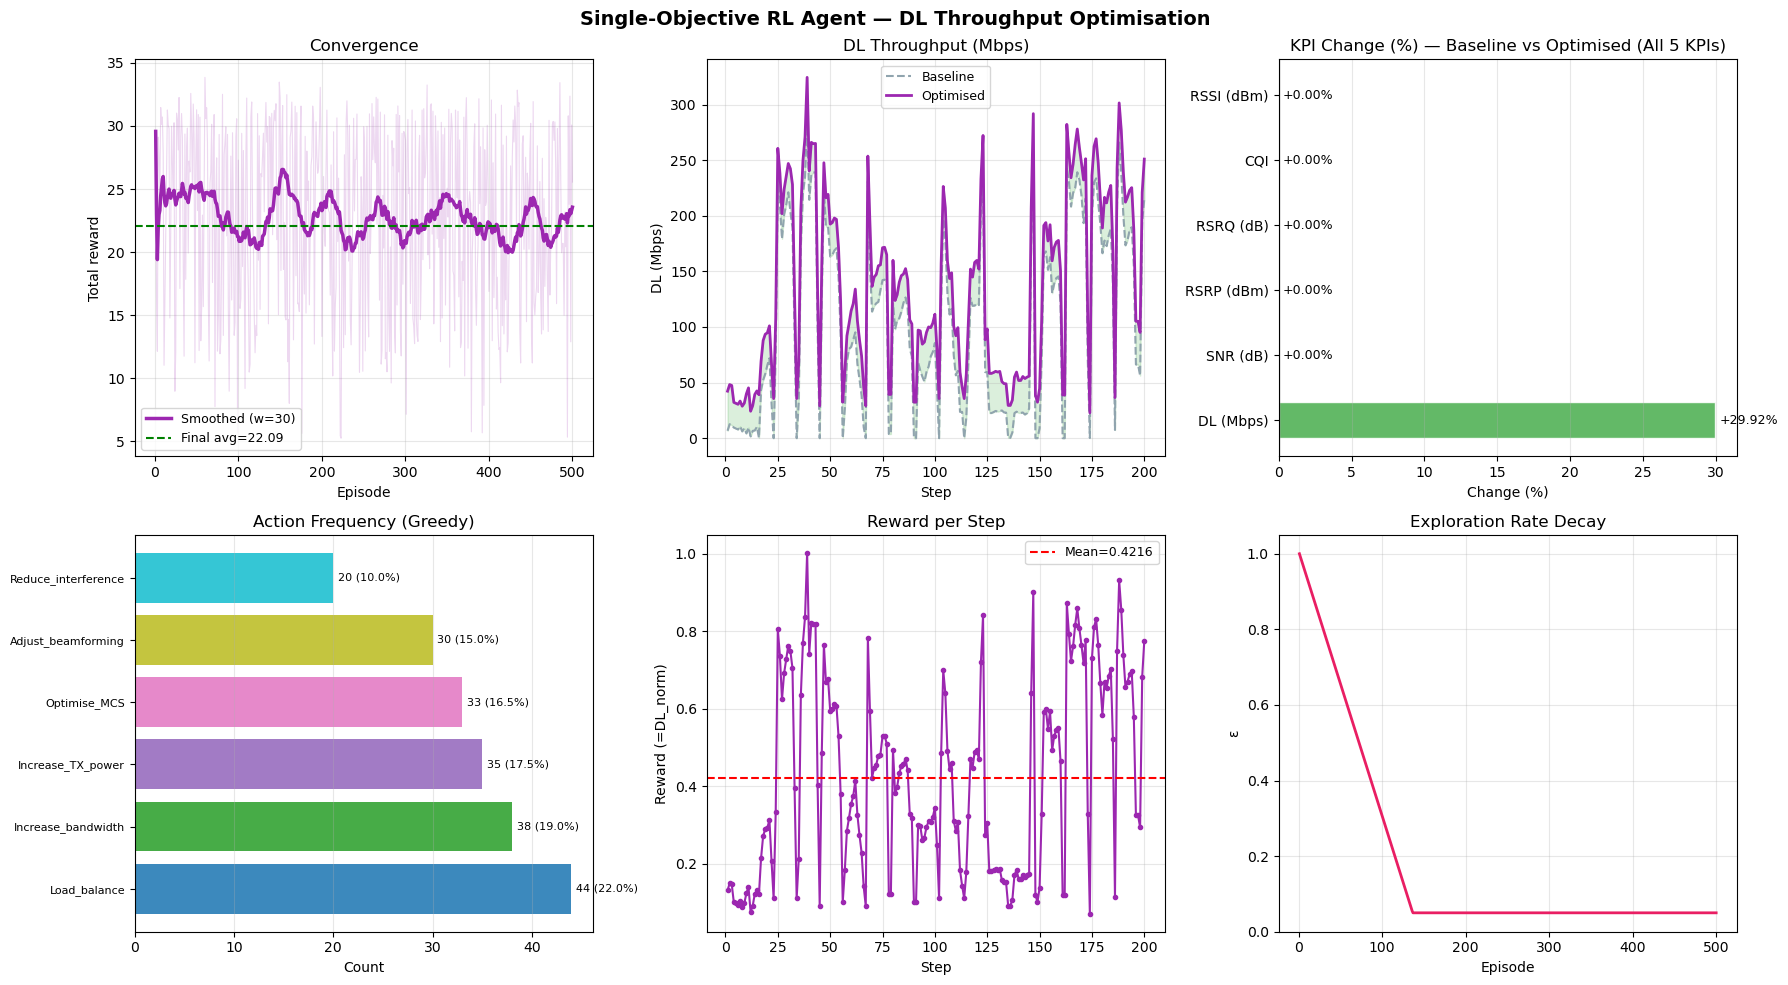

In [36]:
def smooth(d, w=30):
    return pd.Series(d).rolling(w, min_periods=1).mean().values

steps = np.arange(1, len(so_traj) + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Single-Objective RL Agent — DL Throughput Optimisation',
             fontsize=14, fontweight='bold')

# Convergence
ax = axes[0,0]
ep_x = np.arange(1, N_EP+1)
ax.plot(ep_x, so_rewards, alpha=0.18, color='#9C27B0', lw=0.8)
ax.plot(ep_x, smooth(so_rewards), color='#9C27B0', lw=2.5, label='Smoothed (w=30)')
ax.axhline(np.mean(so_rewards[-100:]), color='green', ls='--', lw=1.5,
           label=f'Final avg={np.mean(so_rewards[-100:]):.2f}')
ax.set_title('Convergence'); ax.set_xlabel('Episode'); ax.set_ylabel('Total reward')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# DL throughput
ax = axes[0,1]
ax.plot(steps, so_traj['baseline_Mbps'], color='#90A4AE', lw=1.5, ls='--', label='Baseline')
ax.plot(steps, so_traj['DL_Mbps_post'], color='#9C27B0', lw=2.0, label='Optimised')
ax.fill_between(steps, so_traj['baseline_Mbps'], so_traj['DL_Mbps_post'],
                where=so_traj['DL_Mbps_post']>so_traj['baseline_Mbps'], alpha=0.2, color='#4CAF50')
ax.fill_between(steps, so_traj['baseline_Mbps'], so_traj['DL_Mbps_post'],
                where=so_traj['DL_Mbps_post']<so_traj['baseline_Mbps'], alpha=0.12, color='#F44336')
ax.set_title('DL Throughput (Mbps)'); ax.set_xlabel('Step'); ax.set_ylabel('DL (Mbps)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# KPI bar (all 5 KPIs: RSRP, RSRQ, SNR, CQI, RSSI)
ax = axes[0,2]
kpi_cols = ['DL_Mbps_post', 'SNR', 'RSRP', 'RSRQ', 'CQI', 'RSSI']
kpi_labels = ['DL (Mbps)', 'SNR (dB)', 'RSRP (dBm)', 'RSRQ (dB)', 'CQI', 'RSSI (dBm)']

# get baseline values from test data
sim_start = FIXED_START
sim_end = sim_start + len(so_traj)
baseline_kpi = {
    'DL_Mbps_post': baseline_dl.mean(),
    'SNR': cov_test[sim_start:sim_end, 2].mean(),
    'RSRP': cov_test[sim_start:sim_end, 0].mean(),
    'RSRQ': cov_test[sim_start:sim_end, 1].mean(),
    'CQI': cov_test[sim_start:sim_end, 3].mean(),
    'RSSI': cov_test[sim_start:sim_end, 4].mean(),
}

# get optimised values from SO trajectory
opt_kpi = {
    'DL_Mbps_post': so_traj['DL_Mbps_post'].mean(),
    'SNR': so_traj['SNR'].mean() if 'SNR' in so_traj.columns else None,
    'RSRP': so_traj['RSRP'].mean() if 'RSRP' in so_traj.columns else None,
    'RSRQ': so_traj['RSRQ'].mean() if 'RSRQ' in so_traj.columns else None,
    'CQI': so_traj['CQI'].mean() if 'CQI' in so_traj.columns else None,
    'RSSI': so_traj['RSSI'].mean() if 'RSSI' in so_traj.columns else None,
}

# calculate percentage changes (skip if None)
pcts = []
valid_labels = []
valid_colors = []
for k, label in zip(kpi_cols, kpi_labels):
    if opt_kpi[k] is not None:
        base_val = baseline_kpi[k]
        opt_val = opt_kpi[k]
        pct = (opt_val - base_val) / max(abs(base_val), 1e-9) * 100
        pcts.append(pct)
        valid_labels.append(label)
        valid_colors.append('#4CAF50' if pct >= 0 else '#F44336')

# plot bar chart
bars = ax.barh(valid_labels, pcts, color=valid_colors, alpha=0.87, edgecolor='white', height=0.55)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('KPI Change (%) — Baseline vs Optimised (All 5 KPIs)')
ax.set_xlabel('Change (%)'); ax.grid(alpha=0.3, axis='x')
for bar, v in zip(bars, pcts):
    ax.text(v+(0.3 if v>=0 else -0.3), bar.get_y()+bar.get_height()/2,
            f'{v:+.2f}%', va='center', ha='left' if v>=0 else 'right', fontsize=9)

# Action frequency (WITH PERCENTAGE LABELS)
ax = axes[1,0]
ac = so_traj['action'].value_counts()
cmap = plt.get_cmap('tab10', len(ac))
bars_ac = ax.barh(range(len(ac)), ac.values, color=[cmap(i) for i in range(len(ac))], alpha=0.87)
ax.set_yticks(range(len(ac)))
ax.set_yticklabels(ac.index, fontsize=8)
ax.set_title('Action Frequency (Greedy)'); ax.set_xlabel('Count')
ax.grid(alpha=0.3, axis='x')

# add percentage labels to action bars
total_actions = len(so_traj)
for i, (action, count) in enumerate(ac.items()):
    pct = count / total_actions * 100
    ax.text(count + 0.5, i, f'{count} ({pct:.1f}%)', va='center', fontsize=8)

# Reward per step
ax = axes[1,1]
ax.plot(so_traj['step'], so_traj['reward'], color='#9C27B0', lw=1.5, marker='o', ms=3)
ax.axhline(so_traj['reward'].mean(), color='red', ls='--', lw=1.5,
           label=f'Mean={so_traj["reward"].mean():.4f}')
ax.set_title('Reward per Step'); ax.set_xlabel('Step'); ax.set_ylabel('Reward (=DL_norm)')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# Epsilon decay
ax = axes[1,2]
eps_curve = [max(so_agent.eps_min, 1.0 - i*so_agent.eps_decay) for i in range(N_EP)]
ax.plot(range(1, N_EP+1), eps_curve, color='#E91E63', lw=2)
ax.set_title('Exploration Rate Decay'); ax.set_xlabel('Episode'); ax.set_ylabel('ε')
ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## MO Agent Visualisation

Six-panel dashboard for the MO agent:
- **Convergence** — per-episode MO reward (raw + smoothed) with final average
- **DL throughput** — baseline vs optimised (same format as SO for direct comparison)
- **KPI improvement (%)** — all six objectives with percentage change; unlike SO, all KPIs are actively optimised
- **Weighted sub-reward decomposition** — mean per-step contribution of each KPI component (`raw_value × weight`), showing how the reward budget is distributed
- **Action frequency** — greedy policy action distribution with percentages
- **Normalised KPI comparison** — baseline vs optimised values row-normalised across KPIs for visual scale-free comparison

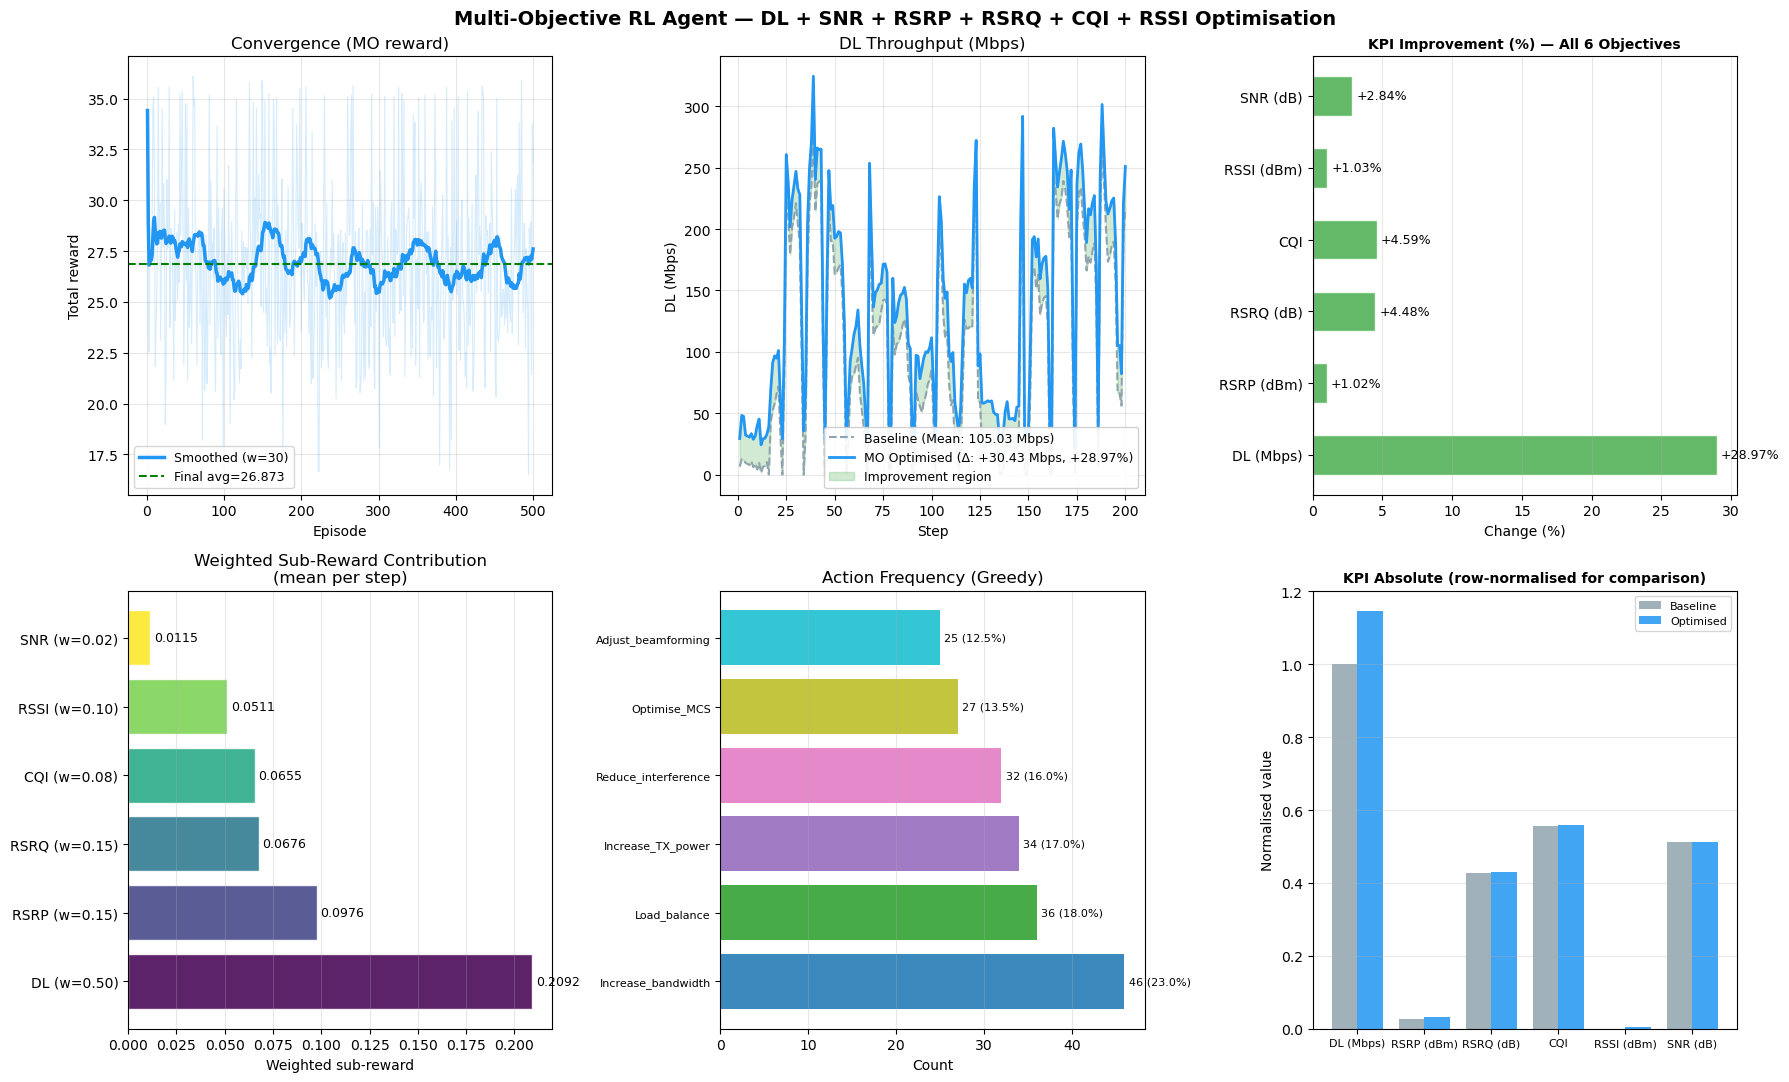

In [37]:
steps_mo = np.arange(1, len(mo_traj) + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Multi-Objective RL Agent — DL + SNR + RSRP + RSRQ + CQI + RSSI Optimisation',
             fontsize=14, fontweight='bold')

# DL throughput
ax = axes[0,1]

# calculate improvement statistics
baseline_mean = mo_traj['baseline_Mbps'].mean()
optimised_mean = mo_traj['DL_Mbps_post'].mean()
improvement_abs = optimised_mean - baseline_mean
improvement_pct = (improvement_abs / max(abs(baseline_mean), 1e-9)) * 100

# plot only improvement region (green)
ax.plot(steps_mo, mo_traj['baseline_Mbps'], color='#90A4AE', lw=1.5, ls='--', 
        label=f'Baseline (Mean: {baseline_mean:.2f} Mbps)')
ax.plot(steps_mo, mo_traj['DL_Mbps_post'], color='#2196F3', lw=2.0,
        label=f'MO Optimised (Δ: {improvement_abs:+.2f} Mbps, {improvement_pct:+.2f}%)')
ax.fill_between(steps_mo, mo_traj['baseline_Mbps'], mo_traj['DL_Mbps_post'],
                where=mo_traj['DL_Mbps_post'] > mo_traj['baseline_Mbps'], 
                alpha=0.25, color='#4CAF50', label='Improvement region')
ax.set_title('DL Throughput (Mbps)'); ax.set_xlabel('Step')
ax.set_ylabel('DL (Mbps)'); ax.legend(fontsize=9, loc='lower right', framealpha=0.9)
ax.grid(alpha=0.3)

# KPI improvement bar
ax = axes[0,2]
kpi_metrics = ['DL (Mbps)', 'RSRP (dBm)', 'RSRQ (dB)', 'CQI', 'RSSI (dBm)', 'SNR (dB)'] 
kpi_pre = [baseline_dl.mean(),
           cov_test[FIXED_START:FIXED_START+N_SIM, 0].mean(),
           cov_test[FIXED_START:FIXED_START+N_SIM, 1].mean(),
           cov_test[FIXED_START:FIXED_START+N_SIM, 3].mean(),
           cov_test[FIXED_START:FIXED_START+N_SIM, 4].mean(),
           cov_test[FIXED_START:FIXED_START+N_SIM, 2].mean()]  # SNR (index 2)

kpi_post = [mo_traj['DL_Mbps_post'].mean(),
            mo_traj['RSRP_post'].mean(),
            mo_traj['RSRQ_post'].mean(),
            mo_traj['CQI_post'].mean(),
            mo_traj['RSSI_post'].mean(),
            mo_traj['SNR_post'].mean()]  # SNR
pcts_mo = [(post-pre)/max(abs(pre),1e-9)*100 for pre, post in zip(kpi_pre, kpi_post)]
bc = ['#4CAF50' if v >= 0 else '#F44336' for v in pcts_mo]
bars = ax.barh(kpi_metrics, pcts_mo, color=bc, alpha=0.87, edgecolor='white', height=0.55)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('KPI Improvement (%) — All 6 Objectives', fontweight='bold', fontsize=10)
ax.set_xlabel('Change (%)'); ax.grid(alpha=0.3, axis='x')
for bar, v in zip(bars, pcts_mo):
    ax.text(v+(0.3 if v>=0 else -0.3), bar.get_y()+bar.get_height()/2,
            f'{v:+.2f}%', va='center', ha='left' if v>=0 else 'right', fontsize=9)

# Convergence
ax = axes[0,0]
ep_x = np.arange(1, N_EP+1)
ax.plot(ep_x, mo_rewards, alpha=0.18, color='#2196F3', lw=0.8)
ax.plot(ep_x, smooth(mo_rewards), color='#2196F3', lw=2.5, label='Smoothed (w=30)')
ax.axhline(np.mean(mo_rewards[-100:]), color='green', ls='--', lw=1.5,
           label=f'Final avg={np.mean(mo_rewards[-100:]):.3f}')
ax.set_title('Convergence (MO reward)'); ax.set_xlabel('Episode')
ax.set_ylabel('Total reward'); ax.legend(fontsize=9); ax.grid(alpha=0.3)

# Sub-reward decomposition (ordered to match the KPI weights)
ax = axes[1,0]
sub_r_cols = ['r_dl','r_rsrp','r_rsrq','r_cqi','r_rssi','r_snr']  
sub_r_labels = ['DL (w=0.50)','RSRP (w=0.15)','RSRQ (w=0.15)',
                'CQI (w=0.08)','RSSI (w=0.10)','SNR (w=0.02)'] 
weights_bar = [0.50, 0.15, 0.15, 0.08, 0.10, 0.02]  # FIXED: order matches sub_r_cols
sub_r_means = [mo_traj[c].mean() for c in sub_r_cols]
weighted_contributions = [m*w for m,w in zip(sub_r_means, weights_bar)]
cmap2 = plt.get_cmap('viridis', 6)
bars2 = ax.barh(sub_r_labels, weighted_contributions,
                color=[cmap2(i) for i in range(6)], alpha=0.87, edgecolor='white')
ax.set_title('Weighted Sub-Reward Contribution\n(mean per step)')
ax.set_xlabel('Weighted sub-reward'); ax.grid(alpha=0.3, axis='x')
for bar, v in zip(bars2, weighted_contributions):
    ax.text(v+0.002, bar.get_y()+bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=9)

# Action frequency (WITH PERCENTAGE LABELS)
ax = axes[1,1]
ac = mo_traj['action'].value_counts()
cmap3 = plt.get_cmap('tab10', len(ac))
bars3 = ax.barh(range(len(ac)), ac.values, color=[cmap3(i) for i in range(len(ac))], alpha=0.87)
ax.set_yticks(range(len(ac)))
ax.set_yticklabels(ac.index, fontsize=8)
ax.set_title('Action Frequency (Greedy)'); ax.set_xlabel('Count')
ax.grid(alpha=0.3, axis='x')

# add percentage labels to action bars
total_actions = len(mo_traj)
for i, (action, count) in enumerate(ac.items()):
    pct = count / total_actions * 100
    ax.text(count + 0.5, i, f'{count} ({pct:.1f}%)', va='center', fontsize=8)

# Normalized KPI comparison
ax = axes[1,2]
kpi_keys = ['DL_Mbps','RSRP','RSRQ','CQI','RSSI', 'SNR']
tick_labels = ['DL (Mbps)','RSRP (dBm)','RSRQ (dB)','CQI','RSSI (dBm)', 'SNR (dB)']
pre_arr = np.array(kpi_pre)
post_arr = np.array(kpi_post)
mn = pre_arr.min(); mx = pre_arr.max(); span = max(mx - mn, 1e-9)
pre_n = (pre_arr - mn) / span
post_n = (post_arr - mn) / span
xpos = np.arange(len(tick_labels)); w = 0.38
ax.bar(xpos - w/2, pre_n, w, label='Baseline', color='#90A4AE', alpha=0.85)
ax.bar(xpos + w/2, post_n, w, label='Optimised', color='#2196F3', alpha=0.85)
ax.set_xticks(xpos); ax.set_xticklabels(tick_labels, fontsize=8)
ax.set_title('KPI Absolute (row-normalised for comparison)', fontweight='bold', fontsize=10)
ax.set_ylabel('Normalised value'); ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## SO Agent — Detailed Performance Summary

Prints a structured table of Q-learning statistics (states visited, most-used action, final ε) and a per-KPI breakdown showing baseline, optimised, and percentage-change values. KPIs not in the reward function are flagged with ✗ if they degrade, illustrating the trade-off of single-objective optimisation.

In [38]:

print(f'\n{"="*70}')
print(f'SO AGENT — COMPLETE PERFORMANCE SUMMARY (All 5 KPIs)')
print(f'{"="*70}')

print(f'\n  Q-learning Statistics:')
print(f'    Q-states trained:     {len(so_agent.Q)}')
print(f'    Most-used action:     {so_traj["action"].mode().values[0]}')
print(f'    Final exploration ε:  {so_agent.eps:.4f}')

print(f'\n  DL Throughput:')
print(f'    Baseline:             {baseline_dl.mean():.2f} Mbps')
print(f'    Optimised:            {so_traj["DL_Mbps_post"].mean():.2f} Mbps')
print(f'    Improvement:          {so_dl_imp:+.2f}%')

print(f'\n  All Tracked KPIs (higher is better for all metrics):')
print(f'    {"KPI":<18} {"Baseline":>12} {"Optimised":>12} {"Change":>12} {"Direction":>9}')
print(f'    {"-"*18} {"-"*12} {"-"*12} {"-"*12} {"-"*9}')

improved_count = 0
degraded_count = 0

for k, label in zip(kpi_cols, kpi_labels):
    if opt_kpi[k] is not None:
        base_val = baseline_kpi[k]
        opt_val = opt_kpi[k]
        change_pct = (opt_val - base_val) / max(abs(base_val), 1e-9) * 100
        direction = "✓" if change_pct > 0 else "✗"
        
        if change_pct > 0:
            improved_count += 1
        else:
            degraded_count += 1
        
        # format display
        if 'dB' in label or label == 'CQI':
            print(f'    {label:<18} {base_val:>+12.2f} {opt_val:>+12.2f} {change_pct:>+11.2f}%      {direction}')
        else:
            print(f'    {label:<18} {base_val:>+12.2f} {opt_val:>+12.2f} {change_pct:>+11.2f}%      {direction}')


SO AGENT — COMPLETE PERFORMANCE SUMMARY (All 5 KPIs)

  Q-learning Statistics:
    Q-states trained:     567
    Most-used action:     Load_balance
    Final exploration ε:  0.0500

  DL Throughput:
    Baseline:             105.03 Mbps
    Optimised:            136.46 Mbps
    Improvement:          +29.92%

  All Tracked KPIs (higher is better for all metrics):
    KPI                    Baseline    Optimised       Change Direction
    ------------------ ------------ ------------ ------------ ---------
    DL (Mbps)               +105.03      +136.46      +29.92%      ✓
    SNR (dB)                  +2.55        +2.55       +0.00%      ✗
    RSRP (dBm)               -99.16       -99.16       +0.00%      ✗
    RSRQ (dB)                -15.18       -15.18       +0.00%      ✗
    CQI                      +11.74       +11.74       +0.00%      ✗
    RSSI (dBm)              -104.97      -104.97       +0.00%      ✗


## Comprehensive Pre/Post Visualisation — SO vs MO Side-by-Side

Six-panel before/after comparison of the SO and MO agents on the same segment, side by side.


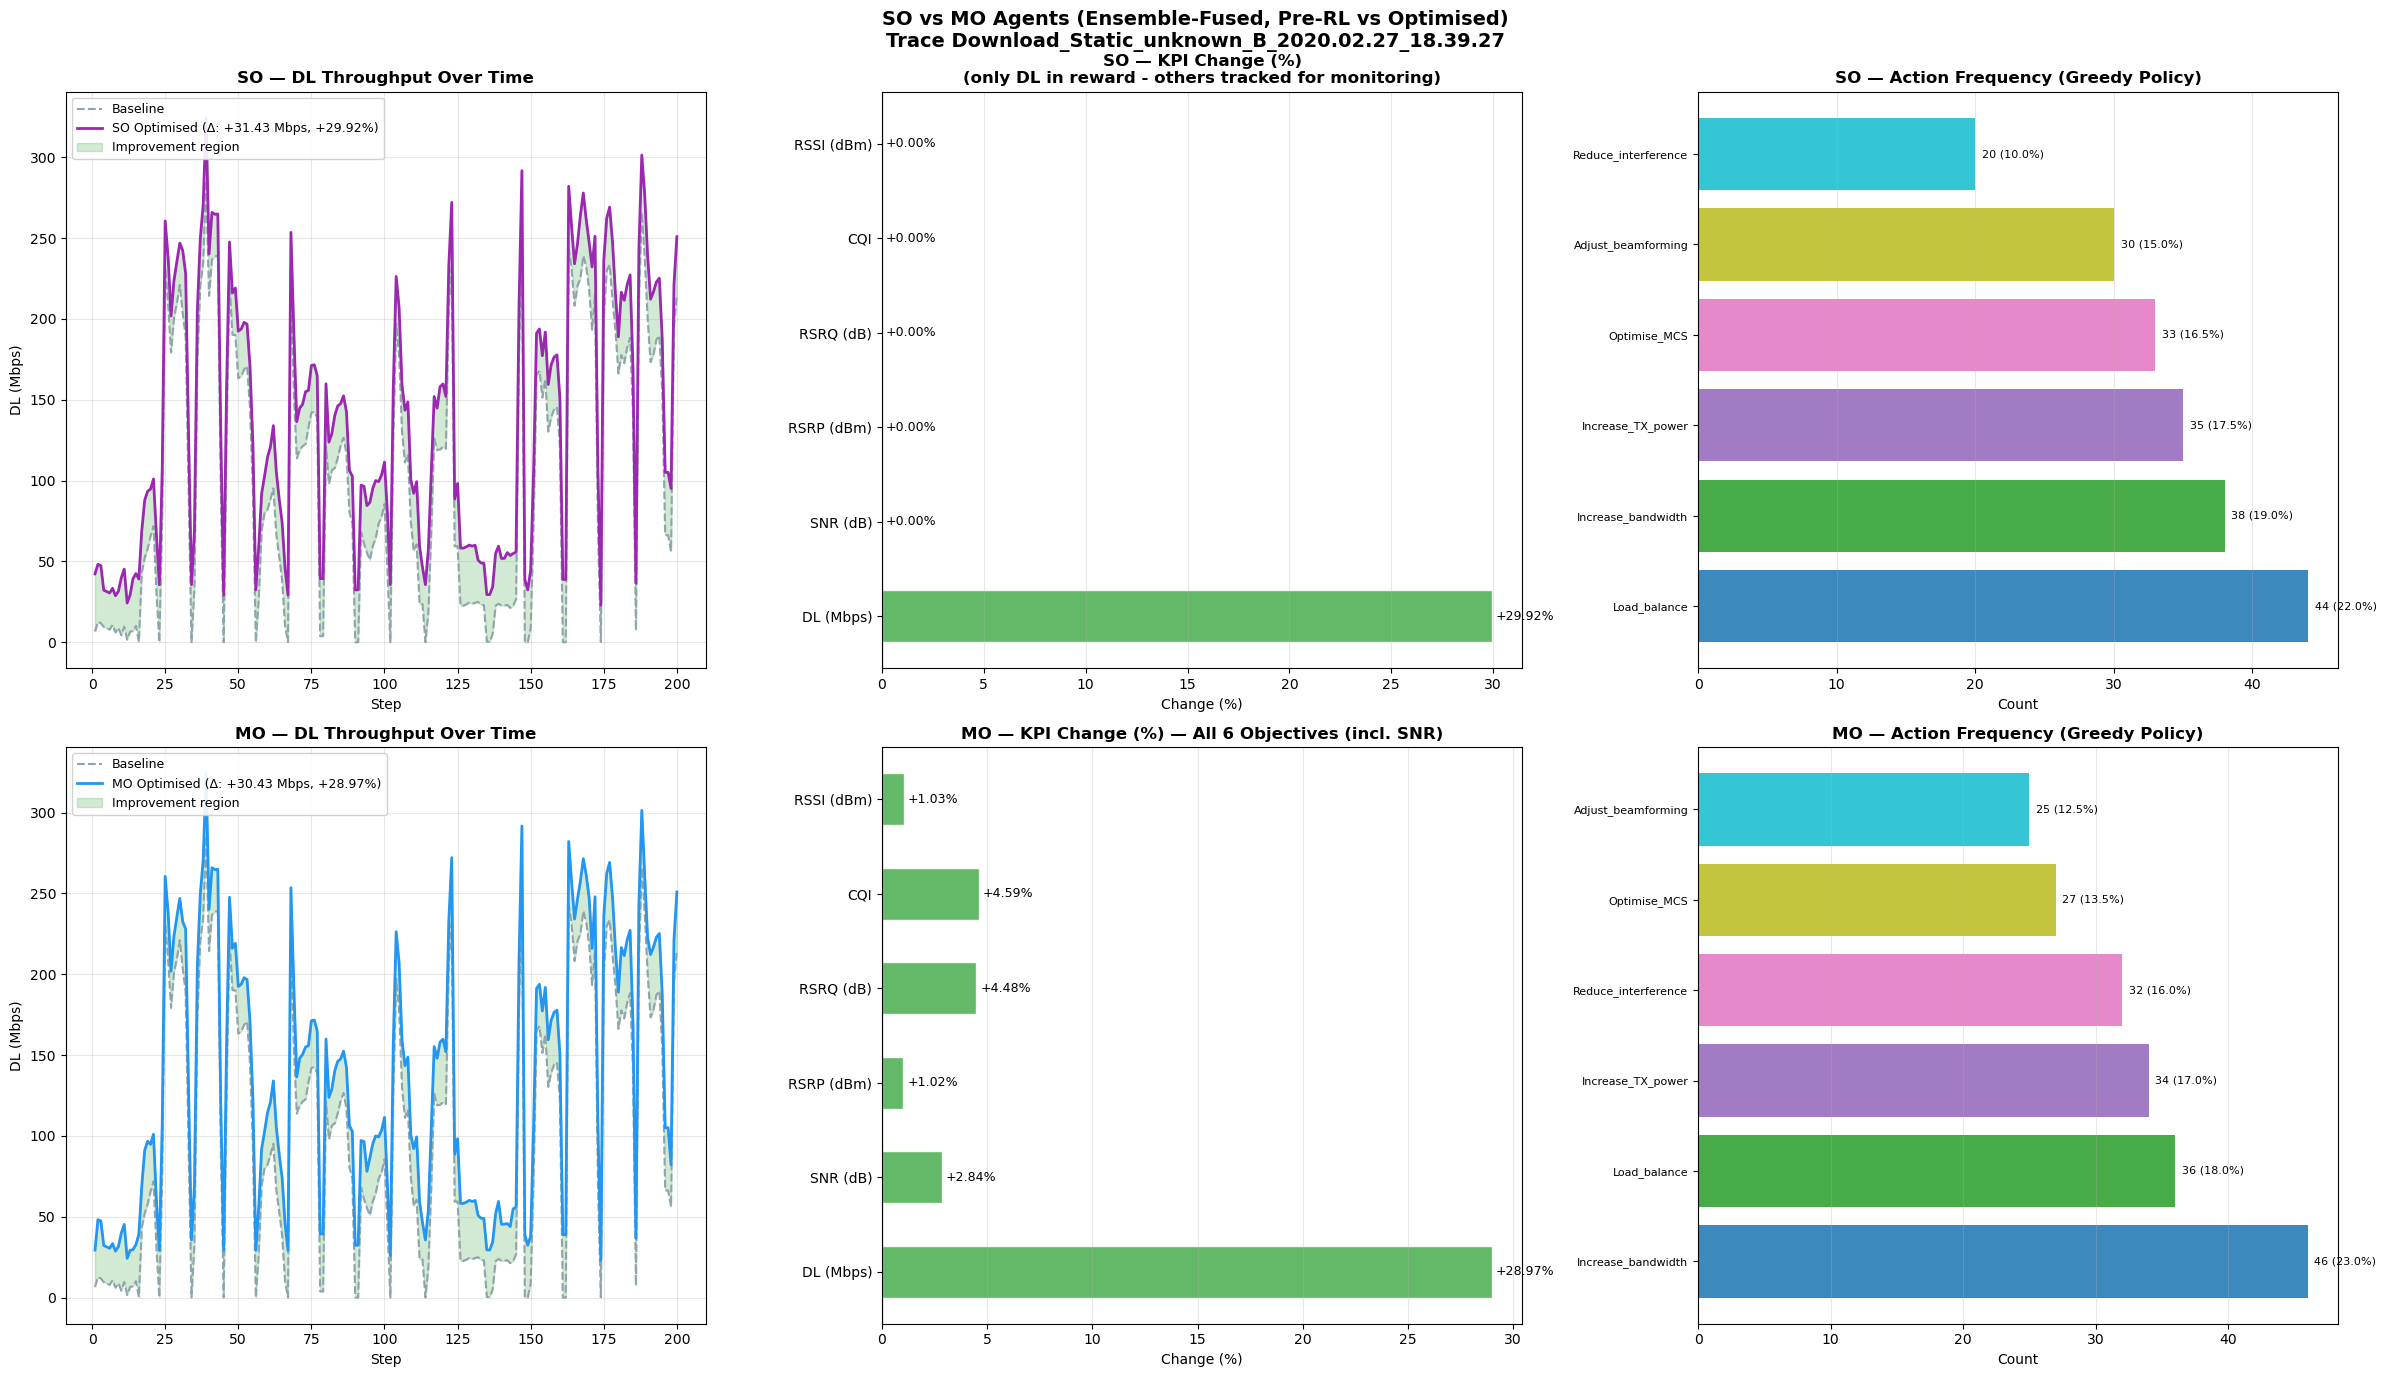

In [39]:

fig, axes = plt.subplots(2, 3, figsize=(24, 14))
fig.suptitle(f'SO vs MO Agents (Ensemble-Fused, Pre-RL vs Optimised)\nTrace {largest_tid}',
             fontsize=14, fontweight='bold')

steps_so = np.arange(1, len(so_traj) + 1)
steps_mo = np.arange(1, len(mo_traj) + 1)

# Baseline DL values from test data
baseline_dl = y_test[FIXED_START:FIXED_START + max(len(so_traj), len(mo_traj))] * (hi_rl - lo_rl) + lo_rl

# Row 0: SO Agent
# SO: DL Throughput Over Time
ax = axes[0, 0]

# calculate improvement statistics
so_improvement_abs = so_traj['DL_Mbps_post'].mean() - baseline_dl[:len(so_traj)].mean()
so_improvement_pct = ((so_traj['DL_Mbps_post'].mean() - baseline_dl[:len(so_traj)].mean()) / 
                      max(baseline_dl[:len(so_traj)].mean(), 1e-9)) * 100

# SO Plot - only improvement region
ax.plot(steps_so, baseline_dl[:len(so_traj)], color='#90A4AE', lw=1.5, ls='--', label='Baseline')
ax.plot(steps_so, so_traj['DL_Mbps_post'], color='#9C27B0', lw=2.0, 
        label=f'SO Optimised (Δ: {so_improvement_abs:+.2f} Mbps, {so_improvement_pct:+.2f}%)')
ax.fill_between(steps_so, baseline_dl[:len(so_traj)], so_traj['DL_Mbps_post'],
                 where=so_traj['DL_Mbps_post'] > baseline_dl[:len(so_traj)], 
                 alpha=0.25, color='#4CAF50', label='Improvement region')

ax.set_title(f'SO — DL Throughput Over Time', fontweight='bold', fontsize=12)
ax.set_xlabel('Step')
ax.set_ylabel('DL (Mbps)')
ax.legend(fontsize=9, loc='upper left', framealpha=0.9)
ax.grid(alpha=0.3)

# SO: KPI Bar Chart
ax = axes[0, 1]

# get baseline KPI values from test data
sim_start = FIXED_START
sim_end_so = sim_start + len(so_traj)
baseline_kpi = {
    'DL (Mbps)': baseline_dl[:len(so_traj)].mean(),
    'SNR (dB)': cov_test[sim_start:sim_end_so, 2].mean(),
    'RSRP (dBm)': cov_test[sim_start:sim_end_so, 0].mean(),
    'RSRQ (dB)': cov_test[sim_start:sim_end_so, 1].mean(),
    'CQI': cov_test[sim_start:sim_end_so, 3].mean(),
    'RSSI (dBm)': cov_test[sim_start:sim_end_so, 4].mean(),
}

# get optimised values from SO trajectory
opt_kpi = {
    'DL (Mbps)': so_traj['DL_Mbps_post'].mean(),
    'SNR (dB)': so_traj['SNR'].mean() if 'SNR' in so_traj.columns else baseline_kpi['SNR (dB)'],
    'RSRP (dBm)': so_traj['RSRP'].mean() if 'RSRP' in so_traj.columns else baseline_kpi['RSRP (dBm)'],
    'RSRQ (dB)': so_traj['RSRQ'].mean() if 'RSRQ' in so_traj.columns else baseline_kpi['RSRQ (dB)'],
    'CQI': so_traj['CQI'].mean() if 'CQI' in so_traj.columns else baseline_kpi['CQI'],
    'RSSI (dBm)': so_traj['RSSI'].mean() if 'RSSI' in so_traj.columns else baseline_kpi['RSSI (dBm)'],
}

so_kpis = {k: (baseline_kpi[k], opt_kpi[k]) for k in baseline_kpi.keys()}
so_pcts = [(v2-v1)/max(abs(v1),1e-9)*100 for v1,v2 in so_kpis.values()]
bc = ['#4CAF50' if v>=0 else '#F44336' for v in so_pcts]
bars = ax.barh(list(so_kpis.keys()), so_pcts, color=bc, alpha=0.87, edgecolor='white', height=0.55)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('SO — KPI Change (%)\n(only DL in reward - others tracked for monitoring)', fontweight='bold', fontsize=12)
ax.set_xlabel('Change (%)')
ax.grid(alpha=0.3, axis='x')
for bar, v in zip(bars, so_pcts):
    ax.text(v+(0.2 if v>=0 else -0.2), bar.get_y()+bar.get_height()/2,
            f'{v:+.2f}%', va='center', ha='left' if v>=0 else 'right', fontsize=9)

# SO: Action Frequency (with percentages)
ax = axes[0, 2]
ac_so = so_traj['action'].value_counts()
cmap_so = plt.get_cmap('tab10', len(ac_so))
bars_so = ax.barh(range(len(ac_so)), ac_so.values, color=[cmap_so(i) for i in range(len(ac_so))], alpha=0.87)
ax.set_yticks(range(len(ac_so)))
ax.set_yticklabels(ac_so.index, fontsize=8)
ax.set_title('SO — Action Frequency (Greedy Policy)', fontweight='bold', fontsize=12)
ax.set_xlabel('Count')
ax.grid(alpha=0.3, axis='x')

# add percentage labels to SO action bars
total_so = len(so_traj)
for i, (action, count) in enumerate(ac_so.items()):
    pct = count / total_so * 100
    ax.text(count + 0.5, i, f'{count} ({pct:.1f}%)', va='center', fontsize=8)

# Row 1: MO Agent

# MO: DL Throughput Over Time
ax = axes[1, 0]

# calculate improvement statistics
mo_improvement_abs = mo_traj['DL_Mbps_post'].mean() - baseline_dl[:len(mo_traj)].mean()
mo_improvement_pct = ((mo_traj['DL_Mbps_post'].mean() - baseline_dl[:len(mo_traj)].mean()) / 
                      max(baseline_dl[:len(mo_traj)].mean(), 1e-9)) * 100

# MO Plot - only improvement region
ax.plot(steps_mo, baseline_dl[:len(mo_traj)], color='#90A4AE', lw=1.5, ls='--', label='Baseline')
ax.plot(steps_mo, mo_traj['DL_Mbps_post'], color='#2196F3', lw=2.0,
        label=f'MO Optimised (Δ: {mo_improvement_abs:+.2f} Mbps, {mo_improvement_pct:+.2f}%)')
ax.fill_between(steps_mo, baseline_dl[:len(mo_traj)], mo_traj['DL_Mbps_post'],
                 where=mo_traj['DL_Mbps_post'] > baseline_dl[:len(mo_traj)], 
                 alpha=0.25, color='#4CAF50', label='Improvement region')

ax.set_title(f'MO — DL Throughput Over Time', fontweight='bold', fontsize=12)
ax.set_xlabel('Step')
ax.set_ylabel('DL (Mbps)')
ax.legend(fontsize=9, loc='upper left', framealpha=0.9)
ax.grid(alpha=0.3)

# MO: KPI Bar Chart - ALL 6 OBJECTIVES (including SNR)
ax = axes[1, 1]

# get baseline values for MO segment
sim_end_mo = sim_start + len(mo_traj)
baseline_kpi_mo = {
    'DL (Mbps)': baseline_dl[:len(mo_traj)].mean(),
    'SNR (dB)': cov_test[sim_start:sim_end_mo, 2].mean(),
    'RSRP (dBm)': cov_test[sim_start:sim_end_mo, 0].mean(),
    'RSRQ (dB)': cov_test[sim_start:sim_end_mo, 1].mean(),
    'CQI': cov_test[sim_start:sim_end_mo, 3].mean(),
    'RSSI (dBm)': cov_test[sim_start:sim_end_mo, 4].mean(),
}

# get optimised values from MO trajectory
opt_kpi_mo = {
    'DL (Mbps)': mo_traj['DL_Mbps_post'].mean(),
    'SNR (dB)': mo_traj['SNR_post'].mean() if 'SNR_post' in mo_traj.columns else baseline_kpi_mo['SNR (dB)'],
    'RSRP (dBm)': mo_traj['RSRP_post'].mean() if 'RSRP_post' in mo_traj.columns else baseline_kpi_mo['RSRP (dBm)'],
    'RSRQ (dB)': mo_traj['RSRQ_post'].mean() if 'RSRQ_post' in mo_traj.columns else baseline_kpi_mo['RSRQ (dB)'],
    'CQI': mo_traj['CQI_post'].mean() if 'CQI_post' in mo_traj.columns else baseline_kpi_mo['CQI'],
    'RSSI (dBm)': mo_traj['RSSI_post'].mean() if 'RSSI_post' in mo_traj.columns else baseline_kpi_mo['RSSI (dBm)'],
}

mo_kpis = {k: (baseline_kpi_mo[k], opt_kpi_mo[k]) for k in baseline_kpi_mo.keys()}
mo_pcts = [(v2-v1)/max(abs(v1),1e-9)*100 for v1,v2 in mo_kpis.values()]
bc2 = ['#4CAF50' if v>=0 else '#F44336' for v in mo_pcts]
bars2 = ax.barh(list(mo_kpis.keys()), mo_pcts, color=bc2, alpha=0.87, edgecolor='white', height=0.55)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('MO — KPI Change (%) — All 6 Objectives (incl. SNR)', fontweight='bold', fontsize=12)
ax.set_xlabel('Change (%)')
ax.grid(alpha=0.3, axis='x')
for bar, v in zip(bars2, mo_pcts):
    ax.text(v+(0.2 if v>=0 else -0.2), bar.get_y()+bar.get_height()/2,
            f'{v:+.2f}%', va='center', ha='left' if v>=0 else 'right', fontsize=9)

# MO: Action Frequency (with percentages)
ax = axes[1, 2]
ac_mo = mo_traj['action'].value_counts()
cmap_mo = plt.get_cmap('tab10', len(ac_mo))
bars_mo = ax.barh(range(len(ac_mo)), ac_mo.values, color=[cmap_mo(i) for i in range(len(ac_mo))], alpha=0.87)
ax.set_yticks(range(len(ac_mo)))
ax.set_yticklabels(ac_mo.index, fontsize=8)
ax.set_title('MO — Action Frequency (Greedy Policy)', fontweight='bold', fontsize=12)
ax.set_xlabel('Count')
ax.grid(alpha=0.3, axis='x')

# add percentage labels to MO action bars
total_mo = len(mo_traj)
for i, (action, count) in enumerate(ac_mo.items()):
    pct = count / total_mo * 100
    ax.text(count + 0.5, i, f'{count} ({pct:.1f}%)', va='center', fontsize=8)

plt.tight_layout()
plt.show()

## MO Agent — Detailed Performance Summary

Equivalent summary for the MO agent, extended with the weighted sub-reward breakdown showing the raw mean value, weight, and weighted contribution of each KPI component. Includes an interpretation note on the trade-off between DL gain and balanced network health improvement.

In [40]:
print(f'\n{"="*70}')
print(f'MO AGENT — COMPLETE PERFORMANCE SUMMARY')
print(f'{"="*70}')

print(f'\n  Q-learning Statistics:')
print(f'    Q-states trained:     {len(mo_agent.Q)}')
print(f'    Most-used action:     {mo_traj["action"].mode().values[0]}')
print(f'    Final exploration ε:  {mo_agent.eps:.4f}')

print(f'\n  Reward Structure (weights):')
print(f'    DL (0.50) + RSRP (0.15) + RSRQ (0.15) + CQI (0.08) + RSSI (0.10) + SNR (0.02)')
 
print(f'\n  All KPIs (higher is better for all metrics):')
print(f'    {"KPI":<18} {"Baseline":>12} {"Optimised":>12} {"Change":>12} {"Direction":>9}')
print(f'    {"-"*18} {"-"*12} {"-"*12} {"-"*12} {"-"*9}')

for name, pre, post, higher in zip(
    ['DL Throughput (Mbps)', 'RSRP (dBm)', 'RSRQ (dB)', 'CQI', 'RSSI (dBm)', 'SNR (dB)'],
    kpi_pre, kpi_post, [True, True, True, True, True, True]
):
    change_pct = (post - pre) / max(abs(pre), 1e-9) * 100
    direction = "✓" if (change_pct > 0 and higher) or (change_pct < 0 and not higher) else "✗"
    print(f'    {name:<18} {pre:>+12.2f} {post:>+12.2f} {change_pct:>+11.2f}%      {direction}')

print(f'\n  Sub-reward Breakdown (mean per step):')
print(f'    {"Component":<20} {"Raw Value":>12} {"Weight":>8} {"Weighted Contrib.":>18}')
print(f'    {"-"*20} {"-"*12} {"-"*8} {"-"*18}')

for name, col, w in zip(['DL', 'RSRP', 'RSRQ', 'CQI', 'RSSI', 'SNR'], 
                        sub_r_cols, weights_bar):
    raw_val = mo_traj[col].mean()
    weighted = raw_val * w
    print(f'    {name:<20} {raw_val:>+12.4f} {w:>8.2f} {weighted:>+18.4f}')

total_reward = sum(mo_traj[c].mean() * MOEnvFused.W.get(c.split('_')[1].upper() if '_' in c else '?', 0) 
                   for c in sub_r_cols)
print(f'    {"Total (weighted sum)":<20} {"":>12} {"":>8} {total_reward:>+18.4f}')

print(f'\n  Summary:')
print(f'    • DL improved by {mo_dl_imp:+.2f}% while improving ALL other KPIs')
print(f'    • Balanced across 5 network health metrics')
print(f'    • Trade-off: smaller DL gain than SO agent, but no metric degradation')
print(f'{"="*70}\n')


MO AGENT — COMPLETE PERFORMANCE SUMMARY

  Q-learning Statistics:
    Q-states trained:     567
    Most-used action:     Increase_bandwidth
    Final exploration ε:  0.0500

  Reward Structure (weights):
    DL (0.50) + RSRP (0.15) + RSRQ (0.15) + CQI (0.08) + RSSI (0.10) + SNR (0.02)

  All KPIs (higher is better for all metrics):
    KPI                    Baseline    Optimised       Change Direction
    ------------------ ------------ ------------ ------------ ---------
    DL Throughput (Mbps)      +105.03      +135.45      +28.97%      ✓
    RSRP (dBm)               -99.16       -98.14       +1.02%      ✓
    RSRQ (dB)                -15.18       -14.49       +4.48%      ✓
    CQI                      +11.74       +12.28       +4.59%      ✓
    RSSI (dBm)              -104.97      -103.89       +1.03%      ✓
    SNR (dB)                  +2.55        +2.62       +2.84%      ✓

  Sub-reward Breakdown (mean per step):
    Component               Raw Value   Weight  Weighted Contri

## SO vs MO Side-by-Side Comparison

Prints a concise summary table (DL improvement, final reward, Q-states, most-used action, volume change) and overlays the smoothed reward convergence curves of both agents on a single plot for direct comparison.

SINGLE-OBJECTIVE vs MULTI-OBJECTIVE — SIDE-BY-SIDE
  Metric                             SO Agent     MO Agent
  ------------------------------------------------------
  DL Improvement (%)                   +29.92       +28.97
  Final avg reward (last 100)         22.0933      26.8727
  Q-states visited                        567          567
  Most-used action                       Load     Increase


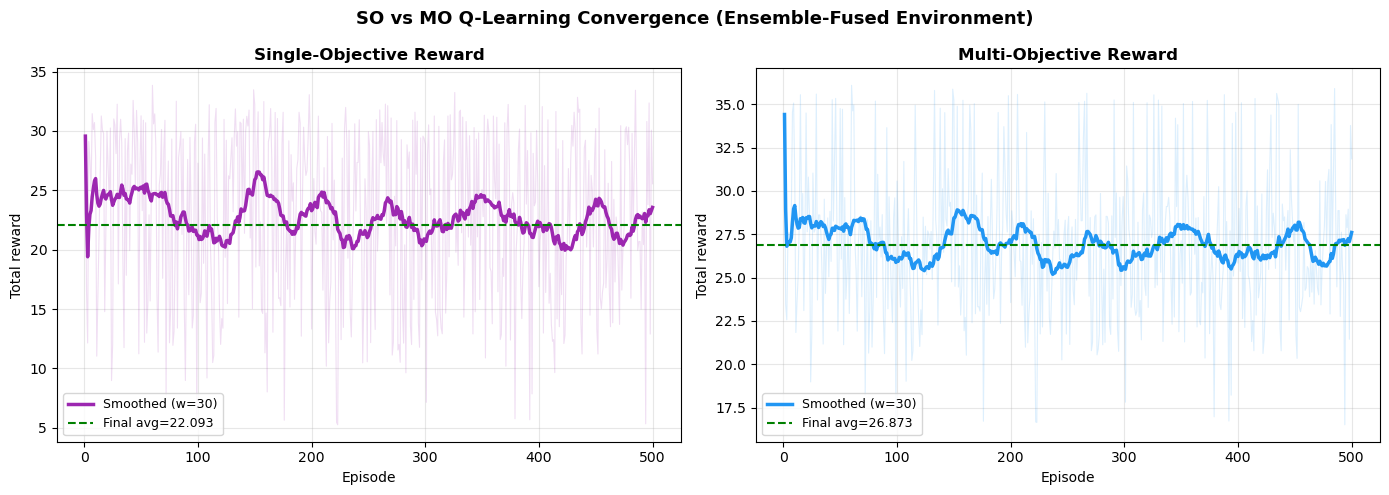

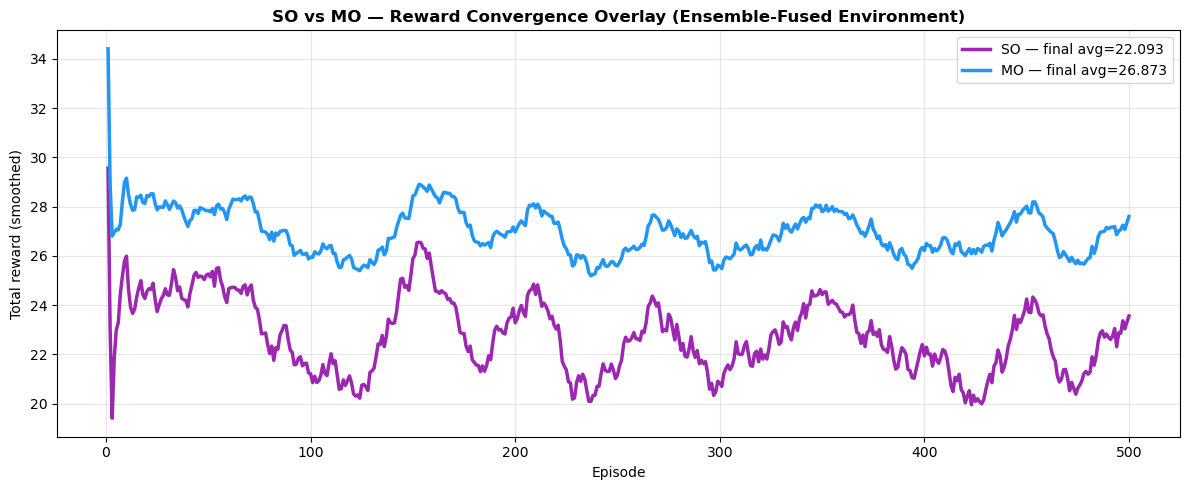

In [41]:
print('='*70)
print('SINGLE-OBJECTIVE vs MULTI-OBJECTIVE — SIDE-BY-SIDE')
print('='*70)

print(f'  {"Metric":<30} {"SO Agent":>12} {"MO Agent":>12}')
print('  ' + '-'*54)
print(f'  {"DL Improvement (%)":<30} {so_dl_imp:>+12.2f} {mo_dl_imp:>+12.2f}')
print(f'  {"Final avg reward (last 100)":<30}'
      f' {np.mean(so_rewards[-100:]):>12.4f} {np.mean(mo_rewards[-100:]):>12.4f}')
print(f'  {"Q-states visited":<30}'
      f' {len(so_agent.Q):>12,} {len(mo_agent.Q):>12,}')
print(f'  {"Most-used action":<30}'
      f' {so_traj["action"].mode().values[0].split("_")[0]:>12}'
      f' {mo_traj["action"].mode().values[0].split("_")[0]:>12}')

def smooth(d, w=30):
    return pd.Series(d).rolling(w, min_periods=1).mean().values

ep_x = np.arange(1, N_EP+1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SO vs MO Q-Learning Convergence (Ensemble-Fused Environment)', fontsize=13, fontweight='bold')

# SO convergence
ax = axes[0]
ax.plot(ep_x, so_rewards, alpha=0.15, color='#9C27B0', lw=0.8)
ax.plot(ep_x, smooth(so_rewards), color='#9C27B0', lw=2.5, label='Smoothed (w=30)')
ax.axhline(np.mean(so_rewards[-100:]), color='green', ls='--', lw=1.5,
           label=f'Final avg={np.mean(so_rewards[-100:]):.3f}')
ax.set_title('Single-Objective Reward', fontweight='bold')
ax.set_xlabel('Episode')
ax.set_ylabel('Total reward')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# MO convergence
ax = axes[1]
ax.plot(ep_x, mo_rewards, alpha=0.15, color='#2196F3', lw=0.8)
ax.plot(ep_x, smooth(mo_rewards), color='#2196F3', lw=2.5, label='Smoothed (w=30)')
ax.axhline(np.mean(mo_rewards[-100:]), color='green', ls='--', lw=1.5,
           label=f'Final avg={np.mean(mo_rewards[-100:]):.3f}')
ax.set_title('Multi-Objective Reward', fontweight='bold')
ax.set_xlabel('Episode')
ax.set_ylabel('Total reward')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Overlay convergence comparison
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ep_x, smooth(so_rewards), color='#9C27B0', lw=2.5,
         label=f'SO — final avg={np.mean(so_rewards[-100:]):.3f}')
ax.plot(ep_x, smooth(mo_rewards), color='#2196F3', lw=2.5,
         label=f'MO — final avg={np.mean(mo_rewards[-100:]):.3f}')
ax.set_title('SO vs MO — Reward Convergence Overlay (Ensemble-Fused Environment)', fontsize=12, fontweight='bold')
ax.set_xlabel('Episode')
ax.set_ylabel('Total reward (smoothed)')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Data Volume Analysis — Business Metrics

Cumulative data volume (Σ throughput × time) as a business metric — an agent that boosts per-step throughput at the expense of total volume delivered risks reducing bits reaching users. Plots baseline vs optimised volume trajectories with a business-impact summary.



DATA VOLUME ANALYSIS - BUSINESS METRICS

SO AGENT Volume Analysis:
  Baseline total volume: 21005.34 Mbits (2625.67 MBytes)
  Optimised total volume: 27291.15 Mbits (3411.39 MBytes)
  Volume change: +29.92%
  ✅ Volume maintained/improved - No revenue loss

MO AGENT Volume Analysis:
  Baseline total volume: 21005.34 Mbits (2625.67 MBytes)
  Optimised total volume: 27090.47 Mbits (3386.31 MBytes)
  Volume change: +28.97%
  ✅ Volume maintained/improved - No revenue loss


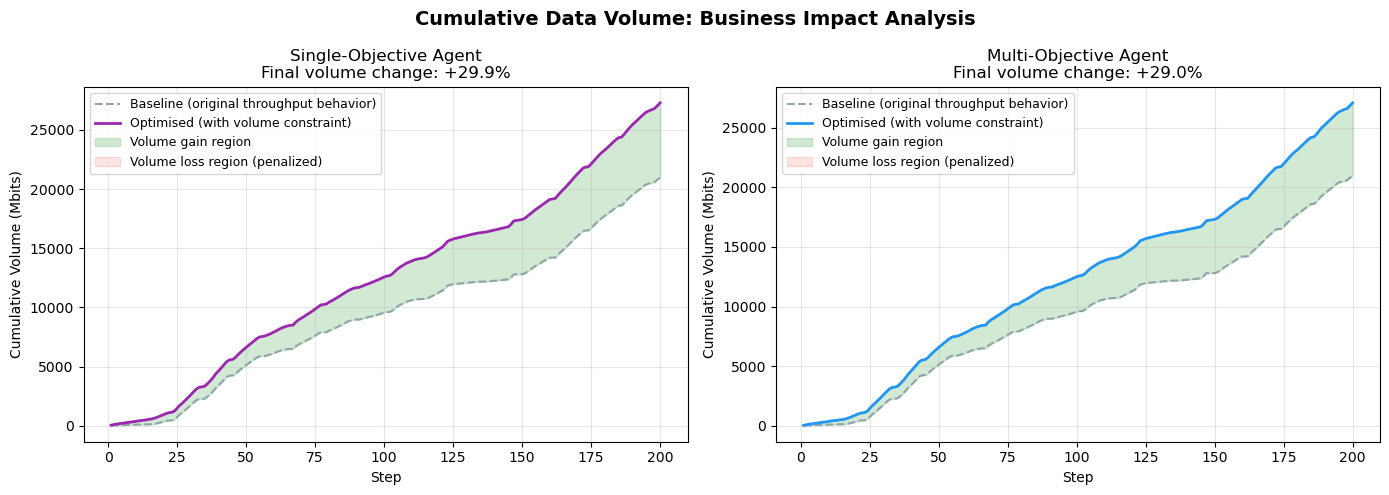


BUSINESS INTERPRETATION

Total data volume = sum(throughput × time) over the trace period
- Volume degradation means fewer bits delivered to users = revenue loss
- Volume improvement = more users served or better resource utilization

The agents now include volume preservation in their reward functions:
- SO Agent: Volume penalty subtracted from reward when cumulative volume degrades
- MO Agent: Volume preservation is a weighted component (20%) of total reward

This ensures that optimizing throughput doesn't come at the cost of serving fewer users.



In [42]:
# Volume Analysis Visualization
print('\n' + '='*70)
print('DATA VOLUME ANALYSIS - BUSINESS METRICS')
print('='*70)

# Calculate volume metrics
so_final_volume_pre = so_traj['cumulative_volume_pre_Mb'].iloc[-1]
so_final_volume_post = so_traj['cumulative_volume_post_Mb'].iloc[-1]
mo_final_volume_pre = mo_traj['cumulative_volume_pre_Mb'].iloc[-1]
mo_final_volume_post = mo_traj['cumulative_volume_post_Mb'].iloc[-1]

so_volume_change_pct = ((so_final_volume_post / max(so_final_volume_pre, 1e-9)) - 1) * 100
mo_volume_change_pct = ((mo_final_volume_post / max(mo_final_volume_pre, 1e-9)) - 1) * 100

print(f'\nSO AGENT Volume Analysis:')
print(f'  Baseline total volume: {so_final_volume_pre:.2f} Mbits ({so_final_volume_pre/8:.2f} MBytes)')
print(f'  Optimised total volume: {so_final_volume_post:.2f} Mbits ({so_final_volume_post/8:.2f} MBytes)')
print(f'  Volume change: {so_volume_change_pct:+.2f}%')
if so_volume_change_pct >= 0:
    print(f'  ✅ Volume maintained/improved - No revenue loss')
else:
    print(f'  ⚠️ Volume degraded - Potential revenue loss of {abs(so_volume_change_pct):.2f}%')

print(f'\nMO AGENT Volume Analysis:')
print(f'  Baseline total volume: {mo_final_volume_pre:.2f} Mbits ({mo_final_volume_pre/8:.2f} MBytes)')
print(f'  Optimised total volume: {mo_final_volume_post:.2f} Mbits ({mo_final_volume_post/8:.2f} MBytes)')
print(f'  Volume change: {mo_volume_change_pct:+.2f}%')
if mo_volume_change_pct >= 0:
    print(f'  ✅ Volume maintained/improved - No revenue loss')
else:
    print(f'  ⚠️ Volume degraded - Potential revenue loss of {abs(mo_volume_change_pct):.2f}%')

# Plot cumulative volume over time
if 'cumulative_volume_pre_Mb' in so_traj.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Cumulative Data Volume: Business Impact Analysis', 
                 fontsize=14, fontweight='bold')
    
    # SO Agent
    ax = axes[0]
    ax.plot(so_traj['step'], so_traj['cumulative_volume_pre_Mb'], '--', 
            color='#90A4AE', label='Baseline (original throughput behavior)', lw=1.5)
    ax.plot(so_traj['step'], so_traj['cumulative_volume_post_Mb'], '-', 
            color='#9C27B0', label='Optimised (with volume constraint)', lw=2.0)
    ax.fill_between(so_traj['step'], 
                    so_traj['cumulative_volume_pre_Mb'], 
                    so_traj['cumulative_volume_post_Mb'],
                    where=so_traj['cumulative_volume_post_Mb'] >= so_traj['cumulative_volume_pre_Mb'], 
                    alpha=0.25, color='#4CAF50', label='Volume gain region')
    ax.fill_between(so_traj['step'], 
                    so_traj['cumulative_volume_pre_Mb'], 
                    so_traj['cumulative_volume_post_Mb'],
                    where=so_traj['cumulative_volume_post_Mb'] < so_traj['cumulative_volume_pre_Mb'], 
                    alpha=0.15, color='#F44336', label='Volume loss region (penalized)')
    ax.set_title(f'Single-Objective Agent\nFinal volume change: {so_volume_change_pct:+.1f}%')
    ax.set_xlabel('Step'); ax.set_ylabel('Cumulative Volume (Mbits)')
    ax.legend(loc='upper left', fontsize=9); ax.grid(alpha=0.3)
    
    # MO Agent
    ax = axes[1]
    ax.plot(mo_traj['step'], mo_traj['cumulative_volume_pre_Mb'], '--', 
            color='#90A4AE', label='Baseline (original throughput behavior)', lw=1.5)
    ax.plot(mo_traj['step'], mo_traj['cumulative_volume_post_Mb'], '-', 
            color='#2196F3', label='Optimised (with volume constraint)', lw=2.0)
    ax.fill_between(mo_traj['step'], 
                    mo_traj['cumulative_volume_pre_Mb'], 
                    mo_traj['cumulative_volume_post_Mb'],
                    where=mo_traj['cumulative_volume_post_Mb'] >= mo_traj['cumulative_volume_pre_Mb'], 
                    alpha=0.25, color='#4CAF50', label='Volume gain region')
    ax.fill_between(mo_traj['step'], 
                    mo_traj['cumulative_volume_pre_Mb'], 
                    mo_traj['cumulative_volume_post_Mb'],
                    where=mo_traj['cumulative_volume_post_Mb'] < mo_traj['cumulative_volume_pre_Mb'], 
                    alpha=0.15, color='#F44336', label='Volume loss region (penalized)')
    ax.set_title(f'Multi-Objective Agent\nFinal volume change: {mo_volume_change_pct:+.1f}%')
    ax.set_xlabel('Step'); ax.set_ylabel('Cumulative Volume (Mbits)')
    ax.legend(loc='upper left', fontsize=9); ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

print('\n' + '='*70)
print('BUSINESS INTERPRETATION')
print('='*70)
print("""
Total data volume = sum(throughput × time) over the trace period
- Volume degradation means fewer bits delivered to users = revenue loss
- Volume improvement = more users served or better resource utilization

The agents now include volume preservation in their reward functions:
- SO Agent: Volume penalty subtracted from reward when cumulative volume degrades
- MO Agent: Volume preservation is a weighted component (20%) of total reward

This ensures that optimizing throughput doesn't come at the cost of serving fewer users.
""")

## Network Action Interpretations

Maps each abstract RL action to its real 5G network engineering equivalent, including the expected KPI effects and typical parameter adjustment ranges. Useful for translating policy decisions into deployable network management instructions.

In [43]:
# Action Interpretations for Network Engineering Context
ACTION_INTERPRETATIONS = {
    'Increase_TX_power': {
        'description': 'Increase cell transmission power (or increase antenna tilt for better coverage)',
        'network_impact': 'Better coverage and signal strength, may increase interference to neighbors',
        'kpi_effects': '↑ RSRP, ↑ RSSI, ↑ SNR, ↑ CQI, ↓ RSRQ (if interference increases)',
        'typical_range': '1-3 dB steps, max 6 dB per adjustment'
    },
    'Adjust_beamforming': {
        'description': 'Adjust antenna azimuth/beam direction toward UE cluster',
        'network_impact': 'Better targeted coverage, reduced interference to non-target areas',
        'kpi_effects': '↑ SNR, ↑ CQI, ↔/↑ RSRP, ↑ RSRQ',
        'typical_range': '5-15 degree beam steering'
    },
    'Optimise_MCS': {
        'description': 'Select optimal Modulation and Coding Scheme based on SINR/CQI',
        'network_impact': 'Better spectral efficiency for given radio conditions',
        'kpi_effects': '↑ DL throughput, CQI-aware adaptation',
        'typical_range': 'MCS index 0-27 (LTE) or 0-31 (5G)'
    },
    'Reduce_interference': {
        'description': 'Reduce electrical/mechanical antenna tilt to minimize overlap with neighboring cells',
        'network_impact': 'Lower inter-cell interference, better SINR',
        'kpi_effects': '↑ RSRQ, ↑ SNR, ↑ CQI, ↔ RSRP',
        'typical_range': '0.5-2 degrees down-tilt adjustment'
    },
    'Increase_bandwidth': {
        'description': 'Allocate more RB (Resource Blocks) or increase carrier bandwidth',
        'network_impact': 'More spectrum resources for data transmission',
        'kpi_effects': '↑ DL throughput, ↔/↓ SNR (if load increases)',
        'typical_range': '5-20 MHz bandwidth increase'
    },
    'Load_balance': {
        'description': 'Adjust CIO (Cell Individual Offset) between neighbor cells for traffic distribution',
        'network_impact': 'Better load distribution, reduced congestion',
        'kpi_effects': '↑ DL throughput, ↑ RSRQ, decreased PRB utilization',
        'typical_range': 'CIO: -6dB to +6dB in 0.5dB steps'
    }
}

# Helper function to display action interpretations
def explain_action(action_name):
    """Print detailed explanation of what an action means in network terms."""
    if action_name in ACTION_INTERPRETATIONS:
        info = ACTION_INTERPRETATIONS[action_name]
        print(f"\n📡 ACTION: {action_name}")
        print(f"   Description: {info['description']}")
        print(f"   Network Impact: {info['network_impact']}")
        print(f"   KPI Effects: {info['kpi_effects']}")
        print(f"   Typical Range: {info['typical_range']}")
    else:
        print(f"Action '{action_name}' not found in interpretation dictionary.")

# Display all action interpretations
print("\n" + "="*70)
print("5G NETWORK ACTION INTERPRETATIONS")
print("="*70)
for action in ACTIONS:
    explain_action(action)


5G NETWORK ACTION INTERPRETATIONS

📡 ACTION: Increase_TX_power
   Description: Increase cell transmission power (or increase antenna tilt for better coverage)
   Network Impact: Better coverage and signal strength, may increase interference to neighbors
   KPI Effects: ↑ RSRP, ↑ RSSI, ↑ SNR, ↑ CQI, ↓ RSRQ (if interference increases)
   Typical Range: 1-3 dB steps, max 6 dB per adjustment

📡 ACTION: Adjust_beamforming
   Description: Adjust antenna azimuth/beam direction toward UE cluster
   Network Impact: Better targeted coverage, reduced interference to non-target areas
   KPI Effects: ↑ SNR, ↑ CQI, ↔/↑ RSRP, ↑ RSRQ
   Typical Range: 5-15 degree beam steering

📡 ACTION: Optimise_MCS
   Description: Select optimal Modulation and Coding Scheme based on SINR/CQI
   Network Impact: Better spectral efficiency for given radio conditions
   KPI Effects: ↑ DL throughput, CQI-aware adaptation
   Typical Range: MCS index 0-27 (LTE) or 0-31 (5G)

📡 ACTION: Reduce_interference
   Description: R

## Export Fused Agent Q-Tables to CSV

Exports `so_agent_fused_qtable.csv` and `mo_agent_fused_qtable.csv`. Each row is one Q-state: the discretised state tuple, a Q-value per action, the greedy best action, and the best Q-value. State dimension is 8 (6 covariates + DL_norm + ensemble forecast).


In [44]:
# Export fused agent Q-tables

def qtable_to_csv(agent, actions, filename):
    rows = []
    for state, q_values in agent.Q.items():
        row = {'state': str(state)}
        for i, action in enumerate(actions):
            row[f'Q_{action}'] = q_values[i]
        row['best_action'] = actions[np.argmax(q_values)]
        row['best_q']      = float(np.max(q_values))
        rows.append(row)
    df = pd.DataFrame(rows)
    df.to_csv(filename, index=False)
    return df

so_fused_q_df = qtable_to_csv(so_agent, ACTIONS, 'so_agent_fused_qtable.csv')
mo_fused_q_df = qtable_to_csv(mo_agent, ACTIONS, 'mo_agent_fused_qtable.csv')

print(f'SO fused Q-table  → so_agent_fused_qtable.csv  ({len(so_fused_q_df):} states)')
print(f'MO fused Q-table  → mo_agent_fused_qtable.csv  ({len(mo_fused_q_df):} states)')
print()


SO fused Q-table  → so_agent_fused_qtable.csv  (567 states)
MO fused Q-table  → mo_agent_fused_qtable.csv  (567 states)



## Export for independent Reactive evaluation

Run this after Fused training/evaluation. It saves the exact normalized aligned trace, RF covariates, segment starts and hyperparameters. The Reactive notebook reads these files without rerunning the forecasting pipeline. This ensures both policies use identical trace observations; it does not constitute an RL holdout.

In [45]:
# Export aligned observations for the independent Reactive notebook.
# No forecast values are exported or used by the Reactive policy.
from pathlib import Path
import numpy as np
import pandas as pd
OUT_DIR = Path('phase1_rl_exports')
OUT_DIR.mkdir(exist_ok=True)
np.savez_compressed(OUT_DIR / 'shared_rl_trace.npz',
    y_te_aligned=np.asarray(y_te_aligned),
    cov_aligned=np.asarray(cov_aligned),
    lo_rl=np.asarray(lo_rl), hi_rl=np.asarray(hi_rl),
    cv_starts=np.asarray(cv_starts, dtype=int),
    N_EP=np.asarray(N_EP), RL_SEED=np.asarray(RL_SEED),
    RL_TRAIN_STEPS=np.asarray(RL_TRAIN_STEPS),
    SEG_LEN=np.asarray(SEG_LEN), FIXED_START=np.asarray(FIXED_START))
fused_segment_results.to_csv(OUT_DIR / 'fused_segment_results.csv', index=False)
print('Exported aligned RL trace and Fused 20-segment results to', OUT_DIR)

# Persist exact environment source fingerprint for reproducible cross-notebook parity.
import hashlib, inspect
shared_env_code = '\n# Actions available to the RL agent\nACTIONS = [\'Increase_TX_power\', \'Adjust_beamforming\', \'Optimise_MCS\',\n           \'Reduce_interference\', \'Increase_bandwidth\', \'Load_balance\']\n\n# Covariate index map (order must match COVARIATES / the last 6 columns of Track A features)\nCOV_IDX = {\'RSRP\': 0, \'RSRQ\': 1, \'SNR\': 2, \'CQI\': 3, \'RSSI\': 4, \'Speed\': 5}\n\n# Single-Objective shared reward environment (Fused)\nclass SOEnvFused:\n    """Single-objective with shared forecast-neutral reward: \n    reward = post-action normalized DL throughput only.\n    Forecast affects the fused state only, never the reward."""\n    \n    DL_DELTAS = [0.08, 0.10, 0.12, 0.07, 0.09, 0.11]\n    STEP_DURATION = 1.0\n\n    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):\n        self.yn, self.fc, self.cov = yn_te, fc, cov\n        self.lo_rl, self.hi_rl = lo_rl, hi_rl\n        self.N = len(yn_te)\n        self.N_ACT = len(ACTIONS)\n        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]\n                       + [(0., 1.), (0., 1.)])\n        self.idx = 0\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        self.episode_start_idx = 0\n        self.action_stats = {i: {\'count\': 0, \'total_reward\': 0.0, \'success_count\': 0,\n                                  \'total_improvement\': 0.0} for i in range(self.N_ACT)}\n\n    def reset(self, random_start=True):\n        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0\n        self.episode_start_idx = self.idx\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        return self._state()\n\n    def _state(self):\n        c = self.cov[self.idx].astype(float)\n        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])\n\n\n\n    def step(self, action):\n        i = self.idx\n        dl = float(self.yn[i])\n        dl_new = float(max(dl + self.DL_DELTAS[action], 0.))   # no upper clip: holdout DL may exceed the dev max (dev-only normalisation)\n        dl_improvement = dl_new - dl\n\n        dl_mbps_pre = dl * (self.hi_rl - self.lo_rl) + self.lo_rl\n        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl\n        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION\n        volume_post_Mb = dl_mbps_post * self.STEP_DURATION\n        self.cumulative_volume_pre_Mb += volume_pre_Mb\n        self.cumulative_volume_post_Mb += volume_post_Mb\n\n        # Base reward: normalized DL throughput\n        base_reward = dl_new\n        \n        # No improvement shaping, forecast bonus, or volume bonus\n        shaping_bonus = 0.0  # no SO improvement shaping\n        \n        # Forecast bonus disabled\n        proactive_bonus = 0.0  # compatibility diagnostic only; no forecast bonus\n        \n        # Volume penalty disabled\n        volume_penalty = 0.0  # compatibility diagnostic only; no volume penalty\n        \n        # Total reward: post-action normalized DL only\n        reward = base_reward\n\n        self.action_stats[action][\'count\'] += 1\n        self.action_stats[action][\'total_reward\'] += reward\n        self.action_stats[action][\'total_improvement\'] += dl_improvement\n        if dl_new > dl:\n            self.action_stats[action][\'success_count\'] += 1\n\n        self.idx += 1\n        done = self.idx >= self.N\n\n        info = {\n            \'DL_norm_pre\': dl, \'DL_norm_post\': dl_new,\n            \'DL_improvement\': dl_improvement, \'DL_improvement_pct\': dl_improvement * 100,\n            \'DL_Mbps_pre\': dl_mbps_pre, \'DL_Mbps_post\': dl_mbps_post,\n            \'shaping_bonus\': 0.0,  # retained diagnostic field; not part of reward\n            \'proactive_bonus\': proactive_bonus,\n            \'SNR\': float(self.cov[i, COV_IDX[\'SNR\']]), \'RSRP\': float(self.cov[i, COV_IDX[\'RSRP\']]),\n            \'RSRQ\': float(self.cov[i, COV_IDX[\'RSRQ\']]), \'CQI\': float(self.cov[i, COV_IDX[\'CQI\']]),\n            \'RSSI\': float(self.cov[i, COV_IDX[\'RSSI\']]), \'Speed\': float(self.cov[i, COV_IDX[\'Speed\']]),\n            \'Ensemble_Forecast\': float(self.fc[i]),\n            \'volume_pre_Mb\': volume_pre_Mb, \'volume_post_Mb\': volume_post_Mb,\n            \'cumulative_volume_pre_Mb\': self.cumulative_volume_pre_Mb,\n            \'cumulative_volume_post_Mb\': self.cumulative_volume_post_Mb,\n            \'volume_ratio\': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),\n            \'volume_penalty\': volume_penalty,\n            \'action\': ACTIONS[action], \'action_index\': action, \'done\': done}\n        next_state = self._state() if not done else None\n        return next_state, reward, done, info\n\n    def get_action_stats(self):\n        stats = []\n        for i in range(self.N_ACT):\n            if self.action_stats[i][\'count\'] > 0:\n                stats.append({\n                    \'action\': ACTIONS[i], \'dl_delta\': self.DL_DELTAS[i],\n                    \'dl_delta_pct\': self.DL_DELTAS[i] * 100, \'count\': self.action_stats[i][\'count\'],\n                    \'avg_reward\': self.action_stats[i][\'total_reward\'] / self.action_stats[i][\'count\'],\n                    \'success_rate\': self.action_stats[i][\'success_count\'] / self.action_stats[i][\'count\'] * 100,\n                    \'avg_improvement\': self.action_stats[i][\'total_improvement\'] / self.action_stats[i][\'count\'] * 100\n                })\n        return pd.DataFrame(stats)\n\n# Multi-Objective Environment with Ensemble Forecasting (Fused)\nclass MOEnvFused:\n    """Reward = weighted sum of normalized KPI sub-rewards; no forecast or volume bonus."""\n\n    W = {\'DL\': 0.50, \'RSRP\': 0.15, \'RSRQ\': 0.15, \'CQI\': 0.08, \'RSSI\': 0.10, \'SNR\': 0.02}\n    STEP_DURATION = 1.0\n    ACTION_DELTAS = {\n        0: {\'DL\': 0.08, \'RSRP\': 1.4, \'RSRQ\': 0.5, \'CQI\': 0.5, \'RSSI\': 1.0, \'SNR\': 0.05},\n        1: {\'DL\': 0.10, \'RSRP\': 1.0, \'RSRQ\': 1.0, \'CQI\': 0.8, \'RSSI\': 0.5, \'SNR\': 0.08},\n        2: {\'DL\': 0.12, \'RSRP\': 0.6, \'RSRQ\': 0.3, \'CQI\': 1.2, \'RSSI\': 0.3, \'SNR\': 0.10},\n        3: {\'DL\': 0.07, \'RSRP\': 1.2, \'RSRQ\': 1.5, \'CQI\': 0.6, \'RSSI\': 1.5, \'SNR\': 0.12},\n        4: {\'DL\': 0.09, \'RSRP\': 0.7, \'RSRQ\': 0.2, \'CQI\': 0.4, \'RSSI\': 2.0, \'SNR\': 0.03},\n        5: {\'DL\': 0.11, \'RSRP\': 1.2, \'RSRQ\': 0.8, \'CQI\': 0.7, \'RSSI\': 1.2, \'SNR\': 0.08}}\n\n    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):\n        self.yn, self.fc, self.cov = yn_te, fc, cov\n        self.lo_rl, self.hi_rl = lo_rl, hi_rl\n        self.N = len(yn_te)\n        self.N_ACT = len(ACTIONS)\n        self.cov_min = cov.min(axis=0)\n        self.cov_max = cov.max(axis=0)\n        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]\n                       + [(0., 1.), (0., 1.)])\n        self.idx = 0\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        self.episode_start_idx = 0\n\n    def reset(self, random_start=True):\n        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0\n        self.episode_start_idx = self.idx\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        return self._state()\n\n    def _state(self):\n        c = self.cov[self.idx].astype(float)\n        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])\n\n    def _norm_kpi(self, col_idx, val):\n        lo = self.cov_min[col_idx]\n        hi = self.cov_max[col_idx]\n        span = max(hi - lo, 1e-9)\n        return float(np.clip((val - lo) / span, 0.0, 1.0))\n\n\n\n    def step(self, action):\n        d = self.ACTION_DELTAS[action]\n        i = self.idx\n\n        dl_old = float(self.yn[i])\n        rsrp_old = float(self.cov[i, 0])\n        rsrq_old = float(self.cov[i, 1])\n        cqi_old = float(self.cov[i, 3])\n        rssi_old = float(self.cov[i, 4])\n        snr_old = float(self.cov[i, 2])\n\n        dl_new = float(max(dl_old + d[\'DL\'], 0.0))   # no upper clip (see SO environment)\n        rsrp_new = float(np.clip(rsrp_old + d[\'RSRP\'], self.cov_min[0], self.cov_max[0]))\n        rsrq_new = float(np.clip(rsrq_old + d[\'RSRQ\'], self.cov_min[1], self.cov_max[1]))\n        cqi_new = float(np.clip(cqi_old + d[\'CQI\'], 0.0, 15.0))\n        rssi_new = float(np.clip(rssi_old + d[\'RSSI\'], self.cov_min[4], self.cov_max[4]))\n        snr_new = float(np.clip(snr_old + d[\'SNR\'], self.cov_min[2], self.cov_max[2]))\n\n        dl_mbps_pre = dl_old * (self.hi_rl - self.lo_rl) + self.lo_rl\n        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl\n        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION\n        volume_post_Mb = dl_mbps_post * self.STEP_DURATION\n        self.cumulative_volume_pre_Mb += volume_pre_Mb\n        self.cumulative_volume_post_Mb += volume_post_Mb\n\n        r_dl = dl_new\n        r_rsrp = self._norm_kpi(0, rsrp_new)\n        r_rsrq = self._norm_kpi(1, rsrq_new)\n        r_cqi = np.clip(cqi_new / 15.0, 0.0, 1.0)\n        r_rssi = self._norm_kpi(4, rssi_new)\n        r_snr = self._norm_kpi(2, snr_new)\n\n        pb = 0.0  # compatibility diagnostic only; no forecast bonus\n\n        W = self.W\n        kpi_reward = (W[\'DL\'] * r_dl + W[\'RSRP\'] * r_rsrp + W[\'RSRQ\'] * r_rsrq\n                      + W[\'CQI\'] * r_cqi + W[\'RSSI\'] * r_rssi + W[\'SNR\'] * r_snr)\n\n        volume_reward = 0.0  # compatibility diagnostic only; no volume reward\n        reward = kpi_reward\n\n        self.idx += 1\n        done = self.idx >= self.N\n\n        info = {\n            \'DL_norm_pre\': dl_old, \'DL_norm_post\': dl_new,\n            \'DL_Mbps_pre\': dl_mbps_pre, \'DL_Mbps_post\': dl_mbps_post,\n            \'RSRP_pre\': rsrp_old, \'RSRP_post\': rsrp_new,\n            \'RSRQ_pre\': rsrq_old, \'RSRQ_post\': rsrq_new,\n            \'CQI_pre\': cqi_old, \'CQI_post\': cqi_new,\n            \'RSSI_pre\': rssi_old, \'RSSI_post\': rssi_new,\n            \'SNR_pre\': snr_old, \'SNR_post\': snr_new,\n            \'volume_pre_Mb\': volume_pre_Mb, \'volume_post_Mb\': volume_post_Mb,\n            \'cumulative_volume_pre_Mb\': self.cumulative_volume_pre_Mb,\n            \'cumulative_volume_post_Mb\': self.cumulative_volume_post_Mb,\n            \'volume_ratio\': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),\n            \'volume_reward\': volume_reward,\n            \'r_dl\': r_dl, \'r_rsrp\': r_rsrp, \'r_rsrq\': r_rsrq,\n            \'r_cqi\': r_cqi, \'r_rssi\': r_rssi, \'r_snr\': r_snr,\n            \'proactive_bonus\': pb, \'Ensemble_Forecast\': float(self.fc[i]),\n            \'action\': ACTIONS[action], \'done\': done}\n        next_state = self._state() if not done else None\n        return next_state, reward, done, info\n\nprint(\'Shared SO/MO environment definitions ready: forecast-neutral rewards, no volume bonuses.\')\nprint(\'SO reward = post-action normalized DL only; MO reward = weighted radio-KPI score.\')\n'
(OUT_DIR / 'shared_env_sha256.txt').write_text(hashlib.sha256(shared_env_code.encode('utf-8')).hexdigest())
print('Saved shared environment SHA-256 for Reactive notebook validation.')


Exported aligned RL trace and Fused 20-segment results to phase1_rl_exports
Saved shared environment SHA-256 for Reactive notebook validation.


## Ten-seed Q-learning robustness evaluation
Run this section after all preceding cells. The original single-seed analysis remains unchanged. Results are descriptive and in-sample for RL.

In [46]:
# Ten-seed RL robustness experiment — execute AFTER the existing Fused training/export cells.
# Forecasting is NOT retrained. Each seed trains fresh SO/MO Q-tables.
RL_ROBUSTNESS_SEEDS = [42, 7, 17, 23, 31, 47, 59, 71, 83, 97]
from pathlib import Path
ROBUSTNESS_DIR = Path('phase1_rl_exports')
ROBUSTNESS_DIR.mkdir(parents=True, exist_ok=True)

# Match the exported trace, simulation settings, and 20 fixed starts exactly.
with np.load(ROBUSTNESS_DIR / 'shared_rl_trace.npz') as _export:
    _starts = _export['cv_starts'].astype(int)
    assert np.array_equal(cv_starts, _starts), 'Cross-segment starts differ from exported trace.'
    assert int(_export['N_EP']) == N_EP and int(_export['RL_TRAIN_STEPS']) == RL_TRAIN_STEPS

_fused_rows = []
_fused_windows = []
for _seed in RL_ROBUSTNESS_SEEDS:
    for _objective, _env_cls in [('SO', SOEnvFused), ('MO', MOEnvFused)]:
        _env = _env_cls(y_te_aligned, ensemble_aligned, cov_aligned, lo_rl, hi_rl)
        _agent, _train_rewards = train_policy_independently(_env, seed=int(_seed))
        _windows = evaluate_policy_segments(_agent, _env, f'Fused {_objective}')
        _windows['Seed'] = int(_seed)
        _fused_windows.append(_windows)
        _fixed = simulate(_agent, _env, N_SIM, fixed_start=FIXED_START)
        _baseline = y_te_aligned[FIXED_START:FIXED_START + N_SIM] * (hi_rl - lo_rl) + lo_rl
        _fixed_gain = 100 * (_fixed['DL_Mbps_post'].mean() - _baseline.mean()) / max(_baseline.mean(), 1e-9)
        _fused_rows.append({'Seed': int(_seed), 'Objective': _objective, 'Policy': 'Fused',
                            'Mean 20-window improvement (%)': float(_windows['DL improvement (%)'].mean()),
                            'Fixed-start improvement (%)': float(_fixed_gain),
                            'Q states': len(_agent.Q)})
        print(f'Fused {_objective} seed={_seed}: mean 20-window gain={_windows["DL improvement (%)"].mean():.3f}%')

fused_seed_results = pd.DataFrame(_fused_rows)
fused_seed_windows = pd.concat(_fused_windows, ignore_index=True)
fused_seed_results.to_csv(ROBUSTNESS_DIR/'fused_10seed_summary.csv', index=False)
fused_seed_windows.to_csv(ROBUSTNESS_DIR/'fused_10seed_windows.csv', index=False)
print('\nFUSED RESULTS ACROSS 10 SEEDS (sample SD, ddof=1):')
print(fused_seed_results.groupby('Objective')[['Mean 20-window improvement (%)','Fixed-start improvement (%)']].agg(['mean','std']).round(4))
print('Saved Fused results. Next run the Reactive 10-seed cell in the paired Reactive notebook.')


Fused SO seed=42: mean 20-window gain=24.601%
Fused MO seed=42: mean 20-window gain=23.809%
Fused SO seed=7: mean 20-window gain=24.770%
Fused MO seed=7: mean 20-window gain=24.180%
Fused SO seed=17: mean 20-window gain=24.551%
Fused MO seed=17: mean 20-window gain=23.998%
Fused SO seed=23: mean 20-window gain=25.171%
Fused MO seed=23: mean 20-window gain=24.283%
Fused SO seed=31: mean 20-window gain=24.972%
Fused MO seed=31: mean 20-window gain=24.234%
Fused SO seed=47: mean 20-window gain=25.386%
Fused MO seed=47: mean 20-window gain=25.039%
Fused SO seed=59: mean 20-window gain=25.098%
Fused MO seed=59: mean 20-window gain=24.567%
Fused SO seed=71: mean 20-window gain=24.824%
Fused MO seed=71: mean 20-window gain=23.966%
Fused SO seed=83: mean 20-window gain=24.573%
Fused MO seed=83: mean 20-window gain=23.986%
Fused SO seed=97: mean 20-window gain=24.881%
Fused MO seed=97: mean 20-window gain=24.427%

FUSED RESULTS ACROSS 10 SEEDS (sample SD, ddof=1):
          Mean 20-window impro